# EDA de Negócio — Amazon Product Performance & Customer Insights

**Quais produtos, categorias e práticas comerciais merecem investigação diante dos preços, descontos e avaliações disponíveis?**

O enunciado da FIAP pede que o portfólio, as relações comerciais e a experiência do cliente orientem o Power BI. Este notebook cobre o diagnóstico quantitativo do catálogo. As perguntas sobre o conteúdo dos comentários seguem para Customer Insights.

## 1 — Contexto e preparação analítica

### 1.1 — Do diagnóstico estrutural à análise comercial

O Notebook 01 encontrou 1.465 ocorrências de 1.351 produtos, uma hierarquia com 211 caminhos e blocos textuais compartilhados. O Notebook 02 consolidou seis entidades e escolheu uma ocorrência real de referência por produto. Isso permite comparar atributos comerciais sem contar um produto várias vezes.

Cada produto tem o mesmo peso nas medidas de catálogo. Preços anunciados são em INR, descontos na escala 0–100 e diferenças de percentuais em pontos percentuais. A contagem de avaliações é o total agregado informado por produto. A base é um retrato do catálogo sem séries históricas, vendas, margem, conversão ou exposição. As associações sustentam hipóteses de investigação.

### 1.2 — As seis entidades preservam o grão de produto?

O leitor oficial aplica o esquema canônico. A dimensão de categorias fornece a hierarquia e se relaciona com Produtos por categoria_id. Ocorrências e vínculos entram separadamente nos diagnósticos de proveniência e texto.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

raiz_analitica = next(
    c for p in [Path.cwd(), *Path.cwd().parents]
    for c in [p, p / "amazon_sales_analise"]
    if c.name == "amazon_sales_analise" and (c / "leitura_dados.py").is_file()
)
sys.dont_write_bytecode = True
sys.path.insert(0, str(raiz_analitica))
from leitura_dados import ler_canonicas, projetar

tabelas = ler_canonicas(raiz_analitica)
esquema = json.loads((raiz_analitica / "documentacao/schema_dados.json").read_text(encoding="utf-8"))
controles = []
for nome, tabela in tabelas.items():
    regra = esquema["entidades"][nome]
    chaves = regra["chave"]
    assert tabela[chaves].notna().all().all() and not tabela.duplicated(chaves).any()
    assert len(tabela) == regra["linhas"]
    assert tabela.isna().sum().to_dict() == regra["nulos"]
    assert tabela.dtypes.astype(str).to_dict() == regra["tipos"]
    controles.append({"Entidade": nome, "Registros": len(tabela), "Chave": ", ".join(chaves)})

categorias = tabelas["categorias"]
assert categorias.category_original.is_unique
niveis = [f"categoria_nivel_{i}" for i in range(1, 8)]
fontes_atuais = projetar(tabelas)
produtos = fontes_atuais["produtos"].copy()
assert len(produtos) == len(tabelas["produtos"]) == 1351
assert produtos.product_id.is_unique and produtos.category_original.nunique() == 211
assert produtos[niveis[:2]].notna().all().all()
assert produtos.categoria_id.isin(categorias.categoria_id).all()

topo = "categoria_nivel_1"
ramo = niveis[:2]
original_inr = "actual_price_num"
preco_inr = "discounted_price_num"
percentual = "discount_percentage_num"
nota = "rating_num"
contagem = "rating_count_num"
reducao = "reducao_anunciada_inr"
medidas_preco = [original_inr, preco_inr, percentual]
indicadores_preco = ["conflito_preco_original", "conflito_preco_desconto", "conflito_percentual"]
colunas_avaliacoes = [nota, contagem]
rotulos_medidas = {original_inr: "Original (INR)", preco_inr: "Com desconto (INR)",
                  percentual: "Desconto (%)", reducao: "Redução (INR)",
                  nota: "Nota", contagem: "Contagem informada"}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "medium", "axes.labelcolor": "#26384a",
                     "axes.prop_cycle": plt.cycler(color=["#276678", "#c18b22", "#b04b37"])})
display(pd.DataFrame(controles).set_index("Entidade"))

,Registros,Chave
Entidade,,
ocorrencias_base,1465,ocorrencia_id
categorias,211,categoria_id
produtos,1351,product_id
usuarios,9050,user_id
reviews,9269,review_id
vinculos_reviews,11503,"ocorrencia_id, posicao_na_linha"


### 1.3 — Universo e elegibilidade

Cada medida usa seus valores observados válidos. Spearman usa pares completos. Os perfis exigem nota e contagem válidas, mas cada mediana de referência usa todos os valores válidos do seu próprio campo na categoria. Os campos de estimativa ficam fora dos cálculos.

In [2]:
assert produtos[medidas_preco].notna().all().all()
assert produtos[medidas_preco[:2]].gt(0).all().all()
assert produtos[preco_inr].le(produtos[original_inr]).all()
assert produtos[percentual].between(0, 100).all()
assert produtos[nota].dropna().between(1, 5).all()
assert produtos[contagem].dropna().ge(0).all()

cobertura = produtos[medidas_preco + colunas_avaliacoes].notna()
cobertura["Nota e contagem"] = cobertura[colunas_avaliacoes].all(axis=1)
display(pd.DataFrame({"Válidos": cobertura.sum(), "Ausentes": (~cobertura).sum(),
                      "Cobertura (%)": cobertura.mean().mul(100)}).rename(index=rotulos_medidas).round(2))
print(f"{len(produtos):,} produtos em {produtos[topo].nunique()} categorias principais e "
      f"{produtos.category_original.nunique()} caminhos completos.")
display(produtos.loc[~cobertura["Nota e contagem"], ["product_id", topo, nota, contagem]])

,Válidos,Ausentes,Cobertura (%)
Original (INR),1351,0,100.00
Com desconto (INR),1351,0,100.00
Desconto (%),1351,0,100.00
Nota,1350,1,99.93
Contagem informada,1349,2,99.85
Nota e contagem,1348,3,99.78


1,351 produtos em 9 categorias principais e 211 caminhos completos.


,product_id,categoria_nivel_1,rating_num,rating_count_num
669,B08L12N5H1,Home&Kitchen,<NA>,992
1257,B0B94JPY2N,Computers&Accessories,3.0,<NA>
1349,B0BQRJ3C47,Computers&Accessories,5.0,<NA>


### 1.4 — Perguntas norteadoras

Onde está concentrado o catálogo? Quais produtos podem ser comparados por função? Como preços, descontos, notas e contagens se relacionam dentro desses grupos? Quais casos justificam leitura dirigida dos textos?

## 2 — Portfólio e composição do catálogo

### 2.1 — Onde se concentra o catálogo?

A participação de cada categoria tem como denominador os produtos distintos do recorte.

In [3]:
composicao = (
    produtos.groupby("categoria_nivel_1")["product_id"].nunique()
    .rename("produtos").reset_index()
    .sort_values(["produtos", "categoria_nivel_1"], ascending=[False, True])
)
composicao["participacao_pct"] = composicao["produtos"] / len(produtos) * 100
assert composicao["produtos"].sum() == len(produtos)

display(
    composicao.rename(columns={
        "categoria_nivel_1": "Categoria principal", "produtos": "Produtos",
        "participacao_pct": "Participação no catálogo (%)",
    }).style.hide(axis="index").format(precision=2, decimal=",", thousands=".")
)

Categoria principal,Produtos,Participação no catálogo (%)
Electronics,490,"36,27"
Home&Kitchen,448,"33,16"
Computers&Accessories,375,"27,76"
OfficeProducts,31,"2,29"
HomeImprovement,2,"0,15"
MusicalInstruments,2,"0,15"
Car&Motorbike,1,"0,07"
Health&PersonalCare,1,"0,07"
Toys&Games,1,"0,07"


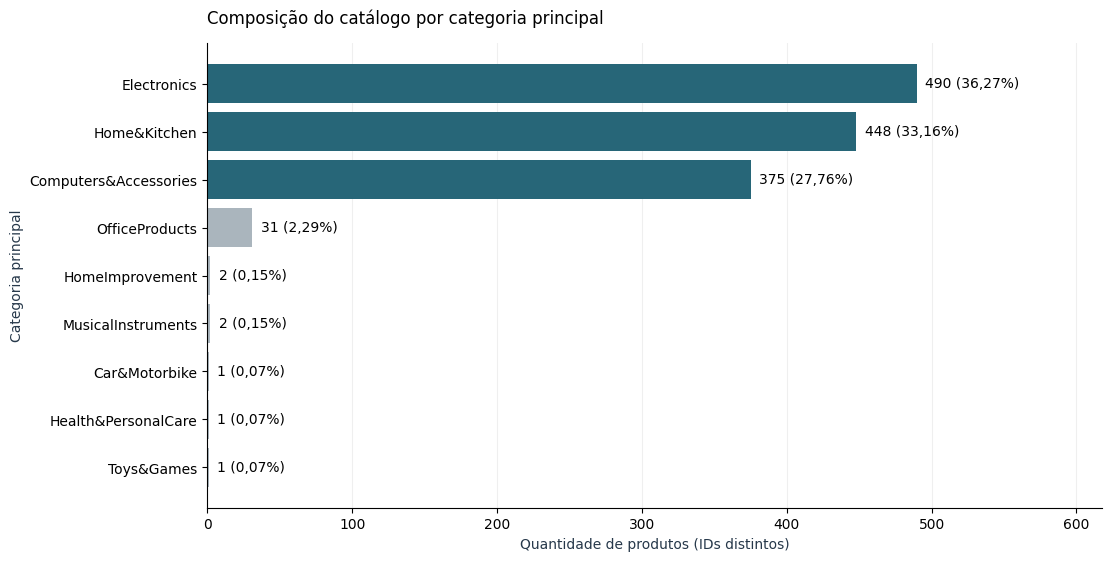

In [4]:
maiores_categorias = composicao.head(3)["categoria_nivel_1"]
cores = [
    "#276678" if categoria in maiores_categorias.values else "#AAB5BD"
    for categoria in composicao["categoria_nivel_1"]
]
fig, ax = plt.subplots(figsize=(11, 5.5), layout="constrained")
barras = ax.barh(composicao["categoria_nivel_1"], composicao["produtos"], color=cores)
rotulos = [
    f"{quantidade} ({participacao:.2f}%)".replace(".", ",")
    for quantidade, participacao in zip(composicao["produtos"], composicao["participacao_pct"])
]
ax.bar_label(barras, labels=rotulos, padding=6, fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0, composicao["produtos"].max() * 1.26)
ax.set_title("Composição do catálogo por categoria principal", loc="left", pad=14)
ax.set_xlabel("Quantidade de produtos (IDs distintos)")
ax.set_ylabel("Categoria principal")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [5]:
total_maiores = composicao.head(3)["produtos"].sum()
total_demais = composicao.iloc[3:]["produtos"].sum()

Electronics reúne **490 produtos (36,27%)**, Home&Kitchen, **448 (33,16%)**, e Computers&Accessories, **375 (27,76%)**. Juntas, representam **97,19%** dos IDs. Portanto, qualquer indicador geral calculado posteriormente será fortemente influenciado pela composição dessas três categorias.

Os outros 38 produtos estão distribuídos por seis categorias. OfficeProducts responde por 31 deles (2,29% do catálogo), enquanto cada uma das cinco restantes possui apenas um ou dois IDs. Sua presença amplia a variedade de rótulos, mas oferece pouca base para caracterizar uma distribuição interna.

A concentração observada orienta o detalhamento das categorias maiores. Ela não demonstra demanda, preferência dos consumidores ou oportunidade de expansão nas categorias pequenas: sua baixa presença pode decorrer da cobertura da fonte.

### 2.2 — Como se divide o catálogo dentro das categorias?

Cada subcategoria é identificada pelo par topo–nível 2. O caminho completo preserva ramos com folhas de mesmo nome.

In [6]:
profundidade = produtos[niveis].notna().sum(axis=1)
distribuicao_profundidade = (
    profundidade.value_counts().sort_index()
    .rename_axis("Níveis preenchidos").rename("Produtos").reset_index()
)
distribuicao_profundidade["Participação no catálogo (%)"] = (
    distribuicao_profundidade["Produtos"] / len(produtos) * 100
)
display(
    distribuicao_profundidade.style.hide(axis="index")
    .format(precision=2, decimal=",", thousands=".")
)

Níveis preenchidos,Produtos,Participação no catálogo (%)
2,8,"0,59"
3,142,"10,51"
4,759,"56,18"
5,357,"26,42"
6,72,"5,33"
7,13,"0,96"


Os caminhos variam de **dois a sete níveis**. Há 759 produtos com quatro níveis e 357 com cinco, somando **82,61%** do catálogo. Os oito caminhos que terminam no segundo nível não estão sem categoria; apenas não possuem subdivisões adicionais na fonte.

Como todos os produtos têm segundo nível, esse é um ponto comum para aprofundar a composição. As comparações seguintes mantêm a categoria principal junto da subcategoria. A profundidade descreve a organização da fonte, sem medir complexidade ou qualidade do produto.

In [7]:
subcategorias = (
    produtos.groupby(["categoria_nivel_1", "categoria_nivel_2"])["product_id"].nunique()
    .rename("produtos").reset_index()
)
subcategorias["participacao_na_categoria_pct"] = (
    subcategorias["produtos"]
    / subcategorias.groupby("categoria_nivel_1")["produtos"].transform("sum") * 100
)
subcategorias["participacao_no_catalogo_pct"] = subcategorias["produtos"] / len(produtos) * 100
destaques_subcategorias = (
    subcategorias.loc[subcategorias["categoria_nivel_1"].isin(maiores_categorias)]
    .sort_values(["categoria_nivel_1", "produtos", "categoria_nivel_2"], ascending=[True, False, True])
    .groupby("categoria_nivel_1", sort=False).head(3)
)
display(
    destaques_subcategorias.rename(columns={
        "categoria_nivel_1": "Categoria principal", "categoria_nivel_2": "Subcategoria (nível 2)",
        "produtos": "Produtos", "participacao_na_categoria_pct": "Na categoria (%)",
        "participacao_no_catalogo_pct": "No catálogo (%)",
    }).style.hide(axis="index").format(precision=2, decimal=",", thousands=".")
)

Categoria principal,Subcategoria (nível 2),Produtos,Na categoria (%),No catálogo (%)
Computers&Accessories,Accessories&Peripherals,307,"81,87","22,72"
Computers&Accessories,NetworkingDevices,30,"8,00","2,22"
Computers&Accessories,ExternalDevices&DataStorage,18,"4,80","1,33"
Electronics,"HomeTheater,TV&Video",156,"31,84","11,55"
Electronics,Mobiles&Accessories,151,"30,82","11,18"
Electronics,"Headphones,Earbuds&Accessories",63,"12,86","4,66"
Home&Kitchen,Kitchen&HomeAppliances,308,"68,75","22,80"
Home&Kitchen,"Heating,Cooling&AirQuality",116,"25,89","8,59"
Home&Kitchen,HomeStorage&Organization,16,"3,57","1,18"


Em Computers&Accessories, **Accessories&Peripherals concentra 307 dos 375 produtos (81,87%)**. Em Home&Kitchen, **Kitchen&HomeAppliances reúne 308 dos 448 (68,75%)**. Essas duas subcategorias têm praticamente a mesma quantidade absoluta, mas pesos internos diferentes: a primeira concentra uma parcela maior de sua categoria principal.

Electronics apresenta uma divisão menos concentrada na subcategoria líder: HomeTheater,TV&Video tem **156 produtos (31,84%)** e Mobiles&Accessories, **151 (30,82%)**. Juntas, reúnem 62,65% da categoria, enquanto o restante se distribui entre outras subdivisões.

Assim, o nome da categoria principal pode esconder composições distintas. Uma futura comparação de preços entre categorias deverá considerar esse mix. Por enquanto, não há evidência sobre preço, desconto ou desempenho; as quantidades apenas mostram quais tipos de produto estão mais representados.

In [8]:
composicao_interna = subcategorias.groupby(topo).agg(
    Ramos=("produtos", "size"), Maior_ramo_pct=("participacao_na_categoria_pct", "max"),
    Ramos_com_menos_de_30=("produtos", lambda s: s.lt(30).sum()),
    Produtos_em_ramos_pequenos=("produtos", lambda s: s[s.lt(30)].sum()))
composicao_interna["Caminhos completos"] = produtos.groupby(topo).category_original.nunique()
display(composicao_interna.sort_values("Caminhos completos", ascending=False).round(2))

,Ramos,Maior_ramo_pct,Ramos_com_menos_de_30,Produtos_em_ramos_pequenos,Caminhos completos
categoria_nivel_1,,,,,
Home&Kitchen,5,68.75,3,24,72
Electronics,9,31.84,5,58,62
Computers&Accessories,8,81.87,6,38,57
OfficeProducts,2,87.10,2,31,14
HomeImprovement,1,100.00,1,2,2
Car&Motorbike,1,100.00,1,1,1
Health&PersonalCare,1,100.00,1,1,1
MusicalInstruments,1,100.00,1,2,1
Toys&Games,1,100.00,1,1,1


### 2.3 — Quais ramos reúnem produtos com funções distintas?

Abrimos os dois maiores ramos de nível 2 para identificar o que os totais agregam.

In [9]:
maiores_subcategorias = (
    subcategorias.sort_values(
        ["produtos", "categoria_nivel_1", "categoria_nivel_2"], ascending=[False, True, True]
    ).head(2)[["categoria_nivel_1", "categoria_nivel_2"]]
)
recorte_nivel_3 = produtos.merge(
    maiores_subcategorias, on=["categoria_nivel_1", "categoria_nivel_2"],
    how="inner", validate="many_to_one",
)
detalhe_nivel_3 = (
    recorte_nivel_3.groupby(niveis[:3], dropna=False)["product_id"].nunique()
    .rename("produtos").reset_index()
)
detalhe_nivel_3["participacao_na_subcategoria_pct"] = (
    detalhe_nivel_3["produtos"]
    / detalhe_nivel_3.groupby(niveis[:2])["produtos"].transform("sum") * 100
)
destaques_nivel_3 = (
    detalhe_nivel_3.sort_values(niveis[:2] + ["produtos"], ascending=[True, True, False])
    .groupby(niveis[:2], sort=False).head(2)
)
display(
    destaques_nivel_3.rename(columns={
        "categoria_nivel_1": "Categoria principal", "categoria_nivel_2": "Nível 2",
        "categoria_nivel_3": "Nível 3", "produtos": "Produtos",
        "participacao_na_subcategoria_pct": "No respectivo nível 2 (%)",
    }).style.hide(axis="index").format(precision=2, decimal=",", thousands=".", na_rep="—")
)

Categoria principal,Nível 2,Nível 3,Produtos,No respectivo nível 2 (%)
Computers&Accessories,Accessories&Peripherals,Cables&Accessories,167,"54,40"
Computers&Accessories,Accessories&Peripherals,"Keyboards,Mice&InputDevices",60,"19,54"
Home&Kitchen,Kitchen&HomeAppliances,SmallKitchenAppliances,181,"58,77"
Home&Kitchen,Kitchen&HomeAppliances,"Vacuum,Cleaning&Ironing",82,"26,62"


Dentro de Accessories&Peripherals, **Cables&Accessories reúne 167 produtos (54,40%)**, seguido por Keyboards,Mice&InputDevices, com **60 (19,54%)**. Portanto, a grande presença de Computers&Accessories está fortemente ligada a acessórios, e não autoriza interpretar a categoria como um conjunto predominantemente de computadores completos.

Em Kitchen&HomeAppliances, **SmallKitchenAppliances reúne 181 produtos (58,77%)** e Vacuum,Cleaning&Ironing, **82 (26,62%)**. Esse detalhamento mostra que os dois grandes conjuntos do segundo nível têm composições específicas, embora suas quantidades totais sejam quase iguais.

Os nomes são classificações da fonte, não uma classificação funcional revisada produto a produto. O recorte ajuda a definir comparações futuras mais contextualizadas; não permite concluir que uma subdivisão vende mais ou oferece maior retorno.

### 2.4 — O grão altera a participação das categorias?

Comparamos os mesmos IDs em duas unidades de contagem para verificar o efeito das ocorrências repetidas.

In [10]:
ocorrencias = fontes_atuais["ocorrencias_base"][["ocorrencia_id","product_id","category"]].copy()
assert ocorrencias["ocorrencia_id"].notna().all() and ocorrencias["ocorrencia_id"].is_unique
assert set(ocorrencias["product_id"]) == set(produtos["product_id"])
categorias_por_produto = ocorrencias.groupby("product_id")["category"].nunique(dropna=False)
assert categorias_por_produto.eq(1).all()

referencias_categoria = ocorrencias.merge(
    produtos[["product_id", "category_original", "quantidade_observacoes"]],
    on="product_id", validate="many_to_one",
)
assert referencias_categoria["category"].eq(referencias_categoria["category_original"]).all()
contagens_por_produto = ocorrencias.groupby("product_id").size()
assert produtos.set_index("product_id")["quantidade_observacoes"].eq(contagens_por_produto).all()

# Coluna derivada apenas em memória, para a comparação entre unidades.
ocorrencias["categoria_nivel_1"] = ocorrencias["category"].str.split("|", regex=False).str[0]
print(f"Foram lidas {len(ocorrencias)} ocorrências dos mesmos {ocorrencias['product_id'].nunique()} produtos.")
print(f"Produtos com mais de uma ocorrência: {contagens_por_produto.gt(1).sum()}.")

Foram lidas 1465 ocorrências dos mesmos 1351 produtos.
Produtos com mais de uma ocorrência: 92.


In [11]:
contagem_ocorrencias = (
    ocorrencias.groupby("categoria_nivel_1").size().rename("ocorrencias").reset_index()
)
comparacao = composicao.merge(contagem_ocorrencias, on="categoria_nivel_1", validate="one_to_one")
comparacao["ocorrencias_adicionais"] = comparacao["ocorrencias"] - comparacao["produtos"]
comparacao["participacao_ocorrencias_pct"] = comparacao["ocorrencias"] / len(ocorrencias) * 100
comparacao["diferenca_pp"] = comparacao["participacao_ocorrencias_pct"] - comparacao["participacao_pct"]

display(
    comparacao[[
        "categoria_nivel_1", "produtos", "ocorrencias", "ocorrencias_adicionais",
        "participacao_pct", "participacao_ocorrencias_pct", "diferenca_pp",
    ]].rename(columns={
        "categoria_nivel_1": "Categoria principal", "produtos": "Produtos",
        "ocorrencias": "Ocorrências", "ocorrencias_adicionais": "Ocorrências adicionais",
        "participacao_pct": "Produtos (%)", "participacao_ocorrencias_pct": "Ocorrências (%)",
        "diferenca_pp": "Diferença (p.p.)",
    }).style.hide(axis="index").format(precision=2, decimal=",", thousands=".")
)

Categoria principal,Produtos,Ocorrências,Ocorrências adicionais,Produtos (%),Ocorrências (%),Diferença (p.p.)
Electronics,490,526,36,"36,27","35,90","-0,36"
Home&Kitchen,448,448,0,"33,16","30,58","-2,58"
Computers&Accessories,375,453,78,"27,76","30,92","3,16"
OfficeProducts,31,31,0,"2,29","2,12","-0,18"
HomeImprovement,2,2,0,"0,15","0,14","-0,01"
MusicalInstruments,2,2,0,"0,15","0,14","-0,01"
Car&Motorbike,1,1,0,"0,07","0,07","-0,01"
Health&PersonalCare,1,1,0,"0,07","0,07","-0,01"
Toys&Games,1,1,0,"0,07","0,07","-0,01"


Os **92 produtos com mais de uma ocorrência** explicam as 114 linhas adicionais: **78 em Computers&Accessories** e **36 em Electronics**. As categorias completas permanecem iguais nas ocorrências de cada ID; portanto, a diferença observada decorre da frequência de reaparição dos produtos.

Computers&Accessories passa de **375 produtos (27,76%)** para **453 ocorrências (30,92%)**, aumentando sua participação em **3,16 pontos percentuais**. Home&Kitchen mantém 448 registros, mas sua participação cai de **33,16% para 30,58%**, porque o denominador cresce. Pela contagem de ocorrências, Computers&Accessories ultrapassa Home&Kitchen; por IDs de produto, ocupa a terceira posição.

As duas contagens respondem a perguntas diferentes: composição de produtos distintos e composição de registros disponíveis. Para descrever o portfólio, mantém-se a primeira. A reaparição de um ID não demonstra mais vendas, demanda ou observações em diferentes datas.

### 2.5 — Onde há suporte para comparações internas?

Usamos 30 produtos como referência descritiva. O limiar define onde detalhar a comparação e não certifica representatividade.

In [12]:
contagem_n2 = produtos.groupby(["categoria_nivel_1", "categoria_nivel_2"]).size()
contagem_caminho = produtos.groupby("category_original").size()
cobertura_grupos = pd.DataFrame([
    {"Nível": nome, "Grupos totais": len(s), "Grupos com n ≥ 30": int(s.ge(30).sum()),
     "Produtos cobertos": int(s[s.ge(30)].sum()), "Universo": len(produtos),
     "Cobertura (%)": 100*s[s.ge(30)].sum()/len(produtos)}
    for nome,s in [("Topo + nível 2",contagem_n2),("Caminho completo",contagem_caminho)]
])
display(cobertura_grupos.style.hide(axis="index").format(precision=2,decimal=",",thousands="."))
assert (len(produtos), len(composicao), len(contagem_caminho), int(total_maiores)) == (1351,9,211,1313)
assert contagem_n2.ge(30).sum()==8 and contagem_caminho.ge(30).sum()==6

Nível,Grupos totais,Grupos com n ≥ 30,Produtos cobertos,Universo,Cobertura (%)
Topo + nível 2,29,8,1.193,1.351,"88,30"
Caminho completo,211,6,451,1.351,"33,38"


Os oito grupos de nível 2 cobrem **1.193/1.351 produtos (88,30%)**; os seis caminhos completos elegíveis cobrem apenas **451/1.351 (33,38%)**. Não são recortes equivalentes. Os demais produtos permanecem nos indicadores gerais. OfficeProducts (31 IDs) continua visível; categorias com um ou dois IDs descrevem casos. A concentração orienta aprofundamento, não expansão comercial: **hipótese a verificar em B** é que o mix interno acompanhe diferenças de preços. No BI, abrir um ramo deve manter seu contexto hierárquico e exibir o denominador.

A concentração justifica abrir os três maiores topos. Os ramos menores continuam no panorama comercial. A diferença de funções dentro de um mesmo ramo exige verificar também os níveis seguintes antes de interpretar preços.

O topo é adequado para dimensionar o portfólio. O nível 2 amplia a cobertura das comparações, enquanto nível 3 e caminho completo ajudam a separar funções dentro de ramos heterogêneos. A próxima etapa mede quando essa escolha muda a referência de preço.

## 3 — Preços, descontos e posicionamento comercial

### 3.1 — Onde se situa o preço típico?

Mediana e quartis descrevem o centro e a dispersão. Média, assimetria e extremos revelam a influência da cauda. A redução anunciada é calculada por produto.

In [13]:
precos = produtos.copy()
precos[reducao] = precos[original_inr] - precos[preco_inr]

def descrever(base, campos):
    d = base[campos].astype(float)
    r = d.describe(percentiles=[.05, .25, .5, .75, .95])
    r.loc["IIQ"] = r.loc["75%"] - r.loc["25%"]
    r.loc["Amplitude"] = r.loc["max"] - r.loc["min"]
    r.loc["Assimetria"] = d.skew()
    return r.rename(index={"count": "n", "mean": "Média", "std": "Desvio-padrão", "25%": "Q1",
                           "50%": "Mediana", "75%": "Q3", "min": "Mínimo", "max": "Máximo"}).rename(columns=rotulos_medidas)
resumo_precos = descrever(precos, [original_inr, preco_inr, reducao])
display(resumo_precos.round(2))

,Original (INR),Com desconto (INR),Redução (INR)
n,1351.00,1351.00,1351.00
Média,5690.51,3304.80,2385.71
Desvio-padrão,11218.92,7173.98,4736.60
Mínimo,39.00,39.00,0.00
5%,300.00,144.00,30.00
Q1,899.00,349.00,380.00
Mediana,1790.00,899.00,801.00
Q3,4575.00,2174.00,2000.00
95%,24999.00,16249.00,9995.50
Máximo,139900.00,77990.00,61910.00


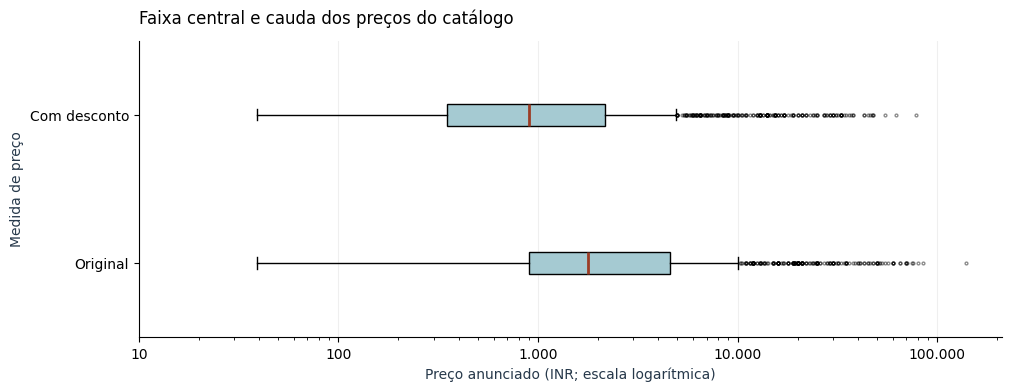

In [14]:
fig_precos, ax_precos = plt.subplots(figsize=(10, 3.8), layout="constrained")
ax_precos.boxplot(
    [precos[coluna].to_numpy(dtype=float) for coluna in medidas_preco[:2]],
    orientation="horizontal", tick_labels=["Original", "Com desconto"],
    showfliers=True, patch_artist=True,
    boxprops={"facecolor": "#A5CAD2"}, medianprops={"color": "#9C3C25", "linewidth": 2},
    flierprops={"marker": ".", "markersize": 4, "alpha": 0.45},
)
ax_precos.set_xscale("log")
ax_precos.set_xticks([10, 100, 1000, 10000, 100000], ["10", "100", "1.000", "10.000", "100.000"])
ax_precos.set_xlabel("Preço anunciado (INR; escala logarítmica)")
ax_precos.set_ylabel("Medida de preço")
ax_precos.set_title("Faixa central e cauda dos preços do catálogo", loc="left", pad=12)
ax_precos.grid(axis="x", alpha=0.2)
ax_precos.spines[["top", "right"]].set_visible(False)
plt.show()

O preço original tem mediana de **INR 1.790,00**, frente à média de **INR 5.690,51**. Para o preço com desconto, a mediana é **INR 899,00** e a média, **INR 3.304,80**. A média é aproximadamente 3,2 vezes a mediana no primeiro caso e 3,7 vezes no segundo: descreve o valor médio do conjunto, mas fica distante do centro de sua distribuição.

Metade dos preços com desconto está entre **INR 349,00 e INR 2.174,00** (IIQ de INR 1.825,00), enquanto o máximo chega a **INR 77.990,00**. O preço original máximo é INR 139.900,00. A cauda longa à direita e o desvio-padrão elevado justificam priorizar mediana e quartis nas comparações seguintes.

No gráfico, intervalos iguais entre as marcas principais representam multiplicações por dez. As caixas e os limites de 1,5 IIQ são calculados nos valores originais; a escala logarítmica altera apenas a apresentação. Todos os produtos participam, inclusive os pontos além dos limites dos boxplots. Esses pontos não são, por si, erros. A distribuição agrega tipos de produto diferentes, sem representar uma faixa de preços de bens equivalentes.

### 3.2 — Qual é a diferença entre categorias?

Comparamos os intervalos centrais e situamos os preços com desconto nas mesmas faixas em todos os topos. Os cortes são os quartis do catálogo e permanecem fixos na comparação.

In [15]:
precos_categoria = precos.groupby("categoria_nivel_1").agg(
    Produtos=("product_id", "size"),
    Original_mediana_INR=("actual_price_num", "median"),
    Com_desconto_mediana_INR=("discounted_price_num", "median"),
    Com_desconto_Q1_INR=("discounted_price_num", lambda valores: valores.quantile(0.25)),
    Com_desconto_Q3_INR=("discounted_price_num", lambda valores: valores.quantile(0.75)),
).sort_values("Produtos", ascending=False)
display(
    precos_categoria.rename_axis("Categoria principal").rename(columns={
        "Original_mediana_INR": "Mediana original (INR)",
        "Com_desconto_mediana_INR": "Mediana com desconto (INR)",
        "Com_desconto_Q1_INR": "Q1 com desconto (INR)",
        "Com_desconto_Q3_INR": "Q3 com desconto (INR)",
    }).style.format(precision=2, decimal=",", thousands=".")
)

,Produtos,Mediana original (INR),Mediana com desconto (INR),Q1 com desconto (INR),Q3 com desconto (INR)
Categoria principal,,,,,
Electronics,490,"2.999,00","1.384,00","399,00","7.998,75"
Home&Kitchen,448,"2.000,00","1.199,00","632,50","2.695,75"
Computers&Accessories,375,"999,00","399,00","249,00","849,00"
OfficeProducts,31,"210,00","178,00","117,00","380,50"
MusicalInstruments,2,"1.347,00","638,00","558,00","718,00"
HomeImprovement,2,"799,00","337,00","293,00","381,00"
Car&Motorbike,1,"4.000,00","2.339,00","2.339,00","2.339,00"
Health&PersonalCare,1,"1.900,00","899,00","899,00","899,00"
Toys&Games,1,"150,00","150,00","150,00","150,00"


Electronics, com **490 produtos**, tem a maior mediana de preço com desconto entre as três categorias principais: **INR 1.384,00**, seguida por Home&Kitchen (**448; INR 1.199,00**) e Computers&Accessories (**375; INR 399,00**). As medianas originais são, respectivamente, INR 2.999,00, INR 2.000,00 e INR 999,00.

A diferença mais marcante está na dispersão: a metade central de Electronics vai de **INR 399,00 a INR 7.998,75**, um intervalo muito mais amplo que o de Home&Kitchen (INR 632,50 a INR 2.695,75) e Computers&Accessories (INR 249,00 a INR 849,00). Comparar somente as medianas esconderia essa heterogeneidade.

OfficeProducts tem 31 produtos e mediana com desconto de INR 178,00; as cinco categorias restantes possuem somente um ou dois produtos cada. Seus valores são descritivos desses poucos registros. As diferenças de nível de preço não constituem classificação de desempenho ou atratividade comercial e exigem considerar a composição das categorias.

In [16]:
precos["faixa_preco_descontado"], cortes_preco_descontado = pd.qcut(
    precos[preco_inr], 4, retbins=True)
faixas_por_categoria = pd.crosstab(precos[topo], precos.faixa_preco_descontado, normalize="index").mul(100)
display(faixas_por_categoria.round(1))

faixa_preco_descontado,"(38.999, 349.0]","(349.0, 899.0]","(899.0, 2174.0]","(2174.0, 77990.0]"
categoria_nivel_1,,,,
Car&Motorbike,0.0,0.0,0.0,100.0
Computers&Accessories,45.1,32.0,17.1,5.9
Electronics,21.6,19.0,23.5,35.9
Health&PersonalCare,0.0,100.0,0.0,0.0
Home&Kitchen,12.9,24.3,31.7,31.0
HomeImprovement,50.0,50.0,0.0,0.0
MusicalInstruments,0.0,100.0,0.0,0.0
OfficeProducts,74.2,19.4,6.5,0.0
Toys&Games,100.0,0.0,0.0,0.0


### 3.3 — O que a mediana do topo esconde?

Comparamos os ramos com suporte e abrimos o ramo de maior intervalo interquartil de preço com desconto.

In [17]:
precos_subcategoria = (
    precos.loc[precos["categoria_nivel_1"].isin(maiores_categorias)]
    .groupby(["categoria_nivel_1", "categoria_nivel_2"]).agg(
        Produtos=("product_id", "size"),
        Original_mediana_INR=("actual_price_num", "median"),
        Com_desconto_mediana_INR=("discounted_price_num", "median"),
        Com_desconto_Q1_INR=("discounted_price_num", lambda valores: valores.quantile(0.25)),
        Com_desconto_Q3_INR=("discounted_price_num", lambda valores: valores.quantile(0.75)),
    )
)
subcategorias_comparadas = precos_subcategoria.loc[precos_subcategoria["Produtos"].ge(30)]
display(
    subcategorias_comparadas.rename_axis(["Categoria principal", "Subcategoria (nível 2)"])
    .rename(columns={
        "Original_mediana_INR": "Mediana original (INR)",
        "Com_desconto_mediana_INR": "Mediana com desconto (INR)",
        "Com_desconto_Q1_INR": "Q1 com desconto (INR)", "Com_desconto_Q3_INR": "Q3 com desconto (INR)",
    }).style.format(precision=2, decimal=",", thousands=".")
)

Em Computers&Accessories, os **307 produtos de Accessories&Peripherals** têm mediana com desconto de **INR 349,00**, enquanto os **30 de NetworkingDevices** chegam a **INR 1.199,00**. O peso dos acessórios observado anteriormente ajuda a contextualizar a mediana mais baixa da categoria como um todo.

Em Home&Kitchen, Kitchen&HomeAppliances (**308 produtos**) tem mediana de **INR 1.199,00**, abaixo de Heating,Cooling&AirQuality (**116; INR 1.970,92**). Em Electronics, Mobiles&Accessories (**151; INR 2.025,00**) e WearableTechnology (**62; INR 1.999,00**) apresentam medianas próximas, mas quartis muito distintos: INR 481,50–13.499,00 e INR 1.524,00–2.499,00, respectivamente.

HomeTheater,TV&Video reúne 156 produtos e tem o maior IIQ do preço com desconto entre os caminhos selecionados: **INR 15.900,00**, com Q1 de INR 349,00 e Q3 de INR 16.249,00. Sua mediana de INR 1.294,00 não deve ser interpretada como preço típico de uma televisão. A consulta seguinte aprofunda esse caminho, selecionado pela maior dispersão central.

In [18]:
intervalos_subcategoria = (
    subcategorias_comparadas["Com_desconto_Q3_INR"]
    - subcategorias_comparadas["Com_desconto_Q1_INR"]
)
caminho_disperso = intervalos_subcategoria.idxmax()
composicao_caminho = (
    precos.loc[
        precos["categoria_nivel_1"].eq(caminho_disperso[0])
        & precos["categoria_nivel_2"].eq(caminho_disperso[1])
    ].groupby("categoria_nivel_3", dropna=False).agg(
        Produtos=("product_id", "size"),
        Mediana_com_desconto_INR=("discounted_price_num", "median"),
    ).sort_values("Produtos", ascending=False)
)
print("Caminho de maior IIQ:", " > ".join(caminho_disperso))
display(
    composicao_caminho.rename_axis("Subdivisão (nível 3)")
    .rename(columns={"Mediana_com_desconto_INR": "Mediana com desconto (INR)"})
    .style.format(precision=2, decimal=",", thousands=".")
)

Caminho de maior IIQ: Electronics > HomeTheater,TV&Video


,Produtos,Mediana com desconto (INR)
Subdivisão (nível 3),,
Accessories,83,"349,00"
Televisions,66,"21.490,00"
Projectors,3,"9.490,00"
SatelliteEquipment,3,"1.249,00"
AVReceivers&Amplifiers,1,"1.990,00"


Nesse caminho, **Accessories possui 83 produtos e mediana de INR 349,00**, enquanto **Televisions possui 66 e mediana de INR 21.490,00**. Os outros sete produtos se distribuem entre três subdivisões menores.

O contraste mostra como um mesmo segundo nível pode reunir bens de funções e preços distintos. Essa composição oferece contexto para a dispersão observada, sem demonstrar causalidade nem homogeneidade dentro de cada subdivisão. Comparações comerciais posteriores precisam preservar o caminho da categoria e reconhecer que os produtos não são substitutos equivalentes.

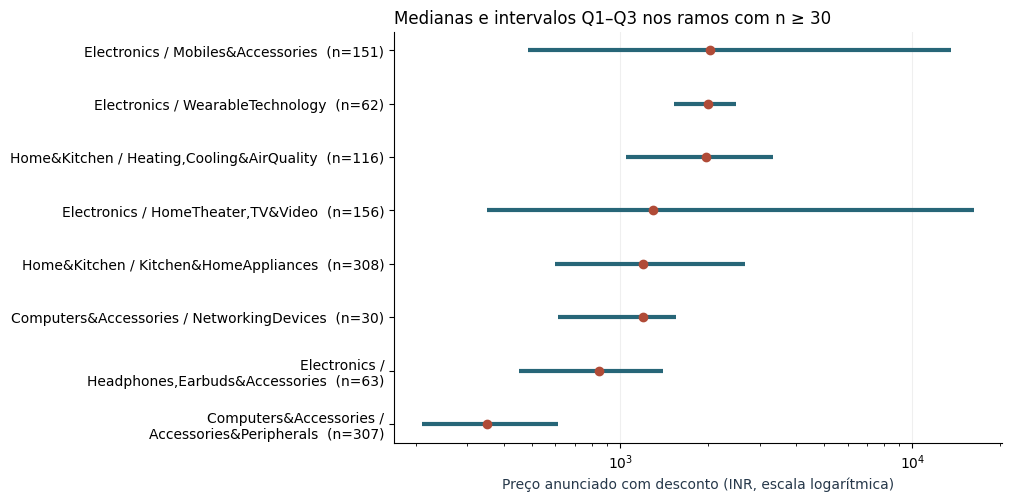

In [19]:
import textwrap
ordem_preco = subcategorias_comparadas.sort_values("Com_desconto_mediana_INR")
centro = ordem_preco.Com_desconto_mediana_INR.to_numpy(dtype=float)
q1 = ordem_preco.Com_desconto_Q1_INR.to_numpy(dtype=float)
q3 = ordem_preco.Com_desconto_Q3_INR.to_numpy(dtype=float)
y = np.arange(len(ordem_preco))
fig, ax = plt.subplots(figsize=(10, 4.9), layout="constrained")
ax.hlines(y, q1, q3, color="#276678", linewidth=3)
ax.scatter(centro, y, color="#b04b37", zorder=3)
ax.set_yticks(y, [textwrap.fill(" / ".join(k), 43) + f"  (n={n})"
                  for k,n in zip(ordem_preco.index, ordem_preco.Produtos)])
ax.set(xscale="log", xlabel="Preço anunciado com desconto (INR, escala logarítmica)")
ax.set_title("Medianas e intervalos Q1–Q3 nos ramos com n ≥ 30", loc="left")
ax.grid(axis="x", alpha=.2)
plt.show()

In [20]:
ramo_disperso = precos.loc[precos[topo].eq(caminho_disperso[0]) & precos[ramo[1]].eq(caminho_disperso[1])]
exemplos_funcao = ramo_disperso.loc[ramo_disperso[niveis[2]].isin(["Accessories", "Televisions"])].copy()
exemplos_funcao["Distância da mediana"] = (exemplos_funcao[preco_inr] -
    exemplos_funcao.groupby(niveis[2])[preco_inr].transform("median")).abs()
display(exemplos_funcao.sort_values(["Distância da mediana", "product_id"]).groupby(niveis[2]).head(1)
        .set_index("product_id")[["product_name", "category_original", preco_inr]].rename(columns=rotulos_medidas))

,product_name,category_original,Com desconto (INR)
product_id,,,
B098LCVYPW,Dealfreez Case Compatible for Fire TV Stick 4K...,"Electronics|HomeTheater,TV&Video|Accessories|R...",349.0
B099K9ZX65,Hisense 108 cm (43 inches) 4K Ultra HD Smart C...,"Electronics|HomeTheater,TV&Video|Televisions|S...",20990.0


In [21]:
# Comparar divisões funcionais com suporte dentro de cada ramo.
funcoes = precos.dropna(subset=[niveis[2]]).groupby(niveis[:3]).agg(
    n=("product_id","size"), mediana=(preco_inr,"median"),
    Q1=(preco_inr,lambda s:s.quantile(.25)), Q3=(preco_inr,lambda s:s.quantile(.75)))
suporte_funcoes = funcoes.loc[funcoes.n.ge(30)].copy()
amplitudes = suporte_funcoes.groupby(level=[0,1]).mediana.agg(["size","min","max"])
amplitudes = amplitudes.loc[amplitudes["size"].ge(2)].assign(
    razao=lambda d:d["max"]/d["min"]).sort_values("razao",ascending=False)
display(amplitudes.rename(columns={"size":"Funções comparáveis","min":"Menor mediana INR",
                                   "max":"Maior mediana INR","razao":"Razão"}).round(2))
display(suporte_funcoes.loc[suporte_funcoes.index.droplevel(2).isin(amplitudes.index)].round(2))

Funções comparáveis  \
categoria_nivel_1     categoria_nivel_2                                 
Electronics           HomeTheater,TV&Video                          2   
                      Mobiles&Accessories                           2   
Home&Kitchen          Heating,Cooling&AirQuality                    2   
Computers&Accessories Accessories&Peripherals                       3   
Home&Kitchen          Kitchen&HomeAppliances                        2   

                                                  Menor mediana INR  \
categoria_nivel_1     categoria_nivel_2                               
Electronics           HomeTheater,TV&Video                    349.0   
                      Mobiles&Accessories                     436.5   
Home&Kitchen          Heating,Cooling&AirQuality             1324.0   
Computers&Accessories Accessories&Peripherals                 299.0   
Home&Kitchen          Kitchen&HomeAppliances                 1024.0   

                                                  Maior mediana INR  Razão  
categoria_nivel_1     categoria_nivel_2                                     
Electronics           HomeTheater,TV&Video                  21490.0  61.58  
                      Mobiles&Accessories                   12999.0  29.78  
Home&Kitchen          Heating,Cooling&AirQuality             2599.0   1.96  
Computers&Accessories Accessories&Peripherals                 499.0   1.67  
Home&Kitchen          Kitchen&HomeAppliances                 1290.0   1.26

n  \
categoria_nivel_1     categoria_nivel_2          categoria_nivel_3                  
Computers&Accessories Accessories&Peripherals    Cables&Accessories           167   
                                                 Keyboards,Mice&InputDevices   60   
                                                 LaptopAccessories             33   
Electronics           HomeTheater,TV&Video       Accessories                   83   
                                                 Televisions                   66   
                      Mobiles&Accessories        MobileAccessories             74   
                                                 Smartphones&BasicMobiles      77   
Home&Kitchen          Heating,Cooling&AirQuality RoomHeaters                   46   
                                                 WaterHeaters&Geysers          44   
                      Kitchen&HomeAppliances     SmallKitchenAppliances       181   
                                                 Vacuum,Cleaning&Ironing       82   

                                                                              mediana  \
categoria_nivel_1     categoria_nivel_2          categoria_nivel_3                      
Computers&Accessories Accessories&Peripherals    Cables&Accessories             299.0   
                                                 Keyboards,Mice&InputDevices    484.0   
                                                 LaptopAccessories              499.0   
Electronics           HomeTheater,TV&Video       Accessories                    349.0   
                                                 Televisions                  21490.0   
                      Mobiles&Accessories        MobileAccessories              436.5   
                                                 Smartphones&BasicMobiles     12999.0   
Home&Kitchen          Heating,Cooling&AirQuality RoomHeaters                   1324.0   
                                                 WaterHeaters&Geysers          2599.0   
                      Kitchen&HomeAppliances     SmallKitchenAppliances        1290.0   
                                                 Vacuum,Cleaning&Ironing       1024.0   

                                                                                    Q1  \
categoria_nivel_1     categoria_nivel_2          categoria_nivel_3                       
Computers&Accessories Accessories&Peripherals    Cables&Accessories              199.0   
                                                 Keyboards,Mice&InputDevices     286.5   
                                                 LaptopAccessories               299.0   
Electronics           HomeTheater,TV&Video       Accessories                     246.5   
                                                 Televisions                  12117.25   
                      Mobiles&Accessories        MobileAccessories               224.0   
                                                 Smartphones&BasicMobiles       8499.0   
Home&Kitchen          Heating,Cooling&AirQuality RoomHeaters                    983.75   
                                                 WaterHeaters&Geysers          1154.75   
                      Kitchen&HomeAppliances     SmallKitchenAppliances          699.0   
                                                 Vacuum,Cleaning&Ironing         499.0   

                                                                                    Q3  
categoria_nivel_1     categoria_nivel_2          categoria_nivel_3                      
Computers&Accessories Accessories&Peripherals    Cables&Accessories              399.0  
                                                 Keyboards,Mice&InputDevices    1024.0  
                                                 LaptopAccessories               770.0  
Electronics           HomeTheater,TV&Video       Accessories                     523.0  
                                                 Televisions                  31746.75  
                      

A diferença entre acessórios e telefones em Mobiles também é ampla: INR 436,50 (74 produtos) e INR 12.999 (77). Em Home&Kitchen, aquecedores de ambiente e de água têm medianas de INR 1.324 (46) e INR 2.599 (44). Use a divisão por função antes de avaliar se um preço destoa do grupo.

### 3.4 — Em que grupos os descontos são maiores?

O percentual é o informado na fonte. Usamos a distribuição e os quartis para identificar a concentração de descontos altos e verificar se ela depende do grupo.

In [22]:
resumo_descontos = precos["discount_percentage_num"].describe().rename(
    index={"count": "Produtos", "mean": "Média (%)", "std": "Desvio-padrão (p.p.)",
           "min": "Mínimo (%)", "25%": "Q1 (%)", "50%": "Mediana (%)", "75%": "Q3 (%)", "max": "Máximo (%)"}
).to_frame("Desconto anunciado")
display(
    resumo_descontos.style.format(precision=2, decimal=",", thousands=".")
    .format(precision=0, thousands=".", subset=pd.IndexSlice[["Produtos"], :])
)
sem_desconto = precos["discount_percentage_num"].eq(0)
print(f"Desconto percentual zero: {sem_desconto.sum()} produtos ({sem_desconto.mean():.2%}).")

,Desconto anunciado
Produtos,1.351
Média (%),"46,68"
Desvio-padrão (p.p.),"21,62"
Mínimo (%),"0,00"
Q1 (%),"31,00"
Mediana (%),"49,00"
Q3 (%),"62,00"
Máximo (%),"94,00"


Desconto percentual zero: 47 produtos (3.48%).


O desconto anunciado tem **mediana de 49%**, média de **46,68%** e metade central entre **31% e 62%**, com amplitude interquartil de 31 pontos percentuais. Os extremos vão de 0% a 94%. Há **47 produtos com desconto zero (3,48%)**, preservados no cálculo.

Percentuais elevados descrevem a distância relativa ao preço original anunciado. Sem histórico de preços ou dados de transações, não é possível avaliar a duração da oferta, a economia realizada ou se o preço original servia como referência efetiva de venda.

In [23]:
descontos_categoria = (
    precos.assign(sem_desconto=sem_desconto)
    .groupby("categoria_nivel_1").agg(
        Produtos=("product_id", "size"),
        Mediana_pct=("discount_percentage_num", "median"),
        Q1_pct=("discount_percentage_num", lambda valores: valores.quantile(0.25)),
        Q3_pct=("discount_percentage_num", lambda valores: valores.quantile(0.75)),
        Sem_desconto=("sem_desconto", "sum"),
        Sem_desconto_proporcao=("sem_desconto", "mean"),
    )
)
descontos_categoria["Sem_desconto_pct"] = descontos_categoria["Sem_desconto_proporcao"] * 100
display(
    descontos_categoria.loc[descontos_categoria["Produtos"].ge(30)]
    .drop(columns="Sem_desconto_proporcao").rename_axis("Categoria principal")
    .rename(columns={"Mediana_pct": "Mediana (%)", "Q1_pct": "Q1 (%)", "Q3_pct": "Q3 (%)",
                     "Sem_desconto": "Produtos com desconto zero", "Sem_desconto_pct": "Desconto zero (%)"})
    .style.format(precision=2, decimal=",", thousands=".")
)

,Produtos,Mediana (%),Q1 (%),Q3 (%),Produtos com desconto zero,Desconto zero (%)
Categoria principal,,,,,,
Computers&Accessories,375,"56,00","40,00","66,00",6,"1,60"
Electronics,490,"52,00","31,00","67,00",10,"2,04"
Home&Kitchen,448,"41,50","28,00","53,00",17,"3,79"
OfficeProducts,31,"5,00","0,00","17,50",13,"41,94"


A mediana é **56% em Computers&Accessories**, **52% em Electronics** e **41,5% em Home&Kitchen**. A distância entre Computers&Accessories e Home&Kitchen é de **14,5 pontos percentuais**, mas os intervalos interquartis se sobrepõem; o contraste não se aplica a todos os produtos.

OfficeProducts, com 31 produtos, apresenta mediana de **5%** e desconto zero em **13 casos (41,94%)**. É um perfil distinto no conjunto disponível, com base muito menor que as três categorias principais. Percentuais menores não indicam, isoladamente, preços finais menos competitivos.

In [24]:
descontos_subcategoria = precos.groupby(["categoria_nivel_1", "categoria_nivel_2"]).agg(
    Produtos=("product_id", "size"),
    Mediana_pct=("discount_percentage_num", "median"),
    Q1_pct=("discount_percentage_num", lambda valores: valores.quantile(0.25)),
    Q3_pct=("discount_percentage_num", lambda valores: valores.quantile(0.75)),
)
display(
    descontos_subcategoria.loc[subcategorias_comparadas.index]
    .rename_axis(["Categoria principal", "Subcategoria (nível 2)"])
    .rename(columns={"Mediana_pct": "Mediana (%)", "Q1_pct": "Q1 (%)", "Q3_pct": "Q3 (%)"})
    .style.format(precision=2, decimal=",", thousands=".")
)

Dentro de Electronics, **WearableTechnology (62 produtos) tem mediana de 75%**, contra **32% em Mobiles&Accessories (151)**: diferença de **43 pontos percentuais**. Seus preços com desconto medianos são próximos, mas os preços originais medianos são INR 7.990,00 e INR 3.499,00. O percentual, portanto, precisa ser lido junto do preço de referência e da composição dos grupos.

Em Computers&Accessories, Accessories&Peripherals (**307 produtos**) tem mediana de **60%**, enquanto NetworkingDevices (**30**) tem **44,5%**. Em Home&Kitchen, os dois grandes caminhos ficam próximos: **42,5%** em Kitchen&HomeAppliances (**308**) e **41%** em Heating,Cooling&AirQuality (**116**). Não há uma intensidade única de desconto que descreva igualmente cada categoria.

As medianas das colunas são calculadas separadamente: não correspondem necessariamente ao mesmo produto. Por isso, a razão entre medianas de preços não deve ser apresentada como a mediana dos descontos.

In [25]:
precos["faixa_preco_original"], limites_preco = pd.qcut(
    precos["actual_price_num"], q=4, labels=["F1", "F2", "F3", "F4"], retbins=True,
)
resumo_faixas = precos.groupby("faixa_preco_original", observed=True).agg(
    Produtos=("product_id", "size"),
    Mediana_desconto_pct=("discount_percentage_num", "median"),
    Q1_desconto_pct=("discount_percentage_num", lambda valores: valores.quantile(0.25)),
    Q3_desconto_pct=("discount_percentage_num", lambda valores: valores.quantile(0.75)),
    Mediana_diferenca_INR=("reducao_anunciada_inr", "median"),
)
resumo_faixas.insert(0, "Limite inferior (INR)", limites_preco[:-1])
resumo_faixas.insert(1, "Limite superior (INR)", limites_preco[1:])
display(
    resumo_faixas.rename_axis("Faixa").rename(columns={
        "Mediana_desconto_pct": "Mediana desconto (%)", "Q1_desconto_pct": "Q1 desconto (%)",
        "Q3_desconto_pct": "Q3 desconto (%)", "Mediana_diferenca_INR": "Mediana diferença (INR)",
    }).style.format(precision=2, decimal=",", thousands=".")
)

,Limite inferior (INR),Limite superior (INR),Produtos,Mediana desconto (%),Q1 desconto (%),Q3 desconto (%),Mediana diferença (INR)
Faixa,,,,,,,
F1,"39,00","899,00",345,"50,00","22,00","61,00","250,00"
F2,"899,00","1.790,00",331,"55,00","39,50","67,00","650,00"
F3,"1.790,00","4.575,00",337,"48,00","35,00","60,00","1.210,00"
F4,"4.575,00","139.900,00",338,"41,50","28,00","58,75","4.995,50"


Os cortes de preço original são **INR 899,00, INR 1.790,00 e INR 4.575,00**. As medianas do desconto nas quatro faixas são **50%, 55%, 48% e 41,5%**, respectivamente. A faixa mais cara tem mediana inferior à segunda em **13,5 pontos percentuais**, mas não há queda uniforme desde a primeira faixa, e os quartis apresentam sobreposição.

Ao mesmo tempo, a mediana da diferença monetária anunciada cresce de **INR 250,00** na primeira faixa para **INR 4.995,50** na última. Percentual menor pode coexistir com diferença em INR maior.

Esse resultado agregado pode refletir a composição das faixas. Para avaliar se o padrão é semelhante nas três categorias principais, a consulta seguinte conserva os mesmos cortes e apresenta contagem e mediana do desconto em cada cruzamento.

In [26]:
descontos_faixa_categoria = (
    precos.loc[precos["categoria_nivel_1"].isin(maiores_categorias)]
    .groupby(["categoria_nivel_1", "faixa_preco_original"], observed=True).agg(
        Produtos=("product_id", "size"),
        Mediana_desconto_pct=("discount_percentage_num", "median"),
    )
)
display(
    descontos_faixa_categoria.rename_axis(["Categoria principal", "Faixa de preço original"])
    .rename(columns={"Mediana_desconto_pct": "Mediana do desconto (%)"})
    .style.format(precision=2, decimal=",", thousands=".")
)

Em Electronics, as medianas por faixa são **56%, 60%, 60% e 40%**; em Computers&Accessories, **55%, 64%, 50% e 42%**. Já Home&Kitchen fica entre **40% e 43%**, sem o mesmo recuo na faixa superior.

A última faixa de Computers&Accessories contém somente **20 produtos**, ante 211 em Electronics e 107 em Home&Kitchen, o que limita sua comparação com grupos maiores. A associação entre faixa de preço e desconto varia por categoria e não sustenta uma regra geral de desconto crescente ou decrescente. O cruzamento é descritivo, não controla todas as diferenças entre produtos e não demonstra efeito do desconto sobre demanda.

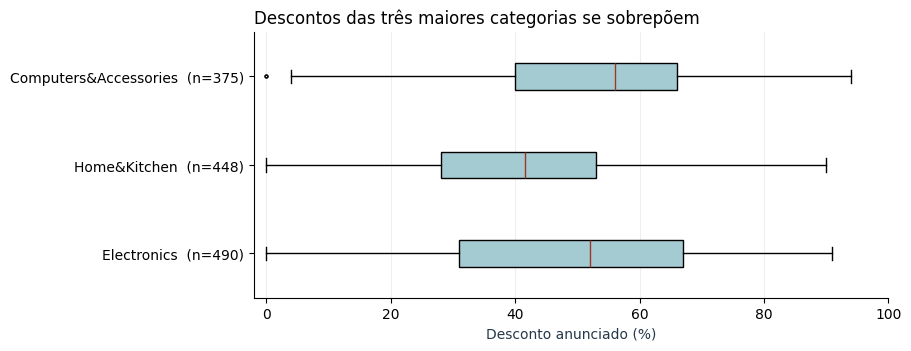

In [27]:
# A sobreposição mostra quanto do contraste subsiste além da mediana.
fig, ax = plt.subplots(figsize=(9,3.4),layout="constrained")
grupos_desc = [precos.loc[precos[topo].eq(t),percentual].astype(float) for t in maiores_categorias]
ax.boxplot(grupos_desc,orientation="horizontal",patch_artist=True,
           boxprops={"facecolor":"#a5cbd2"},medianprops={"color":"#9c3726"},
           flierprops={"markersize":2,"alpha":.4})
ax.set_yticks(range(1,len(grupos_desc)+1),
              [f"{t}  (n={len(s)})" for t,s in zip(maiores_categorias,grupos_desc)])
ax.set(xlabel="Desconto anunciado (%)",xlim=(-2,100))
ax.set_title("Descontos das três maiores categorias se sobrepõem",loc="left")
ax.grid(axis="x",alpha=.2)
plt.show()

### 3.5 — Percentual e redução em INR contam a mesma história?

A redução em INR resulta da diferença entre os dois preços anunciados do mesmo ID. O valor depende do nível de preço de referência.

In [28]:
precos["reducao_anunciada_inr"] = precos["actual_price_num"] - precos["discounted_price_num"]
maior_percentual = (
    precos.sort_values(
        ["discount_percentage_num", "reducao_anunciada_inr", "product_id"], ascending=[False, False, True]
    ).head(1).assign(Criterio="Maior percentual")
)
maior_diferenca = (
    precos.sort_values(["reducao_anunciada_inr", "product_id"], ascending=[False, True])
    .head(1).assign(Criterio="Maior diferença em INR")
)
exemplos_desconto = pd.concat([maior_percentual, maior_diferenca], ignore_index=True)
display(
    exemplos_desconto[["Criterio", "product_id", "product_name"] + medidas_preco + ["reducao_anunciada_inr"]]
    .rename(columns={
        "Criterio": "Critério", "product_id": "ID", "product_name": "Produto",
        "actual_price_num": "Original (INR)", "discounted_price_num": "Com desconto (INR)",
        "discount_percentage_num": "Desconto (%)", "reducao_anunciada_inr": "Diferença anunciada (INR)",
    }).style.hide(axis="index").format(precision=2, decimal=",", thousands=".")
    .set_properties(subset=["Produto"], **{"max-width": "280px", "white-space": "normal", "overflow-wrap": "anywhere"})
)

Critério,ID,Produto,Original (INR),Com desconto (INR),Desconto (%),Diferença anunciada (INR)
Maior percentual,B097C564GC,"rts [2 Pack] Mini USB C Type C Adapter Plug, Type C Female to USB A Male Charger Charging Cable Adapter Converter compatible for iPhone, Samsung S20 ultra/S21/S10/S8/S9/MacBook Pro iPad Silver","4.999,00","294,00","94,00","4.705,00"
Maior diferença em INR,B09WN3SRC7,Sony Bravia 164 cm (65 inches) 4K Ultra HD Smart LED Google TV KD-65X74K (Black),"139.900,00","77.990,00","44,00","61.910,00"


O adaptador **rts Mini USB C, pacote com duas unidades (B097C564GC)** tem desconto anunciado de **94%**, de INR 4.999,00 para INR 294,00: diferença de **INR 4.705,00**. Já a **Sony Bravia KD-65X74K de 65 polegadas (B09WN3SRC7)** apresenta **44%**, de INR 139.900,00 para INR 77.990,00, com diferença de **INR 61.910,00**. Este segundo produto também corresponde aos máximos de preço original e com desconto observados no panorama geral.

O maior percentual não coincide com a maior diferença monetária porque as bases de preço são diferentes. Esses valores permanecem na análise e não são classificados como erros apenas pela magnitude. O desconto nominal tampouco comprova economia obtida: são referências anunciadas de produtos diferentes, sem dados de compra.

In [29]:
reducao_anunciada = precos["reducao_anunciada_inr"]
display(pd.DataFrame({"Medida": ["Mediana da diferença por produto", "Diferença das medianas (outro cálculo)"],
    "INR": [reducao_anunciada.median(), precos.actual_price_num.median()-precos.discounted_price_num.median()],
    "Produtos": [len(precos),len(precos)]}).style.hide(axis="index").format(precision=2,decimal=",",thousands="."))
assert reducao_anunciada.median() == 801

Medida,INR,Produtos
Mediana da diferença por produto,"801,00",1.351
Diferença das medianas (outro cálculo),"891,00",1.351


A redução anunciada mediana é **INR 801**, contra INR 891 na diferença entre medianas. O KPI usa a primeira operação: comparar o preço original e o descontado do **mesmo ID**, antes de agregar. Não se trata de economia efetivamente realizada. Essa distinção deve ser reproduzida no futuro DAX.

### 3.6 — Qual é a associação entre preço e desconto?

Spearman compara postos médios em pares observados. A redução em INR contém o preço original na própria fórmula. A leitura dessa associação exige considerar essa dependência.

In [30]:
def spearman_observado(d, x, y, minimo=30):
    par = d[[x, y]].dropna().astype(float)
    rho = par.rank().corr().iloc[0, 1] if len(par) >= minimo and par.nunique().min() > 1 else np.nan
    return len(par), rho

pares_comerciais = [(original_inr, percentual), (original_inr, reducao), (preco_inr, percentual)]
grupos_topo = list(precos.groupby(topo, sort=True))
grupos_n2 = list(precos.groupby(ramo, sort=True))
grupos_catalogo = [("Catálogo", precos)]
grupos_associacao = grupos_catalogo + grupos_topo + [(" / ".join(chave), d) for chave, d in grupos_n2]

def quadro_spearman(grupos, pares, minimo=30):
    return pd.DataFrame([
        (grupo, f"{rotulos_medidas[x]} × {rotulos_medidas[y]}", *spearman_observado(d, x, y, minimo))
        for grupo, d in grupos for x, y in pares
    ], columns=["Grupo", "Relação", "n", "ρ"])

assoc_comercial = quadro_spearman(grupos_associacao, pares_comerciais)
display(assoc_comercial.loc[assoc_comercial.n.ge(30)].pivot(index="Grupo", columns="Relação", values=["ρ", "n"]).round(3))
print("Grupos com n abaixo de 30:", assoc_comercial.loc[assoc_comercial.n.lt(30), "Grupo"].nunique())

ρ  \
Relação                                         Com desconto (INR) × Desconto (%)   
Grupo                                                                               
Catálogo                                                                   -0.367   
Computers&Accessories                                                      -0.503   
Computers&Accessories / Accessories&Peripherals                            -0.467   
Computers&Accessories / NetworkingDevices                                  -0.173   
Electronics                                                                -0.479   
Electronics / Headphones,Earbuds&Accessories                               -0.118   
Electronics / HomeTheater,TV&Video                                         -0.657   
Electronics / Mobiles&Accessories                                          -0.766   
Electronics / WearableTechnology                                           -0.555   
Home&Kitchen                                                               -0.210   
Home&Kitchen / Heating,Cooling&AirQuality                                  -0.019   
Home&Kitchen / Kitchen&HomeAppliances                                      -0.312   
OfficeProducts                                                              0.078   

                                                                               \
Relação                                         Original (INR) × Desconto (%)   
Grupo                                                                           
Catálogo                                                               -0.066   
Computers&Accessories                                                  -0.048   
Computers&Accessories / Accessories&Peripherals                         0.056   
Computers&Accessories / NetworkingDevices                               0.120   
Electronics                                                            -0.238   
Electronics / Headphones,Earbuds&Accessories                            0.438   
Electronics / HomeTheater,TV&Video                                     -0.461   
Electronics / Mobiles&Accessories                                      -0.645   
Electronics / WearableTechnology                                        0.471   
Home&Kitchen                                                            0.068   
Home&Kitchen / Heating,Cooling&AirQuality                               0.279   
Home&Kitchen / Kitchen&HomeAppliances                                  -0.005   
OfficeProducts                                                          0.318   

                                                                                \
Relação                                         Original (INR) × Redução (INR)   
Grupo                                                                            
Catálogo                                                                 0.894   
Computers&Accessories                                                    0.874   
Computers&Accessories / Accessories&Peripherals                          0.863   
Computers&Accessories / NetworkingDevices                                0.969   
Electronics                                                              0.904   
Electronics / Headphones,Earbuds&Accessories                             0.951   
Electronics / HomeTheater,TV&Video                                       0.959   
Electronics / Mobiles&Accessories                                        0.809   
Electronics / WearableTechnology                                         0.922   
Home&Kitchen                                                             0.887   
Home&Kitchen / Heating,Cooling&AirQuality                                0.930   
Home&Kitchen / Kitchen&HomeAppliances                                    0.852   
OfficeProducts                                                           0.397   

                                                                                n  \
Relação                 

Grupos com n abaixo de 30: 26


No catálogo, preço original × percentual tem ρ = −0,066, contra −0,645 em Mobiles&Accessories e +0,471 em WearableTechnology. A associação de +0,894 entre preço original e redução em INR reflete em parte a definição da própria redução.

### 3.7 — O que muda ao comparar um valor extremo com seus pares?

Aplicamos os limites Q1 − 1,5 × IIQ e Q3 + 1,5 × IIQ ao catálogo, ao topo, ao nível 2 e ao caminho completo. Separamos ausência, n abaixo de 30 e IIQ zero. Os sinais mantêm todos os produtos na base.

In [31]:
referencias = precos[["product_id", "source_index_referencia", "criterio_selecao_referencia"]]
def avaliar_extremos(base, grupo, metodo):
    """Diagnóstico por ID/medida; não avaliado é diferente de não sinalizado."""
    resultados = []
    for medida in medidas_preco:
        d = base[["product_id", "category_original", "categoria_nivel_1", "categoria_nivel_2", medida, "universo"]].copy()
        g = d.groupby(grupo, dropna=False)[medida]
        d["n"] = g.transform("count")
        d["Q1"] = g.transform(lambda s: s.quantile(.25))
        d["Q3"] = g.transform(lambda s: s.quantile(.75))
        d["IIQ"] = d.Q3 - d.Q1
        d["inferior"] = d.Q1 - 1.5*d.IIQ
        d["superior"] = d.Q3 + 1.5*d.IIQ
        d["estado"] = "Avaliado: não sinalizado"
        sinal = d[medida].lt(d.inferior) | d[medida].gt(d.superior)
        d.loc[sinal, "estado"] = "Avaliado: sinalizado"
        d.loc[d.IIQ.eq(0), "estado"] = "Não avaliado: IIQ zero"
        d.loc[d.n.lt(30), "estado"] = "Não avaliado: n < 30"
        d.loc[d[medida].isna(), "estado"] = "Não avaliado: ausência"
        d["medida"], d["metodo"] = medida, metodo
        d["valor"] = d[medida]
        resultados.append(d.drop(columns=medida))
    return pd.concat(resultados, ignore_index=True)

precos["universo"] = "Catálogo"
extremos = pd.concat([
    avaliar_extremos(precos, ["universo"], "Catálogo"),
    avaliar_extremos(precos, [topo], "Categoria principal"),
    avaliar_extremos(precos, ["category_original"], "Caminho completo"),
    avaliar_extremos(precos, ["categoria_nivel_1", "categoria_nivel_2"], "Topo + nível 2")
], ignore_index=True)
estados_extremos = ["Avaliado: sinalizado", "Avaliado: não sinalizado", "Não avaliado: n < 30",
                   "Não avaliado: IIQ zero", "Não avaliado: ausência"]
resumo_extremos = pd.crosstab([extremos.metodo, extremos.medida], extremos.estado).reindex(columns=estados_extremos, fill_value=0)
assert resumo_extremos.sum(axis=1).eq(len(precos)).all()

display(resumo_extremos.rename(index=rotulos_medidas).T)
comparacao_extremos = extremos.pivot(index=["product_id","medida"], columns="metodo", values="estado")
linhas_sobreposicao = []
for medida, d in comparacao_extremos.groupby(level="medida"):
    comum = d[["Caminho completo","Topo + nível 2"]].apply(lambda s:s.str.startswith("Avaliado:" )).all(axis=1)
    sinal_c = d["Caminho completo"].eq("Avaliado: sinalizado")
    sinal_n = d["Topo + nível 2"].eq("Avaliado: sinalizado")
    linhas_sobreposicao.append({"Medida":rotulos_medidas[medida], "Avaliados em ambos":int(comum.sum()),
        "Sinal nos dois":int((comum & sinal_c & sinal_n).sum()),
        "Só caminho (ambos avaliados)":int((comum & sinal_c & ~sinal_n).sum()),
        "Só nível 2 (ambos avaliados)":int((comum & ~sinal_c & sinal_n).sum()),
        "Sinal nível 2 fora da cobertura caminho":int((~comum & sinal_n).sum())})
sobreposicao_extremos = pd.DataFrame(linhas_sobreposicao)
display(sobreposicao_extremos.set_index("Medida"))
# Um exemplo por medida: primeiro ID com discordância entre métodos efetivamente avaliados.
ambos_avaliados = comparacao_extremos[["Caminho completo","Topo + nível 2"]].apply(lambda s:s.str.startswith("Avaliado:")).all(axis=1)
divergentes = comparacao_extremos.loc[ambos_avaliados & comparacao_extremos["Caminho completo"].ne(comparacao_extremos["Topo + nível 2"])]
chaves_exemplo = divergentes.reset_index().sort_values("product_id").groupby("medida").head(1)[["product_id","medida"]]
exemplos_escala = extremos.merge(chaves_exemplo,on=["product_id","medida"],validate="many_to_one").merge(referencias,on="product_id",validate="many_to_one")
display(exemplos_escala[["product_id","medida","metodo","n","valor","Q1","Q3","inferior","superior","estado"]]
    .replace({"medida":rotulos_medidas}).style.hide(axis="index").format(precision=2,decimal=",",thousands=".")
    .set_properties(**{"max-width":"180px","white-space":"normal","overflow-wrap":"anywhere"}))
proveniencia_extremos = exemplos_escala[["product_id","category_original","source_index_referencia"]].drop_duplicates().merge(
    precos[["product_id"]+indicadores_preco],on="product_id",validate="one_to_one")
display(proveniencia_extremos.style.hide(axis="index").set_properties(**{"max-width":"310px","white-space":"normal","overflow-wrap":"anywhere"}))
# Conferência alternativa do primeiro exemplo, usando a interpolação explícita dos quantis.
import numpy as np
ex = exemplos_escala.iloc[0]
amostra = precos.loc[precos.category_original.eq(ex.category_original), ex.medida].dropna().astype(float)
linha_c = exemplos_escala.loc[exemplos_escala.product_id.eq(ex.product_id) & exemplos_escala.medida.eq(ex.medida) & exemplos_escala.metodo.eq("Caminho completo")].iloc[0]
assert np.allclose(np.quantile(amostra,[.25,.75]),[linha_c.Q1,linha_c.Q3])
assert resumo_extremos.loc["Caminho completo","Avaliado: sinalizado"].reindex(medidas_preco).tolist()==[34,49,18]
assert resumo_extremos.loc["Caminho completo","Não avaliado: n < 30"].eq(900).all()

metodo                   Caminho completo                                  \
medida                     Original (INR) Desconto (%) Com desconto (INR)   
estado                                                                      
Avaliado: sinalizado                   34           18                 49   
Avaliado: não sinalizado              417          433                402   
Não avaliado: n < 30                  900          900                900   
Não avaliado: IIQ zero                  0            0                  0   
Não avaliado: ausência                  0            0                  0   

metodo                   Categoria principal                                  \
medida                        Original (INR) Desconto (%) Com desconto (INR)   
estado                                                                         
Avaliado: sinalizado                     119            9                132   
Avaliado: não sinalizado                1225         1335               1212   
Não avaliado: n < 30                       7            7                  7   
Não avaliado: IIQ zero                     0            0                  0   
Não avaliado: ausência                     0            0                  0   

metodo                         Catálogo                                  \
medida                   Original (INR) Desconto (%) Com desconto (INR)   
estado                                                                    
Avaliado: sinalizado                185            0                209   
Avaliado: não sinalizado           1166         1351               1142   
Não avaliado: n < 30                  0            0                  0   
Não avaliado: IIQ zero                0            0                  0   
Não avaliado: ausência                0            0                  0   

metodo                   Topo + nível 2                                  
medida                   Original (INR) Desconto (%) Com desconto (INR)  
estado                                                                   
Avaliado: sinalizado                 85           14                 96  
Avaliado: não sinalizado           1108         1179               1097  
Não avaliado: n < 30                158          158                158  
Não avaliado: IIQ zero                0            0                  0  
Não avaliado: ausência                0            0                  0

,Avaliados em ambos,Sinal nos dois,Só caminho (ambos avaliados),Só nível 2 (ambos avaliados),Sinal nível 2 fora da cobertura caminho
Medida,,,,,
Original (INR),451,14,20,2,69
Desconto (%),451,8,10,0,6
Com desconto (INR),451,19,30,6,71


product_id,medida,metodo,n,valor,Q1,Q3,inferior,superior,estado
B07DC4RZPY,Original (INR),Catálogo,1.351,"1.999,00","899,00","4.575,00","-4.615,00","10.089,00",Avaliado: não sinalizado
B0162K34H2,Com desconto (INR),Catálogo,1.351,"849,00","349,00","2.174,00","-2.388,50","4.911,50",Avaliado: não sinalizado
B0162K34H2,Desconto (%),Catálogo,1.351,"15,00","31,00","62,00","-15,50","108,50",Avaliado: não sinalizado
B07DC4RZPY,Original (INR),Categoria principal,375,"1.999,00","682,50","1.854,00","-1.074,75","3.611,25",Avaliado: não sinalizado
B0162K34H2,Com desconto (INR),Categoria principal,375,"849,00","249,00","849,00","-651,00","1.749,00",Avaliado: não sinalizado
B0162K34H2,Desconto (%),Categoria principal,375,"15,00","40,00","66,00","1,00","105,00",Avaliado: não sinalizado
B07DC4RZPY,Original (INR),Caminho completo,161,"1.999,00","549,00","1.099,00","-276,00","1.924,00",Avaliado: sinalizado
B0162K34H2,Com desconto (INR),Caminho completo,161,"849,00","199,00","399,00","-101,00","699,00",Avaliado: sinalizado
B0162K34H2,Desconto (%),Caminho completo,161,"15,00","52,00","70,00","25,00","97,00",Avaliado: sinalizado
B07DC4RZPY,Original (INR),Topo + nível 2,307,"1.999,00","599,00","1.499,00","-751,00","2.849,00",Avaliado: não sinalizado


product_id,category_original,source_index_referencia,conflito_preco_original,conflito_preco_desconto,conflito_percentual
B07DC4RZPY,Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,191,False,False,False
B0162K34H2,Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,182,False,False,False


O caminho completo avalia **451/1.351 produtos (33,38%)**: 34 sinais em preço original, 49 em preço com desconto e 18 em percentual. Os **900 restantes não foram avaliados por esse critério**, não são casos comprovadamente sem desvios. O nível 2 amplia a cobertura para 1.193 (88,30%), mas reúne funções distintas — acessórios e TVs, por exemplo. A tabela de sobreposição distingue discordâncias entre avaliados de sinais obtidos fora da cobertura anterior.

**Consequência:** manter método, grupo, cobertura, limites e motivo juntos na investigação. Um sinal que depende do nível merece checagem da função/especificação, não correção automática. O BI deve mostrar “não avaliado” e oferecer proveniência; não publicar um flag global de problema comercial.

No nível 2, os sinais são **85 preços originais, 96 preços descontados e 14 percentuais**; 158 produtos ficam sem avaliação por n<30. Entre os 451 avaliados pelos dois métodos, só **14/34**, **19/49** e **8/18** sinais do caminho persistem, respectivamente. Exemplo: B0162K34H2 custa INR 849; em USBCables (n=161), Q1/Q3=199/399 e limite superior=699, logo é sinalizado. No ramo Accessories&Peripherals (n=307), Q1/Q3=209/614 e limite=1.221,50, logo não é sinalizado. A referência é source_index 182; mudar o comparador, não o preço, muda a conclusão.

O preço com desconto sinaliza 209 IDs no catálogo, 132 no topo, 96 no nível 2 e 49 no caminho completo. As coberturas são 1.351, 1.344, 1.193 e 451. Comparar somente os totais de sinais confundiria a mudança de referência com a redução de cobertura.

### 3.8 — Qual é a posição comercial dentro do ramo?

Calculamos postos percentuais com postos médios nos empates e distância da mediana local. A referência é topo–nível 2 com pelo menos 30 valores válidos no campo. Um ramo amplo ainda pode reunir funções distintas.

In [32]:
posicao = precos[["product_id", *ramo, preco_inr, percentual]].copy()
g = posicao.groupby(ramo)
for campo, nome in [(preco_inr, "preco"), (percentual, "desconto")]:
    com_suporte = g[campo].transform("count").ge(30)
    centro = g[campo].transform("median")
    posicao[f"pctl_{nome}"] = g[campo].rank(method="average", pct=True).mul(100).where(com_suporte)
    posicao[f"distancia_{nome}"] = (posicao[campo] - centro).where(com_suporte)
    if campo == preco_inr:
        posicao["distancia_preco_pct"] = (posicao[campo].div(centro).sub(1).mul(100)).where(com_suporte)
flags_n2 = comparacao_extremos["Topo + nível 2"].eq("Avaliado: sinalizado").unstack("medida")
duplo_sinal = flags_n2[preco_inr] & flags_n2[percentual]
posicao["sinal_preco_e_desconto"] = posicao.product_id.map(duplo_sinal)
print("Produtos com posição local calculável:", posicao.pctl_preco.count())
print("Produtos com sinais simultâneos em preço com desconto e percentual:", duplo_sinal.sum())
display(posicao.loc[posicao.sinal_preco_e_desconto].set_index("product_id").head(8).round(2))

Produtos com posição local calculável: 1193
Produtos com sinais simultâneos em preço com desconto e percentual: 2


,categoria_nivel_1,categoria_nivel_2,discounted_price_num,discount_percentage_num,pctl_preco,distancia_preco,distancia_preco_pct,pctl_desconto,distancia_desconto,sinal_preco_e_desconto
product_id,,,,,,,,,,
B09TBCVJS3,Electronics,WearableTechnology,5998.0,25.0,98.39,3999.0,200.05,1.61,-50.0,True
B0BD92GDQH,Electronics,WearableTechnology,4999.0,29.0,96.77,3000.0,150.08,3.23,-46.0,True


In [33]:
# Comparação pareada nos mesmos produtos com suporte nos dois níveis.
posicao["pctl_caminho"] = precos.groupby("category_original")[preco_inr].rank(pct=True).mul(100).where(
    precos.groupby("category_original")[preco_inr].transform("count").ge(30))
posicao["mudanca_posto"] = posicao.pctl_caminho - posicao.pctl_preco
comparacao_posicao = posicao.dropna(subset=["mudanca_posto"]).assign(
    deslocamento=lambda d:d.mudanca_posto.abs())
resumo_posicao = comparacao_posicao.groupby(ramo).deslocamento.agg(
    n="size", mediana="median", acima_20=lambda s:s.ge(20).sum())
display(resumo_posicao.round(1))
caudas = posicao.dropna(subset=["pctl_preco","pctl_desconto"]).copy()
caudas["Faixa de preço no ramo"] = pd.cut(caudas.pctl_preco,[0,25,75,100],
    labels=["Até P25","Centro","Acima de P75"])
caudas["Desconto acima de P75"] = caudas.pctl_desconto.gt(75)
cruzamento_caudas = caudas.groupby([*ramo,"Faixa de preço no ramo"],observed=True)["Desconto acima de P75"].agg(
    n="size", Desconto_alto="sum")
cruzamento_caudas["% do grupo"] = 100*cruzamento_caudas.Desconto_alto/cruzamento_caudas.n
display(cruzamento_caudas.groupby(level=[0,1],group_keys=False).filter(lambda d:len(d)==3)
        .loc[pd.IndexSlice[:,:,["Até P25","Acima de P75"]],:].round(1))
display(comparacao_posicao.nlargest(3,"deslocamento")[["product_id",*ramo,preco_inr,"pctl_preco","pctl_caminho"]].round(1))
assert len(comparacao_posicao)==451 and len(caudas)==1193

n  mediana  acima_20
categoria_nivel_1     categoria_nivel_2                                     
Computers&Accessories Accessories&Peripherals         161      8.4       0.0
Electronics           Headphones,Earbuds&Accessories   51      0.8       0.0
                      HomeTheater,TV&Video            109     29.7      73.0
                      Mobiles&Accessories              68     27.1      44.0
                      WearableTechnology               62      0.0       0.0

n  \
categoria_nivel_1     categoria_nivel_2              Faixa de preço no ramo       
Computers&Accessories Accessories&Peripherals        Até P25                 76   
                                                     Acima de P75            77   
                      NetworkingDevices              Até P25                  7   
                                                     Acima de P75             8   
Electronics           Headphones,Earbuds&Accessories Até P25                 15   
                                                     Acima de P75            17   
                      HomeTheater,TV&Video           Até P25                 37   
                                                     Acima de P75            39   
                      Mobiles&Accessories            Até P25                 37   
                                                     Acima de P75            38   
                      WearableTechnology             Até P25                 16   
                                                     Acima de P75            15   
Home&Kitchen          Heating,Cooling&AirQuality     Até P25                 30   
                                                     Acima de P75            29   
                      Kitchen&HomeAppliances         Até P25                 77   
                                                     Acima de P75            77   

                                                                             Desconto_alto  \
categoria_nivel_1     categoria_nivel_2              Faixa de preço no ramo                  
Computers&Accessories Accessories&Peripherals        Até P25                            39   
                                                     Acima de P75                        2   
                      NetworkingDevices              Até P25                             4   
                                                     Acima de P75                        2   
Electronics           Headphones,Earbuds&Accessories Até P25                             4   
                                                     Acima de P75                        3   
                      HomeTheater,TV&Video           Até P25                            21   
                                                     Acima de P75                        0   
                      Mobiles&Accessories            Até P25                            27   
                                                     Acima de P75                        0   
                      WearableTechnology             Até P25                             7   
                                                     Acima de P75                        0   
Home&Kitchen          Heating,Cooling&AirQuality     Até P25                            12   
                                                     Acima de P75                        8   
                      Kitchen&HomeAppliances         Até P25                            36   
                                                     Acima de P75                        9   

                                                                             % do grupo  
categoria_nivel_1     categoria_nivel_2              Faixa de preço no ramo              
Computers&Accessories Accessories&Peripherals        Até P25                       51.3  
                                                     Acima de P75                   2.6  
                      NetworkingDevices              Até P25                       57.1  
                                                     Acima de P75                  25.0  
Electronics           Headphones,Earbuds&Accessories Até P25                       26.7  
                                                     Acima de P75                  17.6  
                      HomeTheater,TV&Video           Até P25                       56.8  
                                                     Acima de P75               

,product_id,categoria_nivel_1,categoria_nivel_2,discounted_price_num,pctl_preco,pctl_caminho
1133,B0B16KD737,Electronics,"HomeTheater,TV&Video",8499.0,61.5,3.3
711,B08QX1CC14,Electronics,"HomeTheater,TV&Video",7299.0,59.0,1.7
1186,B0B466C3G4,Electronics,"HomeTheater,TV&Video",8990.0,62.2,5.0


Entre os 451 produtos comparáveis nos dois níveis, 73/109 em HomeTheater e 44/68 em Mobiles deslocam pelo menos 20 pontos de posto percentual. Wearable mantém a posição dos 62 produtos porque o ramo coincide com SmartWatches. A sensibilidade depende de quanto o caminho separa funções.

### 3.9 — Síntese comercial

O preço anunciado com desconto tem mediana de INR 899 e média de INR 3.304,80. Em HomeTheater,TV&Video, as medianas de Accessories e Televisions são INR 349 e INR 21.490. A distância entre funções ajuda a explicar por que um ramo amplo pode produzir referências pouco úteis. Em Wearable e Mobiles, o preço original se associa ao desconto em sentidos opostos. A próxima etapa verifica se a heterogeneidade também aparece nas notas e contagens. Histórico de preço, transações e margem seriam necessários para avaliar uma mudança de política comercial.

## 4 — Avaliações, engajamento informado e associações

In [34]:
avaliacoes = precos.copy()
rotulos_avaliacoes = {
    "Notas_validas": "Notas válidas", "Nota_mediana": "Nota mediana", "Nota_Q1": "Nota Q1",
    "Nota_Q3": "Nota Q3", "Contagens_validas": "Contagens válidas", "Contagem_mediana": "Contagem mediana"}
display(descrever(avaliacoes, colunas_avaliacoes).round(2))

,Nota,Contagem informada
n,1350.00,1349.00
Média,4.09,17644.49
Desvio-padrão,0.30,42145.65
Mínimo,2.00,2.00
5%,3.60,93.80
Q1,3.90,1106.00
Mediana,4.10,4740.00
Q3,4.30,16020.00
95%,4.50,71386.60
Máximo,5.00,426973.00


### 4.1 — Quanto a nota distingue os produtos?

A distribuição preserva a precisão da fonte. A concentração no intervalo central é relevante para interpretar empates e diferenças pequenas.

In [35]:
notas_observadas = avaliacoes["rating_num"].dropna()
resumo_notas = notas_observadas.describe().rename(index={
    "count": "Produtos com nota", "mean": "Média das notas", "std": "Desvio-padrão",
    "min": "Mínimo", "25%": "Q1", "50%": "Mediana", "75%": "Q3", "max": "Máximo",
}).to_frame("Nota agregada (escala 1–5)")
display(
    resumo_notas.style.format(precision=2, decimal=",", thousands=".")
    .format(precision=0, thousands=".", subset=pd.IndexSlice[["Produtos com nota"], :])
)
frequencia_notas = notas_observadas.value_counts().sort_index()

,Nota agregada (escala 1–5)
Produtos com nota,1.350
Média das notas,"4,09"
Desvio-padrão,"0,30"
Mínimo,"2,00"
Q1,"3,90"
Mediana,"4,10"
Q3,"4,30"
Máximo,"5,00"


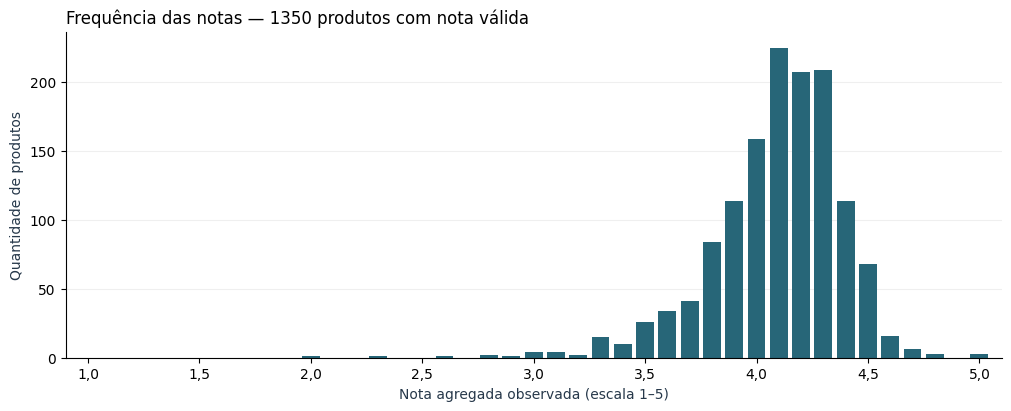

In [36]:
fig_notas, ax_notas = plt.subplots(figsize=(10, 4), layout="constrained")
ax_notas.bar(frequencia_notas.index.astype(float), frequencia_notas.values, width=0.08, color="#276678")
ax_notas.set_xlim(0.9, 5.1)
marcas_notas = [valor / 10 for valor in range(10, 51, 5)]
ax_notas.set_xticks(marcas_notas, [f"{valor:.1f}".replace(".", ",") for valor in marcas_notas])
ax_notas.set_xlabel("Nota agregada observada (escala 1–5)")
ax_notas.set_ylabel("Quantidade de produtos")
ax_notas.set_title(f"Frequência das notas — {len(notas_observadas)} produtos com nota válida", loc="left")
ax_notas.grid(axis="y", alpha=0.2)
ax_notas.set_axisbelow(True)
ax_notas.spines[["top", "right"]].set_visible(False)
plt.show()

In [37]:
q1_nota, q3_nota = notas_observadas.quantile([0.25, 0.75])
notas_centrais = notas_observadas.between(q1_nota, q3_nota).sum()
print(f"Entre Q1 e Q3, incluindo os limites: {notas_centrais} de {len(notas_observadas)} produtos "
      f"({notas_centrais / len(notas_observadas):.2%}).")
print(f"Nota mais frequente: {frequencia_notas.idxmax():.1f}, em {frequencia_notas.max()} produtos.")
print(f"Produtos na menor nota observada: {notas_observadas.eq(notas_observadas.min()).sum()}.")
print(f"Produtos na maior nota observada: {notas_observadas.eq(notas_observadas.max()).sum()}.")

Entre Q1 e Q3, incluindo os limites: 914 de 1350 produtos (67.70%).
Nota mais frequente: 4.1, em 225 produtos.
Produtos na menor nota observada: 1.
Produtos na maior nota observada: 3.


A mediana é **4,1**, a média é **4,09** e os quartis são **3,9 e 4,3**, entre 1.350 notas válidas. Incluindo os limites, **914 produtos (67,70%)** estão nesse intervalo. O percentual supera 50% porque muitos produtos têm notas exatamente iguais aos quartis. O valor mais frequente é **4,1, em 225 produtos**.

O mínimo observado é **2,0, em um produto**, e o máximo é **5,0, em três**. O gráfico mantém a escala completa de 1 a 5, deixando visível a concentração das notas em uma região estreita, sem ampliar visualmente diferenças de décimos.

As notas oferecem pouca separação entre grande parte dos IDs. Pequenas diferenças não comprovam qualidade ou satisfação estatisticamente distinta: a fonte apresenta agregados arredondados e não fornece a distribuição das estrelas individuais nem sua independência.

### 4.2 — O que a cauda da contagem altera?

A escala logarítmica abre espaço para examinar contagens de ordens de grandeza distintas. A estatística segue na escala original.

In [38]:
contagens_observadas = avaliacoes["rating_count_num"].dropna()
resumo_contagens = contagens_observadas.describe(percentiles=[0.25, 0.5, 0.75, 0.95])
resumo_contagens.loc["IIQ"] = resumo_contagens.loc["75%"] - resumo_contagens.loc["25%"]
resumo_contagens = resumo_contagens.rename(index={
    "count": "Produtos com contagem", "mean": "Média", "std": "Desvio-padrão",
    "min": "Mínimo", "25%": "Q1", "50%": "Mediana", "75%": "Q3", "95%": "Percentil 95", "max": "Máximo",
}).to_frame("Contagem agregada informada")
display(
    resumo_contagens.style.format(precision=2, decimal=",", thousands=".")
    .format(precision=0, thousands=".", subset=pd.IndexSlice[["Produtos com contagem"], :])
)
limite_cauda = contagens_observadas.quantile(0.95)
na_cauda = contagens_observadas.gt(limite_cauda).sum()
print(f"Acima do percentil 95: {na_cauda} produtos ({na_cauda / len(contagens_observadas):.2%}).")
print(f"Contagens iguais a zero: {contagens_observadas.eq(0).sum()}.")

,Contagem agregada informada
Produtos com contagem,1.349
Média,"17.644,49"
Desvio-padrão,"42.145,65"
Mínimo,"2,00"
Q1,"1.106,00"
Mediana,"4.740,00"
Q3,"16.020,00"
Percentil 95,"71.386,60"
Máximo,"426.973,00"
IIQ,"14.914,00"


Acima do percentil 95: 68 produtos (5.04%).
Contagens iguais a zero: 0.


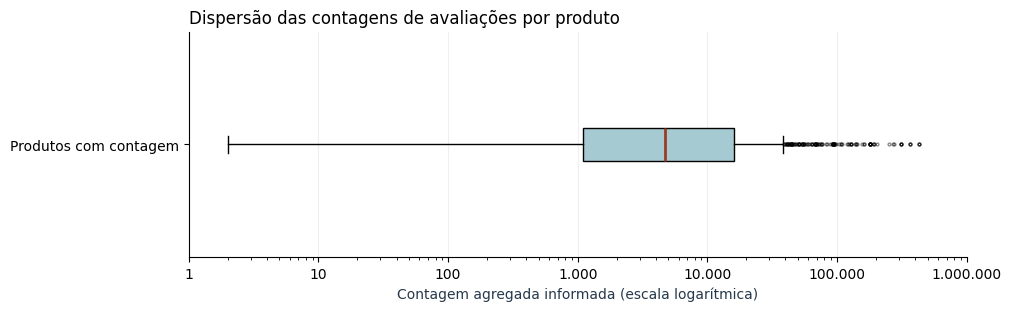

In [39]:
fig_contagens, ax_contagens = plt.subplots(figsize=(10, 3), layout="constrained")
ax_contagens.boxplot(
    contagens_observadas.to_numpy(dtype=float), orientation="horizontal",
    tick_labels=["Produtos com contagem"], showfliers=True, patch_artist=True,
    boxprops={"facecolor": "#A5CAD2"}, medianprops={"color": "#9C3C25", "linewidth": 2},
    flierprops={"marker": ".", "markersize": 4, "alpha": 0.45},
)
ax_contagens.set_xscale("log")
ax_contagens.set_xticks([1, 10, 100, 1000, 10000, 100000, 1000000],
                       ["1", "10", "100", "1.000", "10.000", "100.000", "1.000.000"])
ax_contagens.set_xlabel("Contagem agregada informada (escala logarítmica)")
ax_contagens.set_title("Dispersão das contagens de avaliações por produto", loc="left")
ax_contagens.grid(axis="x", alpha=0.2)
ax_contagens.spines[["top", "right"]].set_visible(False)
plt.show()

A mediana é **4.740 avaliações informadas por produto**, enquanto a média chega a **17.644,49** e o desvio-padrão a **42.145,65**. A metade central fica entre **1.106 e 16.020** (IIQ de 14.914). O mínimo é 2, não há contagens zero e o máximo chega a **426.973**.

Há **68 produtos (5,04% dos 1.349 válidos)** acima do percentil 95, de 71.386,60. A cauda evidencia um conjunto pequeno de IDs com contagens muito altas, sem que seja necessário somá-las ou interpretá-las como avaliações independentes. Valores fracionários em médias, medianas ou quantis podem resultar do cálculo sobre contagens inteiras.

O boxplot usa escala logarítmica: marcas sucessivas representam multiplicação por dez. Todos os valores informados participam; os limites de 1,5 IIQ são calculados antes da transformação visual, e pontos extremos não foram removidos. A sobreposição pode esconder quantos IDs compartilham o mesmo valor; por isso, os maiores registros são examinados a seguir.

In [40]:
maiores_contagens = (
    avaliacoes.loc[avaliacoes["rating_count_num"].notna()]
    .sort_values(["rating_count_num", "product_id"], ascending=[False, True]).head(3)
)
display(
    maiores_contagens[["product_id", "product_name", "categoria_nivel_1", "rating_num", "rating_count_num"]]
    .rename(columns={
        "product_id": "ID", "product_name": "Produto", "categoria_nivel_1": "Categoria",
        "rating_num": "Nota", "rating_count_num": "Contagem informada",
    }).style.hide(axis="index").format(precision=2, decimal=",", thousands=".", na_rep="—")
    .set_properties(subset=["Produto"], **{"max-width": "340px", "white-space": "normal"})
)

ID,Produto,Categoria,Nota,Contagem informada
B014I8SSD0,"Amazon Basics High-Speed HDMI Cable, 6 Feet - Supports Ethernet, 3D, 4K video,Black",Electronics,"4,40",426.973
B014I8SX4Y,"Amazon Basics High-Speed HDMI Cable, 6 Feet (2-Pack),Black",Electronics,"4,40",426.973
B07KSMBL2H,"AmazonBasics Flexible Premium HDMI Cable (Black, 4K@60Hz, 18Gbps), 3-Foot",Electronics,"4,40",426.973


Os três maiores registros são cabos HDMI Amazon Basics, com IDs **B014I8SSD0, B014I8SX4Y e B07KSMBL2H**. Todos apresentam **426.973** na contagem e **4,4** na nota, apesar de serem identificadores distintos.

A coincidência não demonstra que sejam três conjuntos independentes de avaliações, nem comprova sozinha que sejam o mesmo produto. Considerando as relações compartilhadas documentadas na preparação, a contagem deve permanecer como atributo do ID. Esses exemplos não constituem um ranking de vendas ou popularidade, e suas contagens não são somadas.

In [41]:
validas = avaliacoes[contagem].dropna()
ate_p95 = validas.loc[validas.le(validas.quantile(.95))]
display(pd.DataFrame({"n": [len(validas), len(ate_p95)],
                      "Média": [validas.mean(), ate_p95.mean()],
                      "Mediana": [validas.median(), ate_p95.median()]},
                     index=["Todas as contagens observadas", "Contagens até P95"]).round(1))

,n,Média,Mediana
Todas as contagens observadas,1349,17644.5,4740.0
Contagens até P95,1281,9847.7,4200.0


### 4.3 — Onde nota e contagem contam histórias diferentes?

Comparamos as medianas e a dispersão em cada nível. Cada medida mantém seu próprio n válido.

In [42]:
avaliacoes_categoria = avaliacoes.groupby("categoria_nivel_1").agg(
    Produtos=("product_id", "size"),
    Notas_validas=("rating_num", "count"),
    Nota_mediana=("rating_num", "median"),
    Nota_Q1=("rating_num", lambda valores: valores.quantile(0.25)),
    Nota_Q3=("rating_num", lambda valores: valores.quantile(0.75)),
    Contagens_validas=("rating_count_num", "count"),
    Contagem_mediana=("rating_count_num", "median"),
).sort_values("Produtos", ascending=False)

# Rótulos de apresentação comuns às comparações, sem alterar as medidas.
rotulos_avaliacoes = {
    "Notas_validas": "Notas válidas", "Nota_mediana": "Nota mediana", "Nota_Q1": "Nota Q1",
    "Nota_Q3": "Nota Q3", "Contagens_validas": "Contagens válidas", "Contagem_mediana": "Contagem mediana",
}
display(
    avaliacoes_categoria.rename_axis("Categoria principal").rename(columns=rotulos_avaliacoes)
    .style.format(precision=2, decimal=",", thousands=".", na_rep="—")
)

,Produtos,Notas válidas,Nota mediana,Nota Q1,Nota Q3,Contagens válidas,Contagem mediana
Categoria principal,,,,,,,
Electronics,490,490,"4,10","3,90","4,30",490,"9.129,50"
Home&Kitchen,448,447,"4,10","3,90","4,20",448,"2.305,50"
Computers&Accessories,375,375,"4,20","4,00","4,30",373,"7.317,00"
OfficeProducts,31,31,"4,30","4,20","4,40",31,"4.426,00"
MusicalInstruments,2,2,"3,90","3,85","3,95",2,"44.441,00"
HomeImprovement,2,2,"4,25","4,12","4,38",2,"4.283,00"
Car&Motorbike,1,1,"3,80","3,80","3,80",1,"1.118,00"
Health&PersonalCare,1,1,"4,00","4,00","4,00",1,"3.663,00"
Toys&Games,1,1,"4,30","4,30","4,30",1,"15.867,00"


As medianas de nota são próximas: **4,2 em Computers&Accessories (375 válidas)**, **4,1 em Electronics (490)** e **4,1 em Home&Kitchen (447)**. Seus intervalos interquartis se sobrepõem. Os números não sustentam uma classificação geral de qualidade entre as categorias.

As contagens medianas diferem mais: **9.129,50 em Electronics (490 válidas)**, **7.317 em Computers&Accessories (373)** e **2.305,50 em Home&Kitchen (448)**. São perfis distintos da quantidade informada, não de vendas ou compradores. O denominador muda conforme a disponibilidade de cada coluna.

OfficeProducts apresenta nota mediana de 4,3 em 31 produtos. Nas outras categorias, com um ou dois IDs, medianas e quartis descrevem casos isolados ou interpolações. A contagem mediana de 44.441 em MusicalInstruments, por exemplo, baseia-se em somente dois produtos, impedindo atribuir-lhe a mesma representatividade das categorias maiores.

In [43]:
avaliacoes_subcategoria = avaliacoes.groupby(["categoria_nivel_1", "categoria_nivel_2"]).agg(
    Produtos=("product_id", "size"),
    Notas_validas=("rating_num", "count"),
    Nota_mediana=("rating_num", "median"),
    Nota_Q1=("rating_num", lambda valores: valores.quantile(0.25)),
    Nota_Q3=("rating_num", lambda valores: valores.quantile(0.75)),
    Contagens_validas=("rating_count_num", "count"),
    Contagem_mediana=("rating_count_num", "median"),
)
display(
    avaliacoes_subcategoria.loc[subcategorias_comparadas.index]
    .rename_axis(["Categoria principal", "Subcategoria (nível 2)"]).rename(columns=rotulos_avaliacoes)
    .style.format(precision=2, decimal=",", thousands=".", na_rep="—")
)

Em Electronics, **Headphones,Earbuds&Accessories tem nota mediana de 3,9 e contagem mediana de 37.817**, com 63 valores válidos em ambas as medidas. **HomeTheater,TV&Video tem nota mediana de 4,2 e contagem mediana de 1.532,50**, com 156 válidos. Nesse contraste, maior contagem não acompanha maior nota.

Em Computers&Accessories, NetworkingDevices (**30 produtos**) e Accessories&Peripherals (**307**) têm a mesma nota mediana de **4,2**, mas contagens medianas de **21.358,50 (30 válidas)** e **5.730 (305 válidas)**. Em Home&Kitchen, os dois grandes caminhos mantêm nota mediana de 4,1, com contagens medianas de 1.743,50 em Heating,Cooling&AirQuality e 2.305,50 em Kitchen&HomeAppliances.

A composição interna contextualiza as diferenças agregadas, mas não identifica sua causa. Tempo de exposição, dinâmica de avaliações e compartilhamento de registros não são controlados pela fonte; as subcategorias também reúnem produtos heterogêneos.

### 4.4 — Qual é a associação entre nota e contagem?

Primeiro examinamos as notas por faixa de contagem. Depois comparamos os postos em pares completos no catálogo, no topo e nos ramos.

In [44]:
avaliacoes["faixa_contagem"], limites_contagem = pd.qcut(
    avaliacoes["rating_count_num"], q=4, labels=["V1", "V2", "V3", "V4"], retbins=True,
)
notas_por_contagem = avaliacoes.groupby("faixa_contagem", observed=True).agg(
    Produtos=("product_id", "size"), Notas_validas=("rating_num", "count"),
    Nota_mediana=("rating_num", "median"),
    Nota_Q1=("rating_num", lambda valores: valores.quantile(0.25)),
    Nota_Q3=("rating_num", lambda valores: valores.quantile(0.75)),
)
notas_por_contagem.insert(0, "Limite inferior da contagem", limites_contagem[:-1])
notas_por_contagem.insert(1, "Limite superior da contagem", limites_contagem[1:])
display(
    notas_por_contagem.rename_axis("Faixa").rename(columns=rotulos_avaliacoes)
    .style.format(precision=2, decimal=",", thousands=".")
)

,Limite inferior da contagem,Limite superior da contagem,Produtos,Notas válidas,Nota mediana,Nota Q1,Nota Q3
Faixa,,,,,,,
V1,"2,00","1.106,00",338,337,"4,00","3,80","4,20"
V2,"1.106,00","4.740,00",338,338,"4,10","4,00","4,30"
V3,"4.740,00","16.020,00",336,336,"4,10","4,00","4,30"
V4,"16.020,00","426.973,00",337,337,"4,20","4,10","4,30"


Os cortes são **1.106, 4.740 e 16.020** avaliações informadas. As notas medianas passam de **4,0 em V1 (337 notas em 338 produtos)** para **4,1 em V2 (338)**, **4,1 em V3 (336)** e **4,2 em V4 (337)**. No conjunto com ambas as medidas disponíveis, há um deslocamento descritivo modesto da mediana entre as faixas extremas.

Os intervalos de nota se sobrepõem: V1 vai de **3,8 a 4,2** entre quartis, e V4 de **4,1 a 4,3**. O contraste de subcategorias da seção anterior mostra que essa associação agregada não é uma regra universal. Contagem alta não garante qualidade, confiabilidade estatística ou maior número de consumidores únicos; não há informação suficiente para tratar as avaliações como observações independentes.

In [45]:
pares_avaliacoes = [(x, y) for x in medidas_preco for y in colunas_avaliacoes] + [(nota, contagem)]
assoc_avaliacoes = quadro_spearman(grupos_associacao, pares_avaliacoes)
display(assoc_avaliacoes.loc[assoc_avaliacoes["Relação"].eq("Nota × Contagem informada") &
                              assoc_avaliacoes.n.ge(30)].set_index("Grupo")[["n", "ρ"]].round(3))

,n,ρ
Grupo,,
Catálogo,1348,0.193
Computers&Accessories,373,0.255
Electronics,490,0.150
Home&Kitchen,447,0.203
OfficeProducts,31,0.234
Computers&Accessories / Accessories&Peripherals,305,0.212
Computers&Accessories / NetworkingDevices,30,0.440
"Electronics / Headphones,Earbuds&Accessories",63,0.436
"Electronics / HomeTheater,TV&Video",156,0.483


### 4.5 — Como preços e descontos se relacionam com avaliações?

Comparamos as seis combinações comerciais e a relação entre nota e contagem. O denominador de cada célula é o número de pares observados.

In [46]:
def exibir_associacoes(tabela):
    d = tabela.copy()
    d["ρ (n)"] = [f"{r:+.3f} ({n})" if pd.notna(r) else f"— ({n})" for n, r in zip(d.n, d["ρ"])]
    display(d.pivot(index="Grupo", columns="Relação", values="ρ (n)").style
            .set_properties(**{"white-space": "nowrap"}))

principais = ["Catálogo", *list(maiores_categorias), "OfficeProducts"]
exibir_associacoes(assoc_avaliacoes.loc[assoc_avaliacoes.Grupo.isin(principais)])

Relação,Com desconto (INR) × Contagem informada,Com desconto (INR) × Nota,Desconto (%) × Contagem informada,Desconto (%) × Nota,Nota × Contagem informada,Original (INR) × Contagem informada,Original (INR) × Nota
Grupo,,,,,,,
Catálogo,+0.146 (1349),+0.077 (1350),-0.131 (1349),-0.150 (1350),+0.193 (1348),+0.109 (1349),+0.033 (1350)
Computers&Accessories,+0.262 (373),+0.389 (375),-0.248 (373),-0.188 (375),+0.255 (373),+0.145 (373),+0.311 (375)
Electronics,+0.157 (490),+0.118 (490),-0.142 (490),-0.165 (490),+0.150 (490),+0.114 (490),+0.095 (490)
Home&Kitchen,+0.178 (448),+0.191 (447),-0.342 (448),-0.223 (447),+0.203 (447),+0.068 (448),+0.120 (447)
OfficeProducts,-0.019 (31),+0.202 (31),+0.217 (31),-0.067 (31),+0.234 (31),+0.130 (31),+0.136 (31)


In [47]:
avaliacoes_por_preco = avaliacoes.groupby("faixa_preco_original", observed=True).agg(
    Produtos=("product_id", "size"),
    Notas_validas=("rating_num", "count"),
    Nota_mediana=("rating_num", "median"),
    Nota_Q1=("rating_num", lambda valores: valores.quantile(0.25)),
    Nota_Q3=("rating_num", lambda valores: valores.quantile(0.75)),
    Contagens_validas=("rating_count_num", "count"),
    Contagem_mediana=("rating_count_num", "median"),
)
display(
    avaliacoes_por_preco.rename_axis("Faixa de preço original").rename(columns=rotulos_avaliacoes)
    .style.format(precision=2, decimal=",", thousands=".", na_rep="—")
)

,Produtos,Notas válidas,Nota mediana,Nota Q1,Nota Q3,Contagens válidas,Contagem mediana
Faixa de preço original,,,,,,,
F1,345,345,"4,10","3,90","4,30",345,"3.846,00"
F2,331,331,"4,10","4,00","4,30",329,"4.022,00"
F3,337,336,"4,10","3,90","4,30",337,"4.099,00"
F4,338,338,"4,15","4,00","4,30",338,"7.194,50"


As notas medianas são **4,1 nas três primeiras faixas** e **4,15 na última**, com quartis muito próximos. Os denominadores de nota são 345, 331, 336 e 338. A mediana 4,15 resulta da posição central entre valores observados e não é uma nota individual mais precisa. Não há separação nítida das notas por preço original.

As contagens medianas são **3.846, 4.022, 4.099 e 7.194,50**, com 345, 329, 337 e 338 contagens válidas. A faixa superior apresenta contagem central maior, mas essa comparação pode refletir a composição do catálogo. Para contextualizar o contraste, examinam-se as mesmas faixas extremas dentro das três categorias principais.

In [48]:
avaliacoes_preco_categoria = (
    avaliacoes.loc[
        avaliacoes["categoria_nivel_1"].isin(maiores_categorias)
        & avaliacoes["faixa_preco_original"].isin(["F1", "F4"])
    ].groupby(["categoria_nivel_1", "faixa_preco_original"], observed=True).agg(
        Produtos=("product_id", "size"),
        Notas_validas=("rating_num", "count"), Nota_mediana=("rating_num", "median"),
        Contagens_validas=("rating_count_num", "count"), Contagem_mediana=("rating_count_num", "median"),
    )
)
display(
    avaliacoes_preco_categoria.rename_axis(["Categoria principal", "Faixa de preço original"])
    .rename(columns=rotulos_avaliacoes).style.format(precision=2, decimal=",", thousands=".")
)

Entre F1 e F4, a contagem mediana passa de **2.492 para 12.796 em Electronics (93 e 211 produtos)**, de **7.333 para 9.628 em Computers&Accessories (143 e 20)** e de **2.326 para 3.233 em Home&Kitchen (77 e 107)**. Todas as medidas estão informadas nesses seis grupos.

O contraste entre extremos permanece nas três categorias, mas com magnitudes e tamanhos muito diferentes. Electronics pesa mais na faixa superior, enquanto Computers&Accessories possui apenas 20 produtos nela. As notas medianas, por sua vez, caem de 4,2 para 4,1 em Electronics, sobem de 4,1 para 4,3 em Computers&Accessories e de 4,1 para 4,2 em Home&Kitchen.

O recorte compara extremos e não demonstra uma trajetória contínua entre as quatro faixas. Também não controla diferenças de subcategoria, exposição ou histórico. Assim, preço original maior não pode ser interpretado como causa de mais avaliações ou melhor nota.

In [49]:
avaliacoes["faixa_desconto"], limites_desconto = pd.qcut(
    avaliacoes["discount_percentage_num"], q=4, labels=["D1", "D2", "D3", "D4"], retbins=True,
)
avaliacoes_por_desconto = avaliacoes.groupby("faixa_desconto", observed=True).agg(
    Produtos=("product_id", "size"),
    Notas_validas=("rating_num", "count"), Nota_mediana=("rating_num", "median"),
    Nota_Q1=("rating_num", lambda valores: valores.quantile(0.25)),
    Nota_Q3=("rating_num", lambda valores: valores.quantile(0.75)),
    Contagens_validas=("rating_count_num", "count"), Contagem_mediana=("rating_count_num", "median"),
)
print("Limites das faixas de desconto (%):", limites_desconto.tolist())
display(
    avaliacoes_por_desconto.rename_axis("Faixa de desconto").rename(columns=rotulos_avaliacoes)
    .style.format(precision=2, decimal=",", thousands=".", na_rep="—")
)

Limites das faixas de desconto (%): [0.0, 31.0, 49.0, 62.0, 94.0]


,Produtos,Notas válidas,Nota mediana,Nota Q1,Nota Q3,Contagens válidas,Contagem mediana
Faixa de desconto,,,,,,,
D1,350,349,"4,20","4,00","4,30",350,"7.876,50"
D2,339,339,"4,10","3,90","4,30",339,"4.703,00"
D3,327,327,"4,10","3,90","4,30",327,"2.449,00"
D4,335,335,"4,10","3,90","4,30",333,"4.415,00"


Os intervalos são **D1: 0% a 31%; D2: acima de 31% até 49%; D3: acima de 49% até 62%; D4: acima de 62% até 94%**. A nota mediana é **4,2 em D1 (349 notas válidas)** e **4,1 nas demais faixas (339, 327 e 335)**. Os quartis se sobrepõem, sem separação clara por intensidade do desconto.

As contagens medianas são **7.876,50, 4.703, 2.449 e 4.415**, com 350, 339, 327 e 333 valores informados. A contagem diminui até D3 e volta a crescer em D4; não há sequência uniforme. Para verificar se essa retomada se repete dentro das categorias principais, mantém-se a mesma definição de faixas no cruzamento seguinte.

In [50]:
avaliacoes_desconto_categoria = (
    avaliacoes.loc[avaliacoes["categoria_nivel_1"].isin(maiores_categorias)]
    .groupby(["categoria_nivel_1", "faixa_desconto"], observed=True).agg(
        Produtos=("product_id", "size"),
        Notas_validas=("rating_num", "count"), Nota_mediana=("rating_num", "median"),
        Contagens_validas=("rating_count_num", "count"), Contagem_mediana=("rating_count_num", "median"),
    )
)
display(
    avaliacoes_desconto_categoria.rename_axis(["Categoria principal", "Faixa de desconto"])
    .rename(columns=rotulos_avaliacoes).style.format(precision=2, decimal=",", thousands=".", na_rep="—")
)

Em **Computers&Accessories**, a contagem mediana cai de **10.796,50 em D1 (58 válidas)** para **2.977 em D4 (136 válidas em 138 produtos)**. Em **Home&Kitchen**, cai de **4.485,50 (138 válidas)** para **542,50 (34 válidas)**. Essas categorias não mostram a retomada observada no agregado.

Em **Electronics**, a contagem mediana passa de **2.991 em D3 (106 válidas)** para **9.254,50 em D4 (162 válidas)**. D4 reúne mais produtos de Electronics do que de Home&Kitchen; a composição e os padrões internos precisam acompanhar a leitura agregada. Isso não constitui uma decomposição causal da diferença.

As notas também variam pouco e de modo não uniforme: entre D1 e D4, as medianas vão de 4,3 para 4,1 em Computers&Accessories, permanecem em 4,1 em Electronics e vão de 4,2 para 3,9 em Home&Kitchen. Esta última comparação usa 137 e 34 notas válidas. O grupo menor e a heterogeneidade dos produtos limitam generalizações. Não há evidência de que o desconto tenha produzido a nota ou o volume informado.

### 4.6 — O sinal do catálogo se repete nos ramos?

A matriz mostra os grupos de topo e nível 2 que alcançam o limiar de 30. A tabela completa em memória conserva os grupos menores e marca coeficientes sem suporte.

In [51]:
nomes_ramos = [" / ".join(chave) for chave, d in grupos_n2 if len(d) >= 30]
assoc_ramos = assoc_avaliacoes.loc[assoc_avaliacoes.Grupo.isin(nomes_ramos)]
exibir_associacoes(assoc_ramos)
rho_geral = assoc_avaliacoes.loc[assoc_avaliacoes.Grupo.eq("Catálogo")].set_index("Relação")["ρ"]
inversoes = assoc_ramos.assign(geral=assoc_ramos["Relação"].map(rho_geral))
inversoes = inversoes.loc[inversoes["ρ"].mul(inversoes.geral).lt(0)].copy()
inversoes["Diferença absoluta"] = (inversoes["ρ"] - inversoes.geral).abs()
display(inversoes.sort_values("Diferença absoluta", ascending=False).head(8).round(3))

Relação,Com desconto (INR) × Contagem informada,Com desconto (INR) × Nota,Desconto (%) × Contagem informada,Desconto (%) × Nota,Nota × Contagem informada,Original (INR) × Contagem informada,Original (INR) × Nota
Grupo,,,,,,,
Computers&Accessories / Accessories&Peripherals,+0.156 (305),+0.402 (307),-0.231 (305),-0.211 (307),+0.212 (305),+0.019 (305),+0.306 (307)
Computers&Accessories / NetworkingDevices,+0.267 (30),+0.455 (30),-0.237 (30),-0.223 (30),+0.440 (30),+0.170 (30),+0.375 (30)
"Electronics / Headphones,Earbuds&Accessories",-0.093 (63),-0.090 (63),-0.232 (63),-0.297 (63),+0.436 (63),-0.169 (63),-0.279 (63)
"Electronics / HomeTheater,TV&Video",+0.340 (156),+0.347 (156),-0.413 (156),-0.259 (156),+0.483 (156),+0.293 (156),+0.327 (156)
Electronics / Mobiles&Accessories,+0.390 (151),-0.050 (151),-0.379 (151),+0.154 (151),-0.056 (151),+0.353 (151),-0.018 (151)
Electronics / WearableTechnology,-0.017 (62),+0.303 (62),+0.055 (62),+0.242 (62),+0.150 (62),+0.087 (62),+0.635 (62)
"Home&Kitchen / Heating,Cooling&AirQuality",+0.192 (116),+0.350 (116),-0.277 (116),-0.094 (116),+0.343 (116),+0.100 (116),+0.306 (116)
Home&Kitchen / Kitchen&HomeAppliances,+0.293 (308),+0.238 (307),-0.378 (308),-0.234 (307),+0.120 (307),+0.161 (308),+0.155 (307)


,Grupo,Relação,n,ρ,geral,Diferença absoluta
193,Electronics / WearableTechnology,Desconto (%) × Nota,62,0.242,-0.150,0.391
154,"Electronics / Headphones,Earbuds&Accessories",Original (INR) × Nota,63,-0.279,0.033,0.312
179,Electronics / Mobiles&Accessories,Desconto (%) × Nota,151,0.154,-0.150,0.304
155,"Electronics / Headphones,Earbuds&Accessories",Original (INR) × Contagem informada,63,-0.169,0.109,0.278
181,Electronics / Mobiles&Accessories,Nota × Contagem informada,151,-0.056,0.193,0.249
157,"Electronics / Headphones,Earbuds&Accessories",Com desconto (INR) × Contagem informada,63,-0.093,0.146,0.239
194,Electronics / WearableTechnology,Desconto (%) × Contagem informada,62,0.055,-0.131,0.186
156,"Electronics / Headphones,Earbuds&Accessories",Com desconto (INR) × Nota,63,-0.090,0.077,0.167


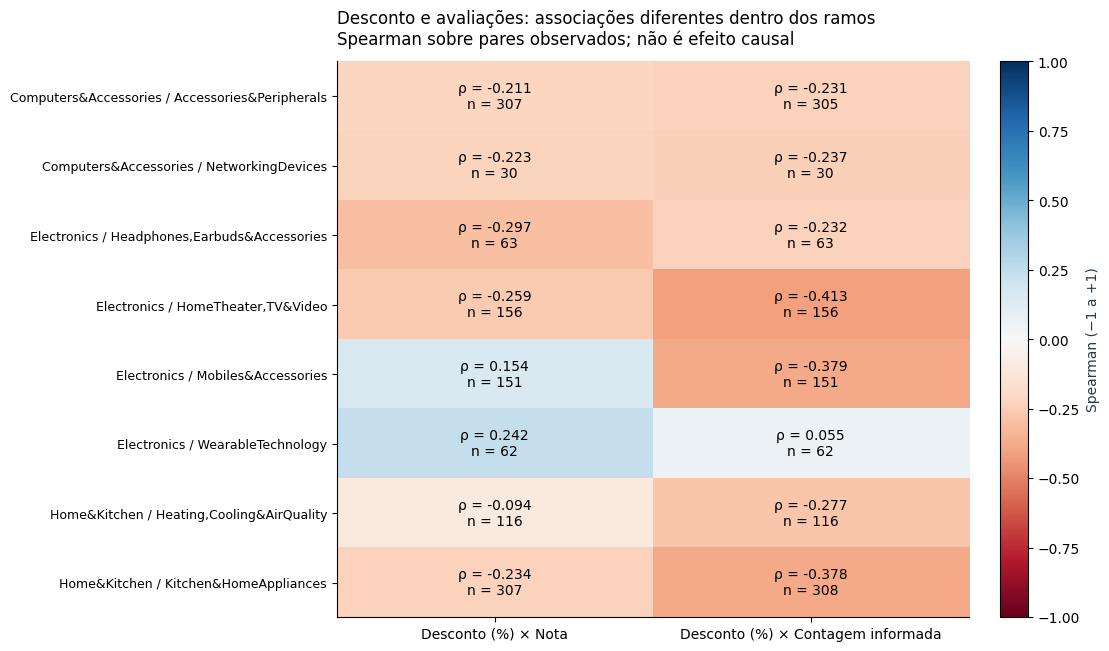

In [52]:
mapa_rho=assoc_ramos.pivot(index="Grupo",columns="Relação",values="ρ")[["Desconto (%) × Nota","Desconto (%) × Contagem informada"]]
mapa_n=assoc_ramos.pivot(index="Grupo",columns="Relação",values="n").reindex(index=mapa_rho.index,columns=mapa_rho.columns)
import textwrap
fig_associacoes,ax_associacoes=plt.subplots(figsize=(11,6.4),layout="constrained")
im=ax_associacoes.imshow(mapa_rho.to_numpy(dtype=float),cmap="RdBu",vmin=-1,vmax=1,aspect="auto")
ax_associacoes.set_xticks(range(2),mapa_rho.columns)
ax_associacoes.set_yticks(range(len(mapa_rho)),[textwrap.fill(x,48) for x in mapa_rho.index],fontsize=9)
for linha in range(len(mapa_rho)):
    for coluna in range(2):
        valor=mapa_rho.iloc[linha,coluna]
        ax_associacoes.text(coluna,linha,f"ρ = {valor:.3f}\nn = {mapa_n.iloc[linha,coluna]}",ha="center",va="center",color="white" if abs(valor)>.55 else "black")
ax_associacoes.set_title("Desconto e avaliações: associações diferentes dentro dos ramos\nSpearman sobre pares observados; não é efeito causal",loc="left",pad=12)
fig_associacoes.colorbar(im,ax=ax_associacoes,label="Spearman (−1 a +1)")
plt.show()

In [53]:
# Extremos de rho entre ramos elegíveis, com n nos dois extremos.
amplitude_rho = []
for relacao,d in assoc_ramos.dropna(subset=["ρ"]).groupby("Relação"):
    menor, maior = d.loc[d["ρ"].idxmin()], d.loc[d["ρ"].idxmax()]
    amplitude_rho.append({"Relação":relacao,"Catálogo":rho_geral[relacao],
        "Menor ramo":menor.Grupo,"Menor ρ":menor["ρ"],"n menor":menor.n,
        "Maior ramo":maior.Grupo,"Maior ρ":maior["ρ"],"n maior":maior.n,
        "Sinal oposto ao geral":int(d["ρ"].mul(rho_geral[relacao]).lt(0).sum())})
amplitude_rho = pd.DataFrame(amplitude_rho)
display(amplitude_rho.set_index("Relação").style.format(precision=3)
        .set_properties(**{"overflow-wrap":"anywhere","max-width":"200px"}))

,Catálogo,Menor ramo,Menor ρ,n menor,Maior ramo,Maior ρ,n maior,Sinal oposto ao geral
Relação,,,,,,,,
Com desconto (INR) × Contagem informada,0.146,"Electronics / Headphones,Earbuds&Accessories",-0.093,63,Electronics / Mobiles&Accessories,0.390,151,2
Com desconto (INR) × Nota,0.077,"Electronics / Headphones,Earbuds&Accessories",-0.090,63,Computers&Accessories / NetworkingDevices,0.455,30,2
Desconto (%) × Contagem informada,-0.131,"Electronics / HomeTheater,TV&Video",-0.413,156,Electronics / WearableTechnology,0.055,62,1
Desconto (%) × Nota,-0.150,"Electronics / Headphones,Earbuds&Accessories",-0.297,63,Electronics / WearableTechnology,0.242,62,2
Nota × Contagem informada,0.193,Electronics / Mobiles&Accessories,-0.056,151,"Electronics / HomeTheater,TV&Video",0.483,156,1
Original (INR) × Contagem informada,0.109,"Electronics / Headphones,Earbuds&Accessories",-0.169,63,Electronics / Mobiles&Accessories,0.353,151,1
Original (INR) × Nota,0.033,"Electronics / Headphones,Earbuds&Accessories",-0.279,63,Electronics / WearableTechnology,0.635,62,2


O preço original tem associação pequena com nota no catálogo (ρ≈0,03), mas o resultado varia de −0,28 em Headphones (63 pares) a +0,63 em Wearable (62). Nota × contagem também varia, de −0,06 em Mobiles (151) a +0,48 em HomeTheater (156). A composição dos ramos é uma hipótese para essas diferenças.

O sinal geral desconto×nota **não é uniforme**: em Mobiles&Accessories, ρ=+0,154 (n=151), e WearableTechnology, +0,242 (n=62), contra −0,297 em Headphones (n=63). Para desconto×contagem, HomeTheater apresenta −0,413 (n=156), enquanto WearableTechnology fica próximo de zero (+0,055; n=62). A nota discreta e o mix ajudam a formular explicações alternativas, mas não identificam causa.

Retirando conflitos, Wearable desconto×nota fica +0,222 (n=51); no recorte central, +0,338 (n=53). NetworkingDevices perde base suficiente no recorte central (25 pares), e o coeficiente fica não calculado. Restringir caudas muda a população: é sensibilidade, não uma estimativa superior. Não há base para concluir que desconto produza nota ou volume. No BI, permitir comparação por ramo e dispersão em detalhe; coeficientes/sensibilidades são apoio técnico, não KPI de eficácia promocional.

### 4.7 — O resultado resiste a mudanças de recorte?

Para as relações centrais, comparamos pares completos, pares sem conflitos de origem e a faixa central P5–P95 de cada campo. Os recortes de robustez mantêm o diagnóstico original intacto.

In [54]:
campos_conflito = [*indicadores_preco, "conflito_contagem"]
pares_chave = [(percentual, nota), (percentual, contagem), (nota, contagem)]
robustez = []
for nome, d in grupos_associacao:
    if nome not in [*principais, *nomes_ramos]:
        continue
    for x, y in pares_chave:
        par = d[[x, y]].dropna().astype(float)
        central = par.loc[par[x].between(par[x].quantile(.05), par[x].quantile(.95)) &
                          par[y].between(par[y].quantile(.05), par[y].quantile(.95))]
        sem_conflito = d.loc[~d[campos_conflito].any(axis=1)]
        robustez.append((nome, f"{rotulos_medidas[x]} × {rotulos_medidas[y]}",
                         *spearman_observado(d, x, y), *spearman_observado(sem_conflito, x, y),
                         *spearman_observado(central, x, y)))
robustez = pd.DataFrame(robustez, columns=["Grupo", "Relação", "n", "ρ", "n sem conflito",
                                         "ρ sem conflito", "n central", "ρ central"])
display(robustez.loc[robustez.Grupo.isin(["Catálogo", *nomes_ramos]) &
    robustez["Relação"].eq("Desconto (%) × Nota")].set_index("Grupo").round(3))
faixas_assoc = quadro_spearman(list(precos.groupby("faixa_preco_original", observed=True)), pares_chave)
exibir_associacoes(faixas_assoc)
suporte_assoc = pd.DataFrame([
    {"Mínimo de pares": n, "Ramos com desconto × nota calculável":
     quadro_spearman([(" / ".join(k), d) for k,d in grupos_n2], [(percentual, nota)], n)["ρ"].count()}
    for n in [20,30,50]])
display(suporte_assoc)

,Relação,n,ρ,n sem conflito,ρ sem conflito,n central,ρ central
Grupo,,,,,,,
Catálogo,Desconto (%) × Nota,1350,-0.150,1317,-0.153,1144,-0.084
Computers&Accessories / Accessories&Peripherals,Desconto (%) × Nota,307,-0.211,293,-0.201,263,-0.207
Computers&Accessories / NetworkingDevices,Desconto (%) × Nota,30,-0.223,30,-0.223,25,NaN
"Electronics / Headphones,Earbuds&Accessories",Desconto (%) × Nota,63,-0.297,61,-0.277,53,-0.228
"Electronics / HomeTheater,TV&Video",Desconto (%) × Nota,156,-0.259,154,-0.277,128,-0.367
Electronics / Mobiles&Accessories,Desconto (%) × Nota,151,0.154,149,0.166,129,0.211
Electronics / WearableTechnology,Desconto (%) × Nota,62,0.242,51,0.222,53,0.338
"Home&Kitchen / Heating,Cooling&AirQuality",Desconto (%) × Nota,116,-0.094,116,-0.094,95,-0.154
Home&Kitchen / Kitchen&HomeAppliances,Desconto (%) × Nota,307,-0.234,307,-0.234,259,-0.158


Relação,Desconto (%) × Contagem informada,Desconto (%) × Nota,Nota × Contagem informada
Grupo,,,
F1,-0.111 (345),-0.252 (345),+0.319 (345)
F2,-0.248 (329),-0.051 (331),+0.140 (329)
F3,-0.075 (337),-0.123 (336),+0.273 (336)
F4,-0.129 (338),-0.141 (338),-0.029 (338)


,Mínimo de pares,Ramos com desconto × nota calculável
0,20,9
1,30,8
2,50,7


No catálogo, desconto × nota passa de −0,150 (1.350 pares) para −0,153 (1.317) após retirar conflitos e −0,084 (1.144) no recorte central. O sinal continua positivo em Mobiles e Wearable nos dois recortes auxiliares. A intensidade depende do conjunto de pares. O corte de 20, 30 ou 50 pares cobre, respectivamente, nove, oito ou sete ramos nessa relação.

### 4.8 — O que as avaliações sustentam?

Entre 1.350 notas válidas, 914 estão de 3,9 a 4,3, incluindo os limites. A contagem tem mediana de 4.740 e média de cerca de 17.644. As duas medidas descrevem dimensões distintas e suas relações mudam com a composição. Desconto × nota permanece positivo em Mobiles e Wearable após os recortes auxiliares, enquanto o coeficiente geral negativo enfraquece ao retirar as caudas. Isso motiva cortes por categoria para os perfis e a verificação do que acontece quando o comparador se torna mais específico. A leitura de aspectos exige textos e a avaliação de efeito promocional exige histórico.

## 5 — Diagnóstico integrado e prioridades de investigação

### 5.1 — Como comparar nota e contagem dentro da categoria?

As referências são as medianas observadas e fixas das três categorias maiores. Contagem igual ao corte entra no lado superior. Empate na nota, falta de uma medida e categoria fora do recorte têm estados próprios.

In [55]:
def classificar_perfis(base, grupos):
    """Mesma regra para referência oficial e sensibilidade; não modifica a entrada."""
    d = base.copy()
    g = d.groupby(grupos,dropna=False)
    d["limite_nota"] = g.rating_num.transform("median")
    d["limite_contagem"] = g.rating_count_num.transform("median")
    d["n_grupo"] = g.product_id.transform("size")
    presentes = d[["rating_num","rating_count_num"]].notna().all(axis=1)
    alta = d.rating_num.gt(d.limite_nota)
    baixa = d.rating_num.lt(d.limite_nota)
    superior = d.rating_count_num.ge(d.limite_contagem)
    d["perfil_completo"] = "Empate na nota"
    for condicao, nome in [
        (baixa & superior,"Nota abaixo; contagem superior"),
        (alta & superior,"Nota acima; contagem superior"),
        (alta & ~superior,"Nota acima; contagem inferior"),
        (baixa & ~superior,"Nota abaixo; contagem inferior")]:
        d.loc[condicao.fillna(False),"perfil_completo"] = nome
    d.loc[~presentes,"perfil_completo"] = "Sem ambas as medidas"
    return d

perfis = classificar_perfis(avaliacoes.loc[avaliacoes.categoria_nivel_1.isin(maiores_categorias)], ["categoria_nivel_1"])
# Preservar o contrato legado; o detalhamento é uma coluna adicional em memória.
perfis["perfil"] = perfis.perfil_completo.replace({"Nota acima; contagem inferior":"Nota diferente; contagem inferior",
                                                "Nota abaixo; contagem inferior":"Nota diferente; contagem inferior"})
ambas = perfis[["rating_num","rating_count_num"]].notna().all(axis=1)
display(perfis.groupby("categoria_nivel_1")[["limite_nota","limite_contagem"]].first().style.format(precision=2,decimal=",",thousands="."))

,limite_nota,limite_contagem
categoria_nivel_1,,
Computers&Accessories,"4,20","7.317,00"
Electronics,"4,10","9.129,50"
Home&Kitchen,"4,10","2.305,50"


Os limites de nota são **4,2 em Computers&Accessories** e **4,1 nas outras duas categorias**; os limites de contagem são **7.317, 9.129,50 e 2.305,50**, respectivamente em Computers&Accessories, Electronics e Home&Kitchen.

O contraste de nota abaixo e contagem superior reúne **59, 75 e 78 produtos** nessas categorias; o de nota acima reúne **90, 108 e 101**. São **212 e 299 produtos**, todos com ambas as medidas. Outros **228** têm nota exatamente igual à mediana local; por isso, não foram arbitrariamente distribuídos entre os dois lados. Há ainda três produtos sem ambas as medidas.

Os termos acima e abaixo expressam posição relativa, não qualidade comprovada. Um décimo pode mudar o enquadramento, e uma contagem superior à mediana não significa demanda elevada ou opiniões independentes.

### 5.2 — Onde os perfis se concentram?

A distribuição por topo inclui os estados de exceção. Por ramo, a participação usa todos os produtos do grupo. Os denominadores elegíveis para o BI são testados na etapa 6.

In [56]:
ordem_perfis=["Nota abaixo; contagem superior","Nota acima; contagem superior",
              "Nota acima; contagem inferior","Nota abaixo; contagem inferior","Empate na nota","Sem ambas as medidas"]
particao=pd.crosstab(perfis.categoria_nivel_1,perfis.perfil_completo).reindex(columns=ordem_perfis,fill_value=0)
particao.loc["Total"] = particao.sum()
display(particao.T)
assert particao.loc["Total"].tolist()==[212,299,241,330,228,3]
assert len(perfis)==1313 and perfis.product_id.is_unique
assert perfis.perfil.eq("Nota diferente; contagem inferior").sum()==571
display(pd.DataFrame({"Universo":["Três categorias","Classificáveis nas três categorias"],
    "Numerador alta/baixa":[int(perfis.perfil_completo.eq(ordem_perfis[2]).sum())]*2,"Denominador":[len(perfis),int(ambas.sum())],
    "Participação (%)":[100*perfis.perfil_completo.eq(ordem_perfis[2]).mean(),100*perfis.perfil_completo.eq(ordem_perfis[2]).sum()/ambas.sum()]}).style.hide(axis="index").format(precision=2,decimal=","))

categoria_nivel_1,Computers&Accessories,Electronics,Home&Kitchen,Total
perfil_completo,,,,
Nota abaixo; contagem superior,59,75,78,212
Nota acima; contagem superior,90,108,101,299
Nota acima; contagem inferior,63,110,68,241
Nota abaixo; contagem inferior,103,110,117,330
Empate na nota,58,87,83,228
Sem ambas as medidas,2,0,1,3


Universo,Numerador alta/baixa,Denominador,Participação (%)
Três categorias,241,1313,"18,35"
Classificáveis nas três categorias,241,1310,"18,40"


Os **241 produtos** com nota acima e contagem abaixo do corte são 110 de Electronics, 68 de Home&Kitchen e 63 de Computers&Accessories. Eles eram parte dos 571 casos de contagem inferior. Agora há duas perguntas distintas: o que caracteriza os 241 alta/baixa e os 330 baixa/baixa? Nenhum dos dois grupos prova baixa exposição. A participação alta/baixa é **18,35% dos 1.313** ou **18,40% dos 1.310 classificáveis**. O BI deve nomear o denominador e mostrar os três faltantes separadamente.

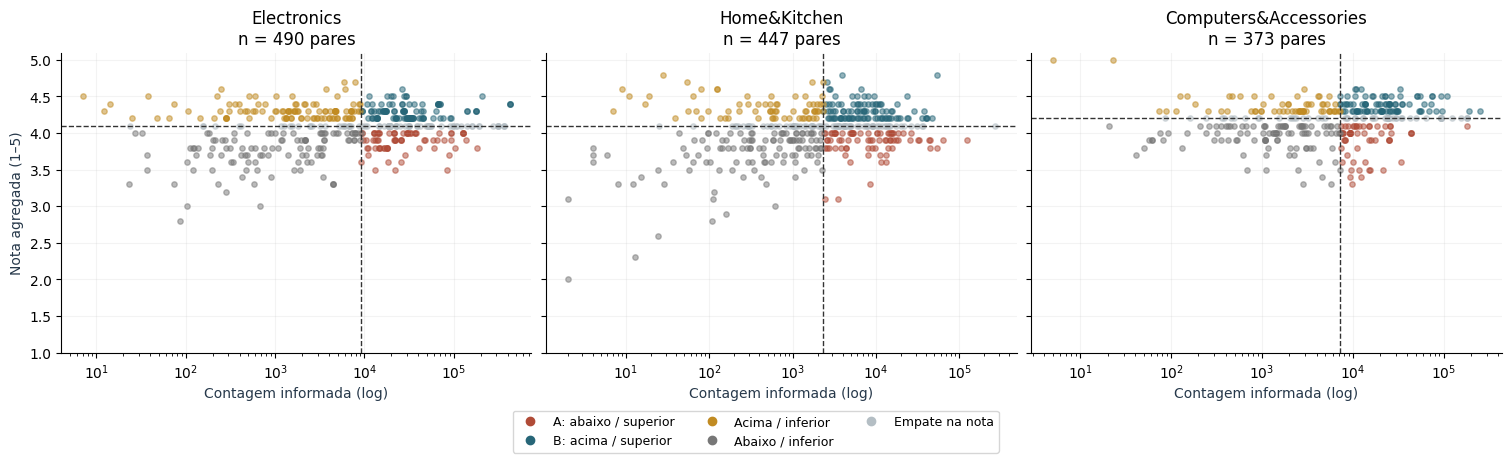

In [57]:
fig_relacao,eixos=plt.subplots(1,3,figsize=(15,4.5),sharey=True,layout="constrained")
cores_perfil=dict(zip(ordem_perfis,["#b04b37","#276678","#c18b22","#777777","#b4bec4","#dddddd"]))
for ax,categoria in zip(eixos,maiores_categorias):
    d=perfis.loc[perfis.categoria_nivel_1.eq(categoria) & perfis[["rating_num","rating_count_num"]].notna().all(axis=1)]
    for perfil in ordem_perfis[:-1]:
        sub=d.loc[d.perfil_completo.eq(perfil)]
        ax.scatter(sub.rating_count_num.astype(float),sub.rating_num.astype(float),s=15,alpha=.5,color=cores_perfil[perfil])
    ax.axvline(d.limite_contagem.iloc[0],color="#333333",linestyle="--",linewidth=1)
    ax.axhline(d.limite_nota.iloc[0],color="#333333",linestyle="--",linewidth=1)
    ax.set(xscale="log",ylim=(1,5.1),title=f"{categoria}\nn = {len(d)} pares",xlabel="Contagem informada (log)")
    ax.grid(alpha=.15)
eixos[0].set_ylabel("Nota agregada (1–5)")
from matplotlib.lines import Line2D
fig_relacao.legend([Line2D([0],[0],marker="o",linestyle="",color=cores_perfil[p]) for p in ordem_perfis[:-1]],
    ["A: abaixo / superior","B: acima / superior","Acima / inferior","Abaixo / inferior","Empate na nota"],
    loc="outside lower center",ncol=3,fontsize=9)
plt.show()

A escala logarítmica torna visível a cauda das contagens sem alterar as medidas nem os cortes; os pares válidos têm contagem positiva. Ausentes não são desenhados; valores coincidentes podem se sobrepor, por isso a tabela é a referência para quantidades. As notas mantêm a escala 1–5. O deslocamento modesto entre faixas de contagem e a heterogeneidade dos pontos não sustentam uma regra determinística de satisfação.

In [58]:
perfil_por_ramo = pd.crosstab([perfis[topo], perfis[ramo[1]]], perfis.perfil_completo)
perfil_por_ramo.insert(0, "Produtos", perfil_por_ramo.sum(axis=1))
perfil_por_ramo["A no ramo (%)"] = perfil_por_ramo[ordem_perfis[0]].div(perfil_por_ramo.Produtos).mul(100)
display(perfil_por_ramo.sort_values("Produtos", ascending=False).head(8).round(1))
print("Produtos em categorias fora do recorte:", len(produtos) - len(perfis))

perfil_completo                                       Produtos  \
categoria_nivel_1     categoria_nivel_2                          
Home&Kitchen          Kitchen&HomeAppliances               308   
Computers&Accessories Accessories&Peripherals              307   
Electronics           HomeTheater,TV&Video                 156   
                      Mobiles&Accessories                  151   
Home&Kitchen          Heating,Cooling&AirQuality           116   
Electronics           Headphones,Earbuds&Accessories        63   
                      WearableTechnology                    62   
Computers&Accessories NetworkingDevices                     30   

perfil_completo                                       Empate na nota  \
categoria_nivel_1     categoria_nivel_2                                
Home&Kitchen          Kitchen&HomeAppliances                      49   
Computers&Accessories Accessories&Peripherals                     45   
Electronics           HomeTheater,TV&Video                        10   
                      Mobiles&Accessories                         42   
Home&Kitchen          Heating,Cooling&AirQuality                  29   
Electronics           Headphones,Earbuds&Accessories              18   
                      WearableTechnology                          12   
Computers&Accessories NetworkingDevices                            8   

perfil_completo                                       Nota abaixo; contagem inferior  \
categoria_nivel_1     categoria_nivel_2                                                
Home&Kitchen          Kitchen&HomeAppliances                                      75   
Computers&Accessories Accessories&Peripherals                                     95   
Electronics           HomeTheater,TV&Video                                        55   
                      Mobiles&Accessories                                         24   
Home&Kitchen          Heating,Cooling&AirQuality                                  37   
Electronics           Headphones,Earbuds&Accessories                              12   
                      WearableTechnology                                          12   
Computers&Accessories NetworkingDevices                                            3   

perfil_completo                                       Nota abaixo; contagem superior  \
categoria_nivel_1     categoria_nivel_2                                                
Home&Kitchen          Kitchen&HomeAppliances                                      56   
Computers&Accessories Accessories&Peripherals                                     48   
Electronics           HomeTheater,TV&Video                                         2   
                      Mobiles&Accessories                                         27   
Home&Kitchen          Heating,Cooling&AirQuality                                  18   
Electronics           Headphones,Earbuds&Accessories                              25   
                      WearableTechnology                                          14   
Computers&Accessories NetworkingDevices                                            7   

perfil_completo                                       Nota acima; contagem inferior  \
categoria_nivel_1     categoria_nivel_2                                               
Home&Kitchen          Kitchen&HomeAppliances                                     53   
Computers&Accessories Accessories&Peripherals                                    56   
Electronics           HomeTheater,TV&Video                                       59   
                      Mobiles&Accessories                                        32   
Home&Kitchen          Heating,Cooling&AirQuality                                 15   
Electronics           Headphones,Earbuds&Accessories                              2   
                      WearableTechnology                                          5   
Computers&Accessories NetworkingDevices                                  

Produtos em categorias fora do recorte: 38


### 5.3 — Onde iniciar a investigação do Perfil A?

Em cada topo, ordenamos os A em ramos com suporte pela maior distância abaixo do corte de nota, depois pela maior contagem e pelo ID. A seleção identifica contrastes para leitura e mantém produtos sem review individual aceito.

In [59]:
prioridades_a = perfis.merge(posicao.drop(columns=[*ramo, preco_inr, percentual]),
                            on="product_id", validate="one_to_one")
prioridades_a["Distância do corte de nota"] = prioridades_a[nota] - prioridades_a.limite_nota
prioridades_a = prioridades_a.loc[prioridades_a.perfil_completo.eq(ordem_perfis[0]) &
                                 prioridades_a.pctl_preco.notna()]
display(prioridades_a.sort_values(["Distância do corte de nota", contagem, "product_id"],
                                 ascending=[True, False, True]).groupby(topo).head(1)
        .set_index("product_id")[[topo, ramo[1], nota, contagem, "Distância do corte de nota",
                                   preco_inr, percentual, "distancia_preco_pct"]].round(2))

,categoria_nivel_1,categoria_nivel_2,rating_num,rating_count_num,Distância do corte de nota,discounted_price_num,discount_percentage_num,distancia_preco_pct
product_id,,,,,,,,
B08TT63N58,Home&Kitchen,Kitchen&HomeAppliances,3.1,3527,-1.0,499.0,77.0,-58.38
B07XJYYH7L,Computers&Accessories,Accessories&Peripherals,3.3,9792,-0.9,333.0,67.0,-4.58
B085W8CFLH,Electronics,"Headphones,Earbuds&Accessories",3.5,83996,-0.6,599.0,67.0,-29.45


In [60]:
a_por_topo = prioridades_a.assign(
    razao_contagem=lambda d:d[contagem]/d.limite_contagem).groupby(topo).agg(
    n_com_posicao=("product_id","size"), delta_nota=("Distância do corte de nota","median"),
    razao_contagem=("razao_contagem","median"), posto_preco=("pctl_preco","median"),
    posto_desconto=("pctl_desconto","median"))
a_por_topo.insert(0,"A no topo",perfis.loc[perfis.perfil_completo.eq(ordem_perfis[0])].groupby(topo).size())
display(a_por_topo.round(2))

,A no topo,n_com_posicao,delta_nota,razao_contagem,posto_preco,posto_desconto
categoria_nivel_1,,,,,,
Computers&Accessories,59,55,-0.2,1.5,23.33,64.33
Electronics,75,68,-0.2,2.39,46.36,42.74
Home&Kitchen,78,74,-0.2,3.66,59.21,45.13


### 5.4 — O que diferencia A e B além das medidas da classificação?

Comparamos preços e descontos dentro de cada topo. O contraste em nota é consequência da regra de formação dos perfis.

In [61]:
contrastes = perfis.loc[perfis["perfil"].isin([
    "Nota abaixo; contagem superior", "Nota acima; contagem superior",
])]
comparacao_perfis = contrastes.groupby("perfil").agg(
    Produtos=("product_id", "size"), Preco_mediano_INR=("discounted_price_num", "median"),
    Desconto_mediano_pct=("discount_percentage_num", "median"),
)
comparacao_local = contrastes.groupby(["categoria_nivel_1", "perfil"]).agg(
    Produtos=("product_id", "size"), Preco_mediano_INR=("discounted_price_num", "median"),
    Desconto_mediano_pct=("discount_percentage_num", "median"),
)
display(comparacao_perfis.style.format(precision=2, decimal=",", thousands="."))
display(comparacao_local.style.format(precision=2, decimal=",", thousands="."))

,Produtos,Preco_mediano_INR,Desconto_mediano_pct
perfil,,,
Nota abaixo; contagem superior,212,"1.199,00","48,00"
Nota acima; contagem superior,299,"1.260,00","39,00"


No agregado, os 212 produtos com nota abaixo têm preço mediano de **INR 1.199,00** e desconto de **48%**, contra **INR 1.260,00 e 39%** nos 299 com nota acima. A diferença de desconto é de **9 pontos percentuais**.

O desconto mediano maior no perfil de nota abaixo aparece nas três categorias: **58% contra 45%** em Computers&Accessories, **60% contra 43,5%** em Electronics e **40% contra 29%** em Home&Kitchen. O padrão descritivo permanece após esse recorte, mas não demonstra que descontos produzam notas menores.

Já o contraste de preço não é uniforme. O perfil de nota acima tem mediana maior em Computers&Accessories (**INR 678,00 contra 299,00**) e Electronics (**INR 1.674,00 contra 1.299,00**), mas menor em Home&Kitchen (**INR 1.499,00 contra 1.630,00**). Tamanhos e composição variam entre os grupos. Medianas reduzem a influência de extremos, sem eliminar heterogeneidade de subcategorias ou compartilhamento de avaliações.

In [62]:
exemplos_perfis = contrastes.copy()
mediana_local = exemplos_perfis.groupby(["categoria_nivel_1", "perfil"])["discounted_price_num"].transform("median")
exemplos_perfis["distancia_preco_mediano"] = (exemplos_perfis["discounted_price_num"] - mediana_local).abs()
exemplos_perfis = (
    exemplos_perfis.sort_values(["categoria_nivel_1", "perfil", "distancia_preco_mediano", "product_id"])
    .groupby(["categoria_nivel_1", "perfil"], sort=False).head(1)
)
apresentacao_exemplos = exemplos_perfis[[
    "product_id", "product_name", "categoria_nivel_1", "categoria_nivel_2", "perfil",
    "discounted_price_num", "discount_percentage_num", "rating_num", "rating_count_num",
]].copy()
apresentacao_exemplos["product_name"] = apresentacao_exemplos["product_name"].str.slice(0, 75) + apresentacao_exemplos["product_name"].str.len().gt(75).map({True: "…", False: ""})
display(apresentacao_exemplos.rename(columns={
    "product_id": "ID", "product_name": "Nome abreviado", "categoria_nivel_1": "Categoria",
    "categoria_nivel_2": "Subcategoria", "perfil": "Perfil", "discounted_price_num": "Preço (INR)",
    "discount_percentage_num": "Desconto (%)", "rating_num": "Nota", "rating_count_num": "Contagem",
}).style.hide(axis="index").format(precision=2, decimal=",", thousands=".")
.set_properties(**{"max-width": "220px", "white-space": "normal"}))

ID,Nome abreviado,Categoria,Subcategoria,Perfil,Preço (INR),Desconto (%),Nota,Contagem
B08YDFX7Y1,ZEBRONICS Zeb-Dash Plus 2.4GHz High Precision Wireless Mouse with up to 160…,Computers&Accessories,Accessories&Peripherals,Nota abaixo; contagem superior,"299,00","33,00","3,50",11.827
B004IO5BMQ,"Logitech M235 Wireless Mouse, 1000 DPI Optical Tracking, 12 Month Life Batt…",Computers&Accessories,Accessories&Peripherals,Nota acima; contagem superior,"699,00","30,00","4,50",54.405
B08JQN8DGZ,boAt Airdopes 121v2 in-Ear True Wireless Earbuds with Upto 14 Hours Playbac…,Electronics,"Headphones,Earbuds&Accessories",Nota abaixo; contagem superior,"1.299,00","57,00","3,80",180.998
B074CWD7MS,"Digitek DTR 550 LW (67 Inch) Tripod For DSLR, Camera |Operating Height: 5.5…",Electronics,Cameras&Photography,Nota acima; contagem superior,"1.549,00","38,00","4,40",15.137
B07SRM58TP,"AGARO Regal 800 Watts Handheld Vacuum Cleaner, Lightweight & Durable Body, …",Home&Kitchen,Kitchen&HomeAppliances,Nota abaixo; contagem superior,"1.665,00","21,00","4,00",14.368
B0073QGKAS,Bajaj ATX 4 750-Watt Pop-up Toaster (White),Home&Kitchen,Kitchen&HomeAppliances,Nota acima; contagem superior,"1.499,00","0,00","4,30",9.331


Os exemplos permitem localizar IDs reais de cada contraste sem converter a seleção em ranking. A proximidade ao preço mediano não garante nota, contagem ou função típicas; a coluna de subcategoria ajuda a identificar essa heterogeneidade. Na investigação posterior, cada exemplo deverá ser relacionado aos blocos textuais com preservação da origem e atenção à reutilização de conteúdo.

### 5.5 — Como se posicionam os produtos de nota acima e contagem abaixo?

Examinamos participação por categoria, posição comercial no ramo e cobertura textual. A contagem menor descreve o posicionamento relativo no catálogo disponível.

In [63]:
alta_baixa = perfis.loc[perfis.perfil_completo.eq(ordem_perfis[2])].merge(
    posicao[["product_id", "pctl_preco", "pctl_desconto"]], on="product_id", validate="one_to_one")
display(alta_baixa.groupby(topo).agg(
    Produtos=("product_id", "size"), Preço_INR=(preco_inr, "median"),
    Desconto_pct=(percentual, "median"), Posição_preço=("pctl_preco", "median"),
    Posição_desconto=("pctl_desconto", "median"), n_posição=("pctl_preco", "count")).round(2))

,Produtos,Preço_INR,Desconto_pct,Posição_preço,Posição_desconto,n_posição
categoria_nivel_1,,,,,,
Computers&Accessories,63,499.0,57.0,66.94,50.33,56
Electronics,110,1137.0,48.5,49.85,52.31,98
Home&Kitchen,68,1423.5,47.5,54.71,60.88,68


### 5.6 — Como os perfis se relacionam com as distribuições comerciais?

Medianas, quartis e n permitem verificar a sobreposição de preços e descontos. O detalhamento por ramo preserva o contexto da comparação.

In [64]:
comparacao_completa=perfis.groupby(["categoria_nivel_1","perfil_completo"]).agg(
    Produtos=("product_id","size"),Preco_INR=("discounted_price_num","median"),
    Desconto_pct=("discount_percentage_num","median"),Notas_validas=("rating_num","count"),
    Contagens_validas=("rating_count_num","count"))
display(comparacao_completa.rename(columns={"Preco_INR":"Preço mediano (INR)","Desconto_pct":"Desconto mediano (%)","Notas_validas":"Notas válidas","Contagens_validas":"Contagens válidas"}).style.format(precision=2,decimal=",",thousands="."))
novos=perfis.loc[perfis.perfil_completo.isin(ordem_perfis[2:4])].copy()
novos["distancia"]=(novos.discounted_price_num-novos.groupby(["categoria_nivel_1","perfil_completo"]).discounted_price_num.transform("median")).abs()
exemplos_novos=novos.sort_values(["distancia","product_id"]).groupby(["categoria_nivel_1","perfil_completo"]).head(1)
display(exemplos_novos[["product_id","categoria_nivel_1","categoria_nivel_2","perfil_completo","discounted_price_num","discount_percentage_num","rating_num","rating_count_num"]]
    .rename(columns={"product_id":"ID","categoria_nivel_1":"Categoria","categoria_nivel_2":"Subcategoria","perfil_completo":"Perfil","discounted_price_num":"Preço (INR)","discount_percentage_num":"Desconto (%)","rating_num":"Nota","rating_count_num":"Contagem"})
    .style.hide(axis="index").format(precision=2,decimal=",",thousands=".").set_properties(**{"max-width":"220px","white-space":"normal","overflow-wrap":"anywhere","word-break":"break-word"}))
assert set(exemplos_perfis.product_id)=={"B0073QGKAS","B08JQN8DGZ","B08YDFX7Y1","B004IO5BMQ","B07SRM58TP","B074CWD7MS"}

ID,Categoria,Subcategoria,Perfil,Preço (INR),Desconto (%),Nota,Contagem
B07CWNJLPC,Computers&Accessories,Accessories&Peripherals,Nota acima; contagem inferior,"499,00","58,00","4,30",5.451
B07H5PBN54,Home&Kitchen,"Heating,Cooling&AirQuality",Nota abaixo; contagem inferior,"999,00","62,00","3,40",252
B093QCY6YJ,Computers&Accessories,NetworkingDevices,Nota abaixo; contagem inferior,"290,00","17,00","3,70",1.977
B08S74GTBT,Electronics,HomeAudio,Nota abaixo; contagem inferior,"799,00","60,00","3,70",418
B08QW937WV,Home&Kitchen,"Heating,Cooling&AirQuality",Nota acima; contagem inferior,"1.448,00","52,00","4,50",19
B08SMJT55F,Electronics,HomeAudio,Nota acima; contagem inferior,"1.199,00","70,00","4,20",2.908


Os descontos de A superam os de B nas três categorias (13; 16,5; 11 pontos percentuais), mas o contraste de preço se inverte em Home&Kitchen. Entre os produtos de contagem baixa, alta/baixa e baixa/baixa têm medianas de preço INR **499/290** em Computers (n=63/103), **1.137/794,50** em Electronics (110/110) e **1.423,50/999** em Home (68/117). Os descontos correspondentes são **57/60%**, **48,5/58,5%** e **47,5/49%**. A diferença de desconto é menos uniforme em magnitude que no contraste A/B e continua sujeita ao mix; não prova que um preço maior melhore a nota.

A tabela completa evita tratar os 571 casos de contagem baixa como um bloco uniforme. Os exemplos são âncoras de rastreabilidade, não amostras representativas. **Ação investigativa:** comparar problemas e expectativas dentro da categoria e revisar o mix de subcategorias antes de considerar intervenções comerciais. O recorte alta/baixa orienta ML2, sem hipótese de visibilidade comprovada.

n   n_B  \
categoria_nivel_1     categoria_nivel_2          Classe                 
Computers&Accessories Accessories&Peripherals    A           48  61.0   
                                                 Alta/baixa  56  61.0   
Electronics           HomeTheater,TV&Video       Alta/baixa  59  30.0   
                      Mobiles&Accessories        A           27  26.0   
                                                 Alta/baixa  32  26.0   
                      WearableTechnology         A           14  19.0   
Home&Kitchen          Heating,Cooling&AirQuality A           18  17.0   
                                                 Alta/baixa  15  17.0   
                      Kitchen&HomeAppliances     A           56  74.0   
                                                 Alta/baixa  53  74.0   

                                                             Preço ÷ B  \
categoria_nivel_1     categoria_nivel_2          Classe                  
Computers&Accessories Accessories&Peripherals    A                 0.4   
                                                 Alta/baixa        1.0   
Electronics           HomeTheater,TV&Video       Alta/baixa       0.71   
                      Mobiles&Accessories        A                0.19   
                                                 Alta/baixa       0.11   
                      WearableTechnology         A                0.85   
Home&Kitchen          Heating,Cooling&AirQuality A                0.52   
                                                 Alta/baixa       0.76   
                      Kitchen&HomeAppliances     A                1.12   
                                                 Alta/baixa        0.8   

                                                             Desconto − B (p.p.)  \
categoria_nivel_1     categoria_nivel_2          Classe                            
Computers&Accessories Accessories&Peripherals    A                          10.5   
                                                 Alta/baixa                  9.5   
Electronics           HomeTheater,TV&Video       Alta/baixa                  9.5   
                      Mobiles&Accessories        A                          -8.0   
                                                 Alta/baixa                 29.5   
                      WearableTechnology         A                          -5.5   
Home&Kitchen          Heating,Cooling&AirQuality A                           4.5   
                                                 Alta/baixa                 15.0   
                      Kitchen&HomeAppliances     A                          12.0   
                                                 Alta/baixa                 18.5   

                                                             Redução − B (INR)  \
categoria_nivel_1     categoria_nivel_2          Classe                          
Computers&Accessories Accessories&Peripherals    A                     -163.82   
                                                 Alta/baixa              200.5   
Electronics           HomeTheater,TV&Video       Alta/baixa             1286.0   
                      Mobiles&Accessories        A                      -557.5   
                                                 Alta/baixa             -257.5   
                      WearableTechnology         A                     -2659.0   
Home&Kitchen          Heating,Cooling&AirQuality A                      -900.5   
                                                 Alta/baixa                0.0   
                      Kitchen&HomeAppliances     A                       335.0   
                                                 Alta/baixa              183.0   

                                                             Posto de preço − B  \
categoria_nivel_1     categoria_nivel_2          Classe                           
Computers&Accessories Accessories&Peripherals    A                       -45.11   
                                                 Alta

Contrastes elegíveis: 10 por ramo e 13 por ramo e faixa de preço original.


n  \
categoria_nivel_1     categoria_nivel_2       faixa_preco_original Classe           
Computers&Accessories Accessories&Peripherals F1                   A           32   
                                                                   Alta/baixa  11   
                                              F2                   Alta/baixa  27   
                                              F3                   Alta/baixa  17   
Electronics           HomeTheater,TV&Video    F4                   Alta/baixa  35   
                      Mobiles&Accessories     F4                   A           10   
                      WearableTechnology      F4                   A           11   
Home&Kitchen          Kitchen&HomeAppliances  F2                   A           14   
                                                                   Alta/baixa  16   
                                              F3                   A           18   
                                                                   Alta/baixa  17   
                                              F4                   A           18   
                                                                   Alta/baixa  14   

                                                                                n_B  \
categoria_nivel_1     categoria_nivel_2       faixa_preco_original Classe             
Computers&Accessories Accessories&Peripherals F1                   A           26.0   
                                                                   Alta/baixa  26.0   
                                              F2                   Alta/baixa  17.0   
                                              F3                   Alta/baixa  17.0   
Electronics           HomeTheater,TV&Video    F4                   Alta/baixa  18.0   
                      Mobiles&Accessories     F4                   A           14.0   
                      WearableTechnology      F4                   A           19.0   
Home&Kitchen          Kitchen&HomeAppliances  F2                   A           21.0   
                                                                   Alta/baixa  21.0   
                                              F3                   A           19.0   
                                                                   Alta/baixa  19.0   
                                              F4                   A           22.0   
                                                                   Alta/baixa  22.0   

                                                                               Preço ÷ B  \
categoria_nivel_1     categoria_nivel_2       faixa_preco_original Classe                  
Computers&Accessories Accessories&Peripherals F1                   A                0.62   
                                                                   Alta/baixa       1.48   
                                              F2                   Alta/baixa       0.69   
                                              F3                   Alta/baixa       0.67   
Electronics           HomeTheater,TV&Video    F4                   Alta/baixa       1.35   
                      Mobiles&Accessories     F4                   A                0.79   
                      WearableTechnology      F4                   A                 0.8   
Home&Kitchen          Kitchen&HomeAppliances  F2                   A                0.75   
                                                                   Alta/baixa       0.56   
                                              F3                   A                0.97   
                                                                   Alta/baixa       0.92   
                                              F4                   A                0.53   
                                                                   Alta/baixa       0.84   

                                                                               Desconto − B (p.p.)  \
categoria_nivel

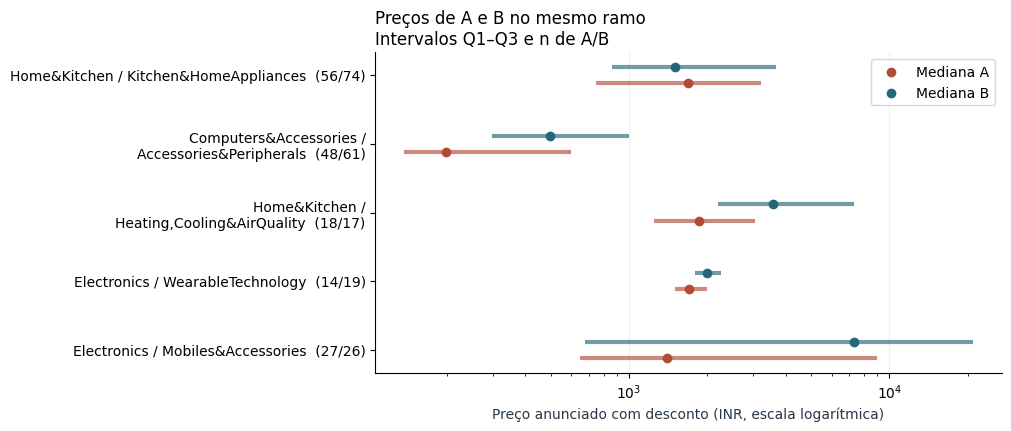

In [65]:
# As medianas em cada célula usam produtos do mesmo ramo e perfil.
focos = dict(zip(ordem_perfis[:3],["A","B","Alta/baixa"]))
perfis_posicao = perfis.merge(posicao[["product_id","pctl_preco","pctl_desconto"]],
    on="product_id",validate="one_to_one")
comparaveis_perfil = perfis_posicao.loc[perfis_posicao.perfil_completo.isin(focos)].assign(
    Classe=lambda d:d.perfil_completo.map(focos),
    Desconto_alto=lambda d:d.pctl_desconto.gt(75).where(d.pctl_desconto.notna()))
def resumir_perfis(grupos):
    return comparaveis_perfil.groupby([*grupos,"Classe"],observed=True).agg(
        n=("product_id","size"), Preco=(preco_inr,"median"),
        Q1=(preco_inr,lambda s:s.quantile(.25)), Q3=(preco_inr,lambda s:s.quantile(.75)),
        Desconto=(percentual,"median"), Reducao=(reducao,"median"),
        Posição_preço=("pctl_preco","median"), Posição_desconto=("pctl_desconto","median"),
        n_posição=("pctl_desconto","count"),
        Taxa_desconto_alto=("Desconto_alto",lambda s:100*s.dropna().mean()))
locais = resumir_perfis(ramo)
por_faixa = resumir_perfis([*ramo,"faixa_preco_original"])
def comparar_com_b(resumo):
    b=resumo.xs("B",level="Classe")
    dados=resumo.drop(index="B",level="Classe").join(
        b[["n","Preco","Desconto","Reducao","Posição_preço","Posição_desconto"]].add_suffix("_B"))
    dados["Preço ÷ B"] = dados.Preco/dados.Preco_B
    dados["Desconto − B (p.p.)"] = dados.Desconto-dados.Desconto_B
    dados["Redução − B (INR)"] = dados.Reducao-dados.Reducao_B
    dados["Posto de preço − B"] = dados["Posição_preço"]-dados["Posição_preço_B"]
    dados["Posto de desconto − B"] = dados["Posição_desconto"]-dados["Posição_desconto_B"]
    return dados
diferencas_locais = comparar_com_b(locais)
diferencas_faixa = comparar_com_b(por_faixa)
# Mínimo exploratório por perfil, além do mínimo de 30 no ramo.
exibiveis = diferencas_locais.loc[diferencas_locais.n.ge(10) & diferencas_locais.n_B.ge(10) &
                                 diferencas_locais.n_posição.eq(diferencas_locais.n)]
colunas_dif = ["n","n_B","Preço ÷ B","Desconto − B (p.p.)","Redução − B (INR)","Posto de preço − B","Posto de desconto − B"]
display(exibiveis[colunas_dif].round(2))
com_faixa = diferencas_faixa.loc[diferencas_faixa.n.ge(10) & diferencas_faixa.n_B.ge(10) &
                                diferencas_faixa.n_posição.eq(diferencas_faixa.n)]
print(f"Contrastes elegíveis: {len(exibiveis)} por ramo e {len(com_faixa)} por ramo e faixa de preço original.")
display(com_faixa[colunas_dif].round(2))
a_b = exibiveis.xs("A",level="Classe").sort_values("Desconto − B (p.p.)")
fig, ax = plt.subplots(figsize=(10,4.2),layout="constrained")
y = np.arange(len(a_b))
for p, cor in [("A","#b04b37"),("B","#276678")]:
    d = locais.xs(p,level="Classe").reindex(a_b.index)
    offset = -.12 if p=="A" else .12
    ax.hlines(y+offset,d.Q1.astype(float),d.Q3.astype(float),color=cor,alpha=.65,linewidth=3)
    ax.scatter(d.Preco.astype(float),y+offset,color=cor,label=f"Mediana {p}",zorder=3)
ax.set_yticks(y,[textwrap.fill(" / ".join(k),39)+f"  ({a}/{int(b)})"
                 for k,a,b in zip(a_b.index,a_b.n,a_b.n_B)])
ax.set(xscale="log",xlabel="Preço anunciado com desconto (INR, escala logarítmica)")
ax.set_title("Preços de A e B no mesmo ramo\nIntervalos Q1–Q3 e n de A/B",loc="left")
ax.legend()
ax.grid(axis="x",alpha=.2)
plt.show()

Usamos mínimo descritivo de 10 produtos em cada perfil e 30 no ramo. Em Mobiles, A tem desconto mediano 8 p.p. abaixo de B e 3 p.p. abaixo na faixa de preço original F4, a única com suporte para esse par. Em Kitchen&HomeAppliances, A supera B nas três faixas elegíveis. Alta/baixa em Accessories&Peripherals supera B em 9,5 p.p. no ramo, mas fica 9,5 p.p. abaixo em F1. Preço anunciado e composição ainda podem variar dentro das faixas.

### 5.7 — A prioridade persiste quando o comparador muda?

Recalculamos os cortes por topo–nível 2 em um cenário auxiliar. Distinguimos os grupos com pelo menos 30 produtos dos grupos menores. A classificação principal continua fixa.

In [66]:
sensibilidade_perfis = classificar_perfis(perfis, ["categoria_nivel_1","categoria_nivel_2"])
transicao = perfis[["product_id","categoria_nivel_1","categoria_nivel_2","rating_num","rating_count_num","perfil_completo","limite_nota","limite_contagem","n_grupo"]].merge(
    sensibilidade_perfis[["product_id","perfil_completo","limite_nota","limite_contagem","n_grupo"]],on="product_id",suffixes=("_oficial","_n2"),validate="one_to_one")
transicao["mudou"] = transicao.perfil_completo_oficial.ne(transicao.perfil_completo_n2)
abreviacoes = dict(zip(ordem_perfis,["A","B","Alta/baixa","Baixa/baixa","Empate","Ausência"]))
matriz_transicao = pd.crosstab(transicao.perfil_completo_oficial,transicao.perfil_completo_n2).reindex(index=ordem_perfis,columns=ordem_perfis,fill_value=0)
display(matriz_transicao.rename(index=abreviacoes,columns=abreviacoes).rename_axis(index="Oficial →",columns="Sensibilidade nível 2"))
resumo_transicao = pd.DataFrame([
    {"Universo":nome,"Produtos":len(d),"Mudanças":int(d.mudou.sum()),"Mudam (%)":100*d.mudou.mean(),"Cobertura dos 1.313 (%)":100*len(d)/len(transicao)}
    for nome,d in [("Três categorias",transicao),("Nível 2 com n ≥ 30",transicao.loc[transicao.n_grupo_n2.ge(30)]),
                   ("Nível 2 com n < 30",transicao.loc[transicao.n_grupo_n2.lt(30)])]
])
display(resumo_transicao.style.hide(axis="index").format(precision=2,decimal=",",thousands="."))
estabilidade_perfis = (transicao.loc[transicao.n_grupo_n2.ge(30)].groupby("perfil_completo_oficial")
    .agg(Elegíveis=("product_id","size"),Mudam=("mudou","sum")))
estabilidade_perfis["Persistem"] = estabilidade_perfis.Elegíveis-estabilidade_perfis.Mudam
estabilidade_perfis["Persistem (%)"] = 100*estabilidade_perfis.Persistem/estabilidade_perfis.Elegíveis
display(estabilidade_perfis.rename(index=abreviacoes).style.format(precision=2,decimal=","))
# Primeiro ID por categoria entre mudanças nos grupos n≥30; sem escolha subjetiva do caso.
exemplos_transicao = transicao.loc[transicao.mudou & transicao.n_grupo_n2.ge(30)].sort_values("product_id").groupby("categoria_nivel_1").head(1)
display(exemplos_transicao[["product_id","categoria_nivel_1","categoria_nivel_2","rating_num","rating_count_num","perfil_completo_oficial","perfil_completo_n2"]]
    .replace({"perfil_completo_oficial":abreviacoes,"perfil_completo_n2":abreviacoes}).style.hide(axis="index")
    .set_properties(**{"max-width":"210px","white-space":"normal","overflow-wrap":"anywhere"}))
display(exemplos_transicao[["product_id","n_grupo_oficial","limite_nota_oficial","limite_contagem_oficial","n_grupo_n2","limite_nota_n2","limite_contagem_n2"]]
    .style.hide(axis="index").format(precision=2,decimal=",",thousands="."))
# QA independente: comparação escalar de um ID com as medianas dos grupos originais.
caso = exemplos_transicao.iloc[0]
for colunas,sufixo in [(["categoria_nivel_1"],"oficial"),(["categoria_nivel_1","categoria_nivel_2"],"n2")]:
    selecao = pd.Series(True,index=perfis.index)
    for c in colunas: selecao &= perfis[c].eq(caso[c])
    grupo = perfis.loc[selecao]
    assert grupo.rating_num.median()==caso["limite_nota_"+sufixo]
    assert grupo.rating_count_num.median()==caso["limite_contagem_"+sufixo]
    assert len(grupo)==caso["n_grupo_"+sufixo]
assert int(transicao.mudou.sum())==229, "Reconciliar mudança total antes de publicar"
assert (int(transicao.n_grupo_n2.ge(30).sum()), int(transicao.loc[transicao.n_grupo_n2.ge(30),"mudou"].sum()))==(1193,167)
assert transicao.perfil_completo_oficial.value_counts().reindex(ordem_perfis).tolist()==[212,299,241,330,228,3]

Sensibilidade nível 2,A,B,Alta/baixa,Baixa/baixa,Empate,Ausência
Oficial →,,,,,,
A,179,1,2,22,8,0
B,3,232,23,2,39,0
Alta/baixa,0,32,176,3,30,0
Baixa/baixa,18,0,2,305,5,0
Empate,6,20,3,10,189,0
Ausência,0,0,0,0,0,3


Universo,Produtos,Mudanças,Mudam (%),Cobertura dos 1.313 (%)
Três categorias,1.313,229,"17,44","100,00"
Nível 2 com n ≥ 30,1.193,167,"14,00","90,86"
Nível 2 com n < 30,120,62,"51,67","9,14"


,Elegíveis,Mudam,Persistem,Persistem (%)
perfil_completo_oficial,,,,
Empate,213,28,185,"86,85"
Baixa/baixa,313,22,291,"92,97"
A,197,31,166,"84,26"
Alta/baixa,222,53,169,"76,13"
B,245,33,212,"86,53"
Ausência,3,0,3,"100,00"


product_id,categoria_nivel_1,categoria_nivel_2,rating_num,rating_count_num,perfil_completo_oficial,perfil_completo_n2
B002PD61Y4,Computers&Accessories,NetworkingDevices,4.100000,8131,A,Baixa/baixa
B005LJQMCK,Electronics,"HomeTheater,TV&Video",4.200000,30023,B,Empate
B00KRCBA6E,Home&Kitchen,"Heating,Cooling&AirQuality",3.800000,1889,Baixa/baixa,A


product_id,n_grupo_oficial,limite_nota_oficial,limite_contagem_oficial,n_grupo_n2,limite_nota_n2,limite_contagem_n2
B002PD61Y4,375,"4,20","7.317,00",30,"4,20","21.358,50"
B005LJQMCK,490,"4,10","9.129,50",156,"4,20","1.532,50"
B00KRCBA6E,448,"4,10","2.305,50",116,"4,10","1.743,50"


Mudam **229/1.313 (17,44%)** no universo completo e **167/1.193 (14,00%)** nos grupos n≥30. Nos outros 120 produtos, 62 mudam (51,67%): grupos pequenos são particularmente sensíveis. A classificação oficial continua A=212/B=299/alta-baixa=241/baixa-baixa=330/empates=228/ausentes=3; os 38 fora permanecem fora. A matriz permite distinguir migração entre quadrantes de mudança para empate.

**Prioridade investigativa:** usar a coluna “Persistem” como conjunto consistente entre esses dois comparadores, sem chamar isso de risco validado ou verdade absoluta. Os demais casos exigem examinar a subcategoria e seus cortes antes de selecionar textos ou fazer recomendações. A estabilidade é específica a este teste, não garantia estatística. Os exemplos mostram os valores originais e os dois pares de cortes para tornar a mudança verificável.

Entre os n≥30, **166/197 produtos A (84,26%)** e **169/222 alta/baixa (76,13%)** persistem no mesmo perfil. Os empates passam de 228 para 271 no universo de 1.313. Exemplo B002PD61Y4: nota 4,1 é inferior a 4,2 nos dois níveis; contagem 8.131 supera o corte 7.317 de Computers (n=375), mas fica abaixo de 21.358,5 de NetworkingDevices (n=30). Por isso A vira baixa/baixa. Isso contextualiza o volume informado entre dispositivos de rede; não transforma o item em produto pior nem apaga sua referência oficial.

In [67]:
instabilidade_ramo = transicao.groupby(ramo).agg(
    Produtos=("product_id", "size"), Mudanças=("mudou", "sum"))
instabilidade_ramo["Mudam (%)"] = instabilidade_ramo.Mudanças.div(instabilidade_ramo.Produtos).mul(100)
display(instabilidade_ramo.loc[instabilidade_ramo.Produtos.ge(30)]
        .sort_values("Mudam (%)", ascending=False).round(2))

Produtos  Mudanças  \
categoria_nivel_1     categoria_nivel_2                                    
Electronics           Headphones,Earbuds&Accessories        63        45   
                      HomeTheater,TV&Video                 156        78   
Computers&Accessories NetworkingDevices                     30        10   
Electronics           WearableTechnology                    62         6   
                      Mobiles&Accessories                  151        10   
Computers&Accessories Accessories&Peripherals              307        14   
Home&Kitchen          Heating,Cooling&AirQuality           116         4   
                      Kitchen&HomeAppliances               308         0   

                                                      Mudam (%)  
categoria_nivel_1     categoria_nivel_2                          
Electronics           Headphones,Earbuds&Accessories      71.43  
                      HomeTheater,TV&Video                50.00  
Computers&Accessories NetworkingDevices                   33.33  
Electronics           WearableTechnology                   9.68  
                      Mobiles&Accessories                  6.62  
Computers&Accessories Accessories&Peripherals              4.56  
Home&Kitchen          Heating,Cooling&AirQuality           3.45  
                      Kitchen&HomeAppliances               0.00

Em Headphones, 45/63 produtos mudam de classe no recorte auxiliar. Em Kitchen&HomeAppliances, a classificação dos 308 permanece igual. O resultado reforça a escolha de exemplos persistentes e de um exemplo que muda, para testar como a função do produto afeta a comparação.

### 5.8 — Que dimensões ajudam a explicar a prioridade de cada caso?

Reunimos atributos comerciais, perfil, diferença para o corte, estabilidade e sinais de extremos. Cada caso retém seus componentes para permitir comparações distintas.

In [68]:
diagnostico = produtos.merge(
    perfis_posicao[["product_id", "perfil_completo", "limite_nota", "limite_contagem", reducao]],
    how="left", on="product_id", validate="one_to_one").merge(
    posicao.drop(columns=[*ramo, preco_inr, percentual]), on="product_id", validate="one_to_one").merge(
    transicao[["product_id", "perfil_completo_n2", "n_grupo_n2", "mudou"]],
    how="left", on="product_id", validate="one_to_one")
diagnostico["perfil_completo"] = diagnostico.perfil_completo.fillna("Fora do recorte")
diagnostico[reducao] = diagnostico[original_inr] - diagnostico[preco_inr]
diagnostico["Estabilidade"] = "Sem comparação com suporte"
comparaveis = diagnostico.n_grupo_n2.ge(30).fillna(False) & diagnostico[colunas_avaliacoes].notna().all(axis=1)
diagnostico.loc[comparaveis, "Estabilidade"] = diagnostico.loc[comparaveis, "mudou"].map({True: "Mudou", False: "Persistiu"})
diagnostico["Distância do corte de nota"] = diagnostico[nota] - diagnostico.limite_nota
diagnostico["Grupos textuais"] = diagnostico.product_id.map(tabelas["ocorrencias_base"].loc[
    lambda d: d.review_content.fillna("").str.strip().ne("")].groupby("product_id").grupo_textual_id.nunique()).fillna(0)
assert len(diagnostico) == len(produtos) and diagnostico.product_id.is_unique
display(pd.crosstab(diagnostico.perfil_completo, diagnostico.Estabilidade))

Estabilidade,Mudou,Persistiu,Sem comparação com suporte
perfil_completo,,,
Empate na nota,28,185,15
Fora do recorte,0,0,38
Nota abaixo; contagem inferior,22,291,17
Nota abaixo; contagem superior,31,166,15
Nota acima; contagem inferior,53,169,19
Nota acima; contagem superior,33,212,54
Sem ambas as medidas,0,0,3


n   Preco  Desconto  Posição_preço  \
Classe     Estabilidade                                                       
A          Mudou                        31  1199.0      63.0           60.3   
           Persistiu                   166  1199.0      47.0           47.1   
           Sem comparação com suporte   15   369.0      25.0           <NA>   
Alta/baixa Mudou                        53  6999.0      46.0           67.9   
           Persistiu                   169   799.0      54.0           52.4   
           Sem comparação com suporte   19   549.0      42.0           <NA>   
B          Mudou                        33  2499.0      38.0           71.5   
           Persistiu                   212  1299.0      39.0           62.1   
           Sem comparação com suporte   54   693.0      40.5           <NA>   

                                       Posição_desconto  n_posição Extremos  \
Classe     Estabilidade                                                       
A          Mudou                                   64.3         31        0   
           Persistiu                               45.1        166        9   
           Sem comparação com suporte              <NA>          0        0   
Alta/baixa Mudou                                   42.3         53        7   
           Persistiu                               56.5        169       17   
           Sem comparação com suporte              <NA>          0        0   
B          Mudou                                   37.8         33        2   
           Persistiu                               33.5        212       42   
           Sem comparação com suporte              <NA>          0        0   

                                       Com_bloco  
Classe     Estabilidade                           
A          Mudou                              31  
           Persistiu                         166  
           Sem comparação com suporte         15  
Alta/baixa Mudou                              53  
           Persistiu                         169  
           Sem comparação com suporte         19  
B          Mudou                              33  
           Persistiu                         212  
           Sem comparação com suporte         54

n  \
categoria_nivel_1 categoria_nivel_2              Estabilidade       
Electronics       Headphones,Earbuds&Accessories Mudou         20   
                                                 Persistiu      5   
                  Mobiles&Accessories            Mudou          5   
                                                 Persistiu     22   

                                                               Posto_preço  \
categoria_nivel_1 categoria_nivel_2              Estabilidade                
Electronics       Headphones,Earbuds&Accessories Mudou                62.3   
                                                 Persistiu            54.0   
                  Mobiles&Accessories            Mudou                64.6   
                                                 Persistiu            43.4   

                                                               Posto_desconto  \
categoria_nivel_1 categoria_nivel_2              Estabilidade                   
Electronics       Headphones,Earbuds&Accessories Mudou                   64.3   
                                                 Persistiu               36.5   
                  Mobiles&Accessories            Mudou                   29.5   
                                                 Persistiu               25.2   

                                                               Desconto_alto  \
categoria_nivel_1 categoria_nivel_2              Estabilidade                  
Electronics       Headphones,Earbuds&Accessories Mudou                     9   
                                                 Persistiu                 1   
                  Mobiles&Accessories            Mudou                     0   
                                                 Persistiu                 5   

                                                              Extremos  \
categoria_nivel_1 categoria_nivel_2              Estabilidade            
Electronics       Headphones,Earbuds&Accessories Mudou               0   
                                                 Persistiu           0   
                  Mobiles&Accessories            Mudou               0   
                                                 Persistiu           0   

                                                               Delta_nota  \
categoria_nivel_1 categoria_nivel_2              Estabilidade               
Electronics       Headphones,Earbuds&Accessories Mudou               -0.2   
                                                 Persistiu           -0.3   
                  Mobiles&Accessories            Mudou               -0.1   
                                                 Persistiu           -0.1   

                                                               Razao_contagem  \
categoria_nivel_1 categoria_nivel_2              Estabilidade                   
Electronics       Headphones,Earbuds&Accessories Mudou                    2.2   
                                                 Persistiu                9.6   
                  Mobiles&Accessories            Mudou                    1.4   
                                                 Persistiu                2.6   

                                                               Desconto alto (%)  
categoria_nivel_1 categoria_nivel_2              Estabilidade                     
Electronics       Headphones,Earbuds&Accessories Mudou                      45.0  
                                                 Persistiu                  20.0  
                  Mobiles&Accessories            Mudou                       0.0  
                                                 Persistiu                  22.7

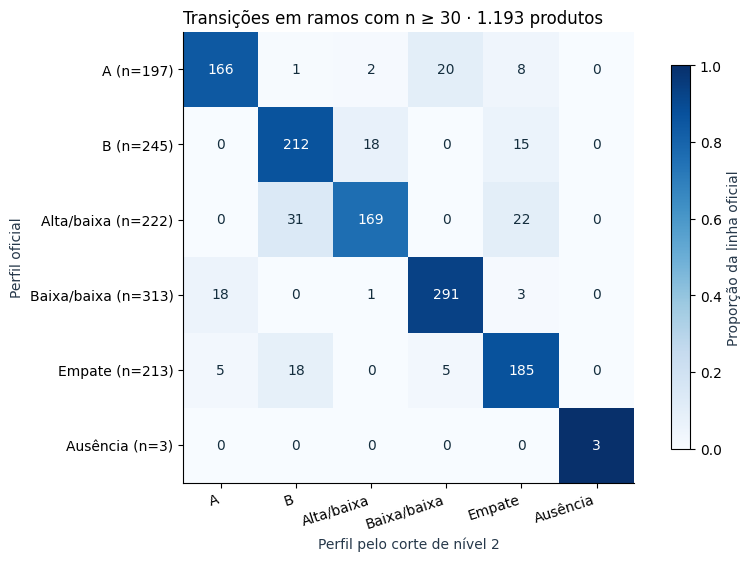

In [69]:
# Estabilidade por ramo condiciona a interpretação comercial do perfil.
alvos = diagnostico.loc[diagnostico.perfil_completo.isin(focos)].copy()
alvos["Classe"] = alvos.perfil_completo.map(focos)
alvos["Desconto alto"] = alvos.pctl_desconto.gt(75).where(alvos.pctl_desconto.notna())
alvos["Preço extremo"] = alvos.product_id.map(flags_n2[preco_inr]).where(alvos.pctl_preco.notna())
alvos["Contagem ÷ corte"] = alvos[contagem]/alvos.limite_contagem
grupos_estaveis = alvos.groupby(["Classe","Estabilidade"]).agg(
    n=("product_id","size"), Preco=(preco_inr,"median"), Desconto=(percentual,"median"),
    Posição_preço=("pctl_preco","median"), Posição_desconto=("pctl_desconto","median"),
    n_posição=("pctl_preco","count"), Extremos=("Preço extremo","sum"),
    Com_bloco=("Grupos textuais",lambda s:s.gt(0).sum()))
display(grupos_estaveis.round(1))
a_estabilidade = alvos.loc[alvos.Classe.eq("A") & alvos.Estabilidade.ne("Sem comparação com suporte")]
a_local_est = a_estabilidade.groupby([*ramo,"Estabilidade"]).agg(
    n=("product_id","size"), Posto_preço=("pctl_preco","median"),
    Posto_desconto=("pctl_desconto","median"), Desconto_alto=("Desconto alto","sum"),
    Extremos=("Preço extremo","sum"), Delta_nota=("Distância do corte de nota","median"),
    Razao_contagem=("Contagem ÷ corte","median"))
a_local_est["Desconto alto (%)"]=100*a_local_est.Desconto_alto/a_local_est.n
suporte_a = a_local_est.n.unstack(fill_value=0).ge(5).all(axis=1)
display(a_local_est.loc[a_local_est.index.droplevel(-1).isin(suporte_a[suporte_a].index)].round(1))
transicoes_com_suporte = transicao.loc[transicao.n_grupo_n2.ge(30)]
matriz_suporte = pd.crosstab(transicoes_com_suporte.perfil_completo_oficial,
                            transicoes_com_suporte.perfil_completo_n2).reindex(
    index=ordem_perfis,columns=ordem_perfis,fill_value=0)
taxas = matriz_suporte.div(matriz_suporte.sum(axis=1),axis=0)
fig, ax = plt.subplots(figsize=(8.5,5.5),layout="constrained")
im=ax.imshow(taxas.astype(float),cmap="Blues",vmin=0,vmax=1)
nomes=[abreviacoes[p] for p in ordem_perfis]
ax.set_xticks(range(len(nomes)),nomes,rotation=18,ha="right")
ax.set_yticks(range(len(nomes)),[f"{nome} (n={n})" for nome,n in zip(nomes,matriz_suporte.sum(axis=1))])
for i,j in np.ndindex(taxas.shape):
    v=taxas.iloc[i,j]
    ax.text(j,i,str(matriz_suporte.iloc[i,j]),ha="center",va="center",
            color="white" if v>.56 else "#142e3e")
ax.set(xlabel="Perfil pelo corte de nível 2",ylabel="Perfil oficial")
ax.set_title("Transições em ramos com n ≥ 30 · 1.193 produtos",loc="left")
fig.colorbar(im,ax=ax,label="Proporção da linha oficial",shrink=.85)
plt.show()

Entre A com suporte, 166 persistem e 31 mudam. Os grupos têm o mesmo preço mediano de INR 1.199, com descontos de 47% e 63%. O contraste de desconto alto aparece em Headphones e se inverte em Mobiles. Com n pequenos, esse resultado orienta a escolha de pares. Nove A persistentes têm preço com desconto sinalizado no ramo. Entre os 53 alta/baixa que mudam, 31 passam para B e 22 para empate.

### 5.9 — Quais casos reais ilustram os contrastes?

Os pares mantêm a função no caminho oficial sempre que a cobertura permite. Há um caso sensível ao comparador e um caso de preço local discrepante. Os critérios e o desempate por ID deixam a seleção reproduzível.

In [70]:
# Pares no mesmo caminho com proximidade definida antes de ler os textos.
def par_funcional(base, ramo_alvo, classe, campo_distancia, min_por_classe=2):
    d=base.loc[base[ramo[1]].eq(ramo_alvo) & base.Classe.isin([classe,"B"])]
    contagens=d.groupby(["category_original","Classe"]).size().unstack(fill_value=0)
    possiveis=contagens.loc[contagens[[classe,"B"]].ge(min_por_classe).all(axis=1)].copy()
    possiveis["suporte"]=possiveis.sum(axis=1)
    caminho=possiveis.reset_index().sort_values(["suporte","category_original"],ascending=[False,True]).iloc[0].category_original
    d=d.loc[d.category_original.eq(caminho)]
    a=d.loc[d.Classe.eq(classe)]
    b=d.loc[d.Classe.eq("B")]
    pares=a[["product_id",campo_distancia]].merge(b[["product_id",campo_distancia]],how="cross",suffixes=("_1","_2"))
    pares["distancia"]=(pares[campo_distancia+"_1"]-pares[campo_distancia+"_2"]).abs()
    vencedor=pares.sort_values(["distancia","product_id_1","product_id_2"]).iloc[0]
    ids=[vencedor.product_id_1,vencedor.product_id_2]
    return d.set_index("product_id").loc[ids].reset_index()

blocos_casos=[]
for titulo, ramo_alvo, classe, variavel, hipotese, pergunta in [
    ("Fones A/B", "Headphones,Earbuds&Accessories","A","pctl_preco",
     "Atributos de uso podem distinguir avaliações em preços semelhantes.",
     "O que muda nas menções a conforto, conexão e durabilidade?"),
    ("Acessórios de informática A/B","Accessories&Peripherals","A","pctl_preco",
     "A compatibilidade pode distinguir produtos de função e preços próximos.",
     "Que equipamentos, conectores ou situações de uso aparecem nos blocos?"),
    ("Eletrodomésticos alta/baixa e B","Kitchen&HomeAppliances","Alta/baixa","pctl_desconto",
     "Produtos com descontos relativos semelhantes podem receber elogios a atributos diferentes.",
     "Que atributos de uso e manutenção aparecem em cada produto?")]:
    par=par_funcional(alvos,ramo_alvo,classe,variavel)
    blocos_casos.append(par.assign(Caso=titulo,
        Critério="Caminho com maior suporte comum; menor diferença no posto de "+("preço" if variavel=="pctl_preco" else "desconto"),
        Hipótese=hipotese,Pergunta=pergunta,Limitação="O caminho pode reunir especificações e marcas distintas."))
caso_mudanca=alvos.loc[alvos.Classe.eq("A") & alvos.Estabilidade.eq("Mudou") &
                        alvos[ramo[1]].ne("Headphones,Earbuds&Accessories")].copy()
caso_mudanca["prioridade"]=caso_mudanca["Distância do corte de nota"].abs()
caso_mudanca=caso_mudanca.sort_values(["prioridade","product_id"]).head(1)
blocos_casos.append(caso_mudanca.assign(Caso="A sensível ao comparador",
    Critério="Menor distância da nota ao corte oficial fora de Headphones",
    Hipótese="O ramo pode explicar parte da mudança de prioridade.",
    Pergunta="Que especificação ou uso sugere um grupo de comparação mais preciso?",
    Limitação="A mudança decorre dos cortes auxiliares."))
caso_extremo=alvos.loc[alvos.Classe.eq("A") & alvos.Estabilidade.eq("Persistiu") &
                       alvos["Preço extremo"].eq(True)].copy()
caso_extremo=caso_extremo.loc[~caso_extremo.product_id.isin(pd.concat(blocos_casos).product_id)]
caso_extremo=caso_extremo.sort_values(["distancia_preco_pct","product_id"],ascending=[False,True]).head(1)
blocos_casos.append(caso_extremo.assign(Caso="A persistente com preço extremo",
    Critério="Maior distância positiva à mediana local entre A persistentes sinalizados",
    Hipótese="Especificações e acessórios podem contextualizar a distância de preço.",
    Pergunta="Os blocos descrevem características específicas ou expectativa de valor?",
    Limitação="O sinal depende do IIQ do ramo."))
casos=pd.concat(blocos_casos,ignore_index=True)
assert len(casos)==8 and casos.product_id.is_unique and casos[topo].nunique()==3
display(casos.set_index("product_id")[["Caso","product_name","category_original","source_index_referencia"]]
    .style.set_properties(**{"overflow-wrap":"anywhere","max-width":"280px"}))
display(casos.set_index("product_id")[[original_inr,preco_inr,percentual,nota,contagem,"Classe",
    "perfil_completo_n2","pctl_preco","pctl_desconto","Grupos textuais"]].rename(columns=rotulos_medidas).round(1))
display(casos.drop_duplicates("Caso").set_index("Caso")[["Critério","Hipótese","Limitação","Pergunta"]]
    .style.set_properties(**{"overflow-wrap":"anywhere","max-width":"220px"}))

,Caso,product_name,category_original,source_index_referencia
product_id,,,,
B07JQKQ91F,Fones A/B,"JBL C50HI, Wired in Ear Headphones with Mic, One Button Multi-Function Remote, Lightweight & Comfortable fit (Black)","Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear",601
B01F25X6RQ,Fones A/B,Samsung Ehs64 Ehs64Avfwecinu Hands-Free Wired In Ear Earphones With Mic With Remote Note (White),"Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear",466
B01LONQBDG,Acessórios de informática A/B,AmazonBasics USB Type-C to Micro-B 2.0 Cable - 6 Inches (15.2 Centimeters) - White,Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,294
B071SDRGWL,Acessórios de informática A/B,"boAt Type-c A400 Type-c to USB A Cable for All Type C Phones (Lg nexus 5x), 1Mtr(Black)",Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,139
B076VQS87V,Eletrodomésticos alta/baixa e B,Syska SDI-07 1000 W Stellar with Golden American Heritage Soleplate Dry Iron (Blue),"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Irons,Steamers&Accessories|Irons|DryIrons",1447
B009P2L7CO,Eletrodomésticos alta/baixa e B,"Bajaj DHX-9 1000W Heavy Weight Dry Iron with Advance Soleplate and Anti-Bacterial German Coating Technology, Ivory","Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Irons,Steamers&Accessories|Irons|DryIrons",1209
B09JS562TP,A sensível ao comparador,"Motorola a10 Dual Sim keypad Mobile with 1750 mAh Battery, Expandable Storage Upto 32GB, Wireless FM with Recording - Rose Gold",Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|BasicMobiles,455
B096NTB9XT,A persistente com preço extremo,"Aquaguard Aura RO+UV+UF+Taste Adjuster(MTDS) with Active Copper & Zinc 7L water purifier,8 stages of purification,suitable for borewell,tanker,municipal water(Black) from Eureka Forbes",Home&Kitchen|Kitchen&HomeAppliances|WaterPurifiers&Accessories|WaterFilters&Purifiers,1325


,Original (INR),Com desconto (INR),Desconto (%),Nota,Contagem informada,Classe,perfil_completo_n2,pctl_preco,pctl_desconto,Grupos textuais
product_id,,,,,,,,,,
B07JQKQ91F,999.0,499.0,50.0,3.9,92995,A,Empate na nota,31.0,23.0,1
B01F25X6RQ,499.0,499.0,0.0,4.2,31539,B,Nota acima; contagem inferior,31.0,1.6,1
B01LONQBDG,899.0,349.0,61.0,4.1,14896,A,Nota abaixo; contagem superior,50.8,54.7,1
B071SDRGWL,699.0,349.0,50.0,4.3,20850,B,Nota acima; contagem superior,50.8,32.2,1
B076VQS87V,799.0,457.0,43.0,4.3,1868,Alta/baixa,Nota acima; contagem inferior,18.2,50.8,1
B009P2L7CO,1920.0,1099.0,43.0,4.2,9772,B,Nota acima; contagem superior,46.8,50.8,1
B09JS562TP,1630.0,1399.0,14.0,4.0,9378,A,Nota abaixo; contagem inferior,45.4,8.3,1
B096NTB9XT,24500.0,15999.0,35.0,4.0,11206,A,Nota abaixo; contagem superior,99.4,36.4,1


,Critério,Hipótese,Limitação,Pergunta
Caso,,,,
Fones A/B,Caminho com maior suporte comum; menor diferença no posto de preço,Atributos de uso podem distinguir avaliações em preços semelhantes.,O caminho pode reunir especificações e marcas distintas.,"O que muda nas menções a conforto, conexão e durabilidade?"
Acessórios de informática A/B,Caminho com maior suporte comum; menor diferença no posto de preço,A compatibilidade pode distinguir produtos de função e preços próximos.,O caminho pode reunir especificações e marcas distintas.,"Que equipamentos, conectores ou situações de uso aparecem nos blocos?"
Eletrodomésticos alta/baixa e B,Caminho com maior suporte comum; menor diferença no posto de desconto,Produtos com descontos relativos semelhantes podem receber elogios a atributos diferentes.,O caminho pode reunir especificações e marcas distintas.,Que atributos de uso e manutenção aparecem em cada produto?
A sensível ao comparador,Menor distância da nota ao corte oficial fora de Headphones,O ramo pode explicar parte da mudança de prioridade.,A mudança decorre dos cortes auxiliares.,Que especificação ou uso sugere um grupo de comparação mais preciso?
A persistente com preço extremo,Maior distância positiva à mediana local entre A persistentes sinalizados,Especificações e acessórios podem contextualizar a distância de preço.,O sinal depende do IIQ do ramo.,Os blocos descrevem características específicas ou expectativa de valor?


Os pares de cabos e fones têm preços iguais dentro de seus caminhos. Os cabos preservam A e B no cenário auxiliar, enquanto os fones mudam de classe. Os ferros mantêm desconto igual com preços distintos. A comparação por função ajuda a formular perguntas sobre especificação, conforto e valor.

### 5.10 — Que comparações devem seguir para Customer Insights?

1. **Começar pelos pares de função e preço próximos.** Os cabos USB B01LONQBDG e B071SDRGWL custam INR 349 e preservam os perfis nos dois cortes. Os fones B07JQKQ91F e B01F25X6RQ custam INR 499, com descontos de 50% e 0%, e mudam de classe no corte auxiliar. A leitura dos dois pares permite contrastar compatibilidade e conforto sob referências diferentes.
2. **Separar casos sensíveis de casos persistentes.** Comparar o celular básico B09JS562TP com outros produtos do mesmo caminho e examinar o purificador B096NTB9XT em relação às especificações e aos itens incluídos. O primeiro muda de classe e o segundo permanece A com preço no posto 99,4 do ramo.
3. **Investigar atributos valorizados.** Os ferros B076VQS87V e B009P2L7CO têm o mesmo desconto de 43% e preços de INR 457 e INR 1.099. Ler menções a uso e manutenção à luz dessa diferença.

Cada ID selecionado tem um grupo textual disponível. A elegibilidade qualitativa e as dependências entre blocos serão examinadas na próxima etapa.

## 6 — Síntese gerencial, indicadores e transição

### 6.1 — Quais evidências orientam a investigação?

A síntese reúne os resultados que mudam a forma de selecionar categorias, comparar preços e priorizar a leitura de comentários.

- **A função muda a comparação comercial (§3.3 e §3.8).** Em Mobiles, as medianas com desconto são INR 436,50 em acessórios (74 produtos) e INR 12.999 em telefones (77). Entre os 68 produtos de Mobiles com suporte no ramo e no caminho, 44 mudam pelo menos 20 pontos no posto percentual de preço. Exibir o ramo e o caminho com o preço evita que um único referencial esconda essas diferenças.
- **O desconto depende do contexto do perfil (§5.6).** O desconto mediano de A supera B nos três topos. Em Mobiles e Wearable, fica 8 e 5,5 p.p. abaixo de B, respectivamente. Em Kitchen&HomeAppliances, fica 12 p.p. acima e a direção se mantém nas três faixas de preço original com suporte.
- **A estabilidade muda a seleção de casos (§5.7–5.9).** Dos 197 A em ramos com suporte, 166 persistem. Em Headphones, 9 de 20 A que mudam têm desconto acima do P75 local, frente a 1 de 5 persistentes. Em Mobiles, a comparação é 0 de 5 e 5 de 22. A comparação dentro de cada ramo é necessária mesmo quando o contraste agregado parece claro.

### 6.2 — Matriz de evidências e decisões

| Prioridade e evidência | Interpretação e hipótese a investigar | Risco de interpretação | Ação e dado adicional |
|---|---|---|---|
| Alta · Mobiles, 44/68 deslocam ≥20 pontos no posto de preço | A função define referências comerciais distintas | Ler a distância como sobrepreço | Separar acessórios e telefones no drill-down. Obter especificações, preço pago e custos para decisões de preço |
| Alta · Cabos USB e fones com pares de mesmo preço, §5.9 | Compatibilidade e conforto podem esclarecer diferenças entre perfis | Atribuir a diferença de nota a desconto ou defeito | Revisar blocos dos pares. Usar devoluções e suporte para avaliar incidência |
| Alta · Headphones, 45/63 mudam de classe, e 20/25 A mudam | O comparador condiciona a prioridade | Tratar persistência como risco comprovado | Segmentar sensíveis e persistentes para leitura. Conferir função, especificações e independência dos textos |
| Média · Kitchen&HomeAppliances, A–B de +6,5 a +16 p.p. nas três faixas elegíveis | O contraste de desconto se mantém neste ramo nas faixas observadas | Inferir efeito promocional | Investigar expectativas de valor. Exigir histórico, transações e exposição para avaliar promoção |
| Média · Desconto × nota, −0,150 geral (1.350), +0,154 em Mobiles (151) e +0,242 em Wearable (62) | Mix e expectativas podem variar entre contextos | Tratar associação de postos como causalidade | Ler menções explícitas a valor em cada função. Verificar hipótese com histórico e desenho de comparação |

### 6.3 — Quais indicadores interessam à gestão?

O catálogo de KPIs define K01–K12, incluindo elegibilidade, unidade, denominador, filtros e tratamento de ausências. Os cards cobrem portfólio, preço com desconto, desconto anunciado, nota e contagem. Coberturas acompanham as medidas e a leitura dos perfis.

### 6.4 — O que muda quando filtramos o BI?

Os cortes são fixos. As medianas usam os produtos visíveis. Participação do perfil retira somente o filtro de perfil do denominador elegível. Participação hierárquica conserva o pai e a seleção externa.

In [71]:
visao_filtros=avaliacoes.merge(perfis[["product_id","perfil_completo","limite_nota","limite_contagem"]],on="product_id",how="left",validate="one_to_one")
visao_filtros["perfil_completo"]=visao_filtros.perfil_completo.fillna("Fora do recorte")

def mediana_disponivel(serie):
    validos=serie.dropna()
    return validos.median() if len(validos) else float("nan")

def simular_contexto(nome, categorias=None, subcategoria=None, preco_max=None, perfil=None, somente_ausencias=False):
    externo=visao_filtros.copy()
    if categorias is not None: externo=externo.loc[externo.categoria_nivel_1.isin(categorias)]
    if subcategoria is not None: externo=externo.loc[externo.categoria_nivel_2.eq(subcategoria)]
    if preco_max is not None: externo=externo.loc[externo.discounted_price_num.le(preco_max)]
    if somente_ausencias: externo=externo.loc[externo[["rating_num","rating_count_num"]].isna().any(axis=1)]
    # Remover APENAS o filtro de perfil no denominador; todos os externos já foram aplicados.
    elegivel=~externo.perfil_completo.isin(["Sem ambas as medidas","Fora do recorte"])
    visivel=externo if perfil is None else externo.loc[externo.perfil_completo.eq(perfil)]
    alvo=perfil or "Nota acima; contagem inferior"
    numerador=int(externo.perfil_completo.eq(alvo).sum())
    denominador=int(elegivel.sum())
    base_cortes=perfis.set_index("product_id")
    presentes=visivel.loc[~visivel.perfil_completo.eq("Fora do recorte")].set_index("product_id")
    assert presentes.limite_nota.eq(base_cortes.limite_nota.reindex(presentes.index)).all()
    assert presentes.limite_contagem.eq(base_cortes.limite_contagem.reindex(presentes.index)).all()
    assert visivel.product_id.is_unique and numerador<=denominador
    return {"Caso":nome,"Perfil da participação":alvo,"n externo":len(externo),"n visível":len(visivel),
        "Numerador":numerador,"Denominador elegível":denominador,"Participação (%)":100*numerador/denominador if denominador else float("nan"),
        "Preço mediano INR":mediana_disponivel(visivel.discounted_price_num),"Desconto mediano %":mediana_disponivel(visivel.discount_percentage_num),
        "Redução mediana INR":mediana_disponivel(visivel[reducao]),"Original mediano INR":mediana_disponivel(visivel[original_inr]),"n par visível":int(visivel[colunas_avaliacoes].notna().all(axis=1).sum()),"n no recorte externo":int(externo.categoria_nivel_1.isin(maiores_categorias).sum()),"Nota mediana":mediana_disponivel(visivel.rating_num),"Contagem mediana":mediana_disponivel(visivel.rating_count_num),
        "n nota visível":int(visivel.rating_num.count()),"n contagem visível":int(visivel.rating_count_num.count())}

casos_oraculo=pd.DataFrame([
    simular_contexto("Base completa"),
    simular_contexto("Electronics",["Electronics"]),
    simular_contexto("Electronics + Home",["Electronics","Home&Kitchen"]),
    simular_contexto("Electronics / Headphones",["Electronics"],"Headphones,Earbuds&Accessories"),
    simular_contexto("OfficeProducts",["OfficeProducts"]),
    simular_contexto("Electronics / preço ≤ 899",["Electronics"],preco_max=899),
    simular_contexto("Electronics / A",["Electronics"],perfil=ordem_perfis[0]),
    simular_contexto("Electronics / alta-baixa",["Electronics"],perfil=ordem_perfis[2]),
    simular_contexto("Electronics / preço ≤ 899 / A",["Electronics"],preco_max=899,perfil=ordem_perfis[0]),
    simular_contexto("Electronics + Home / A",["Electronics","Home&Kitchen"],perfil=ordem_perfis[0]),
    simular_contexto("Electronics / preço ≤ 0 / A",["Electronics"],preco_max=0,perfil=ordem_perfis[0]),
    simular_contexto("Computers / medidas ausentes",["Computers&Accessories"],somente_ausencias=True),
])
display(casos_oraculo[["Caso","Perfil da participação","n externo","n visível","Numerador","Denominador elegível","Participação (%)"]]
    .replace({"Perfil da participação":abreviacoes}).set_index("Caso").style.format(precision=2,decimal=",",na_rep="Não aplicável")
    .set_properties(**{"max-width":"190px","white-space":"normal"}))
display(casos_oraculo[["Caso","Preço mediano INR","Desconto mediano %","Nota mediana","n nota visível","Contagem mediana","n contagem visível"]]
    .set_index("Caso").style.format(precision=2,decimal=",",thousands=".",na_rep="Não aplicável"))
oraculos=casos_oraculo.set_index("Caso")
assert oraculos.loc["Electronics / A",["Numerador","Denominador elegível"]].tolist()==[75,490]
assert oraculos.loc["Electronics / alta-baixa",["Numerador","Denominador elegível"]].tolist()==[110,490]
assert oraculos.loc["Electronics / preço ≤ 899 / A",["Numerador","Denominador elegível"]].tolist()==[28,199]
assert oraculos.loc["Electronics + Home / A",["Numerador","Denominador elegível"]].tolist()==[153,937]
assert pd.isna(oraculos.loc["Electronics / preço ≤ 0 / A","Participação (%)"])
assert pd.isna(oraculos.loc["Computers / medidas ausentes","Contagem mediana"])
# Participação de categoria: exemplos calculados por seleção, não por números literais.
e=visao_filtros.loc[visao_filtros.categoria_nivel_1.eq("Electronics")]
eh=visao_filtros.loc[visao_filtros.categoria_nivel_1.isin(["Electronics","Home&Kitchen"])]
head=e.loc[e.categoria_nivel_2.eq("Headphones,Earbuds&Accessories")]
e_preco=e.loc[e.discounted_price_num.le(899)]
todos_preco=visao_filtros.loc[visao_filtros.discounted_price_num.le(899)]
participacoes_categoria=pd.DataFrame([
    {"Caso":nome,"Numerador":len(num),"Denominador":len(den),"Participação (%)":100*len(num)/len(den)}
    for nome,num,den in [("Electronics no catálogo",e,visao_filtros),("Electronics na seleção E+Home",e,eh),
        ("Headphones no pai Electronics",head,e),("Electronics / preço ≤ 899 no catálogo com mesmo preço",e_preco,todos_preco)]])
display(participacoes_categoria.style.hide(axis="index").format(precision=2,decimal=","))

,Perfil da participação,n externo,n visível,Numerador,Denominador elegível,Participação (%)
Caso,,,,,,
Base completa,Alta/baixa,1351,1351,241,1310,"18,40"
Electronics,Alta/baixa,490,490,110,490,"22,45"
Electronics + Home,Alta/baixa,938,938,178,937,"19,00"
Electronics / Headphones,Alta/baixa,63,63,2,63,"3,17"
OfficeProducts,Alta/baixa,31,31,0,0,Não aplicável
Electronics / preço ≤ 899,Alta/baixa,199,199,49,199,"24,62"
Electronics / A,A,490,75,75,490,"15,31"
Electronics / alta-baixa,Alta/baixa,490,110,110,490,"22,45"
Electronics / preço ≤ 899 / A,A,199,28,28,199,"14,07"


,Preço mediano INR,Desconto mediano %,Nota mediana,n nota visível,Contagem mediana,n contagem visível
Caso,,,,,,
Base completa,"899,00","49,00","4,10",1.350,"4.740,00",1.349
Electronics,"1.384,00","52,00","4,10",490,"9.129,50",490
Electronics + Home,"1.299,00","46,00","4,10",937,"4.170,50",938
Electronics / Headphones,"849,00","63,00","3,90",63,"37.817,00",63
OfficeProducts,"178,00","5,00","4,30",31,"4.426,00",31
Electronics / preço ≤ 899,"349,00","61,00","4,10",199,"3.492,00",199
Electronics / A,"1.299,00","60,00","3,90",75,"21.796,00",75
Electronics / alta-baixa,"1.137,00","48,50","4,30",110,"1.744,50",110
Electronics / preço ≤ 899 / A,"449,00","62,50","3,90",28,"18.428,00",28


Caso,Numerador,Denominador,Participação (%)
Electronics no catálogo,490,1351,"36,27"
Electronics na seleção E+Home,490,938,"52,24"
Headphones no pai Electronics,63,490,"12,86"
Electronics / preço ≤ 899 no catálogo com mesmo preço,199,690,"28,84"


Electronics+A resulta em **75/490=15,31%**, não 75/75. Com preço≤INR 899, A é **28/199=14,07%**. Na multiseleção Electronics+Home, A é **153/937=16,33%**; o produto sem nota de Home fica fora do denominador classificável. Medianas recalculadas sobre o perfil selecionado respondem a outra pergunta e estão na tabela de valores visíveis.

O filtro de preço também permanece no denominador de participação de categoria. OfficeProducts conserva seus 31 produtos e medianas, mas não tem perfil oficial. O recorte de Computers com contagens ausentes tem nota observada e contagem mediana não aplicável. Os cortes não mudam em nenhum desses cliques.

Os casos acima são referências calculadas em pandas. A futura implementação deve reproduzi-los no Desktop. Consulte o [catálogo de KPIs e mapa do BI](catalogo_kpis_mapa_bi.md) para o contrato de relacionamento e a seleção de visuais.

### 6.5 — Que evidência textual pode ser usada na próxima etapa?

O bloco da ocorrência é a unidade de disponibilidade. O grupo textual exato deduplica título e conteúdo. A ponte conserva as posições e permite relacionar review a produto sem atribuir o bloco a um autor.

In [72]:
catalogo_integral = produtos.astype("string")
origens = fontes_atuais["ocorrencias_catalogo"].astype("string")
usuarios = tabelas["usuarios"].astype("string")
reviews = tabelas["reviews"].astype("string")
ponte = tabelas["vinculos_reviews"].astype("string")
verificacoes=[]
def conferir(nome,condicao):
    ok=bool(condicao)
    verificacoes.append({"Verificação":nome,"Aprovada":ok})
    assert ok,nome

tabelas_contexto={"produtos":catalogo_integral,"ocorrencias":origens,"usuarios":usuarios,"reviews":reviews,"ponte":ponte}
chaves={"produtos":["product_id"],"ocorrencias":["ocorrencia_id"],"usuarios":["user_id"],"reviews":["review_id"],"ponte":["ocorrencia_id","posicao_na_linha"]}
for nome,d in tabelas_contexto.items():
    conferir(f"{nome}: chave completa e única",d[chaves[nome]].notna().all().all() and not d.duplicated(chaves[nome]).any())
conferir("Ocorrências: cobertura exata dos produtos",set(origens.product_id)==set(catalogo_integral.product_id))
for campo,dim in [("ocorrencia_id",origens),("product_id",catalogo_integral),("user_id",usuarios),("review_id",reviews)]:
    conferir(f"Ponte → {campo}: sem órfãos",ponte[campo].isin(dim[campo]).all())
ref=catalogo_integral.merge(origens,on="product_id",suffixes=("_p","_o"),validate="one_to_many")
ref=ref.loc[ref.source_index_referencia.eq(ref.source_index) & ref.ocorrencia_id_referencia.eq(ref.ocorrencia_id)]
conferir("Referência real: uma por produto",len(ref)==len(catalogo_integral) and ref.product_id.is_unique)
campos_referencia=["actual_price_num","discounted_price_num","discount_percentage_num","rating_num","rating_count_num"]
conferir("Medidas da mesma ocorrência real",all(ref[c+"_p"].fillna("__AUSENTE__").eq(ref[c+"_o"].fillna("__AUSENTE__")).all() for c in campos_referencia))
ctx=ponte.merge(origens[["ocorrencia_id","product_id","source_index","grupo_textual_id"]],
    on="ocorrencia_id",suffixes=("","_origem"),validate="many_to_one")
conferir("Produto e source_index concordantes",ctx.product_id.eq(ctx.product_id_origem).all() and ctx.source_index.eq(ctx.source_index_origem).all())
posicoes=ponte.assign(posicao=pd.to_numeric(ponte.posicao_na_linha)).groupby("ocorrencia_id").posicao
conferir("Posições consecutivas 1..N e cobertura de ocorrências",set(ponte.ocorrencia_id)==set(origens.ocorrencia_id) and posicoes.apply(lambda s:sorted(s)==list(range(1,len(s)+1))).all())
ctx=ctx.merge(reviews[["review_id","user_id"]],on="review_id",suffixes=("","_autor"),validate="many_to_one")
conferir("Autoria consistente e usuário de review existente",ctx.user_id.eq(ctx.user_id_autor).all() and reviews.user_id.isin(usuarios.user_id).all())
ctx=ctx.merge(catalogo_integral[["product_id","categoria_nivel_1"]],on="product_id",validate="many_to_one").merge(
    usuarios[["user_id","situacao_nome"]],on="user_id",validate="many_to_one")
conferir("Junção contextual conserva 11.503 posições",len(ctx)==len(ponte)==11503)
pares_textuais=origens[["review_title","review_content","grupo_textual_id"]].drop_duplicates()
conferir("Grupo textual: um par exato, sem fusão",pares_textuais.grupo_textual_id.is_unique and not pares_textuais.duplicated(["review_title","review_content"]).any())
contextos_review=ctx.groupby("review_id").grupo_textual_id.nunique()
diagnostico_corpus=pd.DataFrame({"Medida":["Grupos textuais exatos","Reviews em múltiplos grupos contextuais","Pares produto–grupo","Ponte antes","Contexto depois"],
    "Quantidade":[origens.grupo_textual_id.nunique(),int(contextos_review.gt(1).sum()),len(origens[["product_id","grupo_textual_id"]].drop_duplicates()),len(ponte),len(ctx)]})
display(diagnostico_corpus.style.hide(axis="index"))
display(ctx.loc[ctx.review_id.eq("R1O4Z15FD40PV5"),["review_id","ocorrencia_id","product_id","grupo_textual_id"]].head(3).style.hide(axis="index"))
display(pd.DataFrame({"Verificações relacionais": [len(verificacoes)], "Aprovadas": [sum(v["Aprovada"] for v in verificacoes)]}))
assert origens.grupo_textual_id.nunique()==1212 and contextos_review.gt(1).sum()==199

Medida,Quantidade
Grupos textuais exatos,1212
Reviews em múltiplos grupos contextuais,199
Pares produto–grupo,1370
Ponte antes,11503
Contexto depois,11503


review_id,ocorrencia_id,product_id,grupo_textual_id
R1O4Z15FD40PV5,OC-000024,B09NHVCHS9,TXT-000024
R1O4Z15FD40PV5,OC-000045,B09NJN8L25,TXT-000024
R1O4Z15FD40PV5,OC-000082,B09NKZXMWJ,TXT-000082


,Verificações relacionais,Aprovadas
0,17,17


In [73]:
# Disponibilidade de conteúdo não é qualidade/anotabilidade nem opinião independente.
corpus_contextual=origens[["ocorrencia_id","product_id","grupo_textual_id","review_content"]].merge(
    visao_filtros[["product_id","categoria_nivel_1","categoria_nivel_2","perfil_completo"]],on="product_id",validate="many_to_one")
corpus_contextual["texto_disponivel"]=corpus_contextual.review_content.notna() & corpus_contextual.review_content.str.strip().ne("").fillna(False)
corpus_disponivel=corpus_contextual.loc[corpus_contextual.texto_disponivel]
pares_corpus=corpus_disponivel[["product_id","grupo_textual_id","perfil_completo"]].drop_duplicates()
compartilhamento_grupos=pares_corpus.groupby("grupo_textual_id").agg(Produtos=("product_id","nunique"),Perfis=("perfil_completo","nunique"))
cobertura_corpus=[]
for perfil in [ordem_perfis[0],ordem_perfis[2],ordem_perfis[1]]:
    d=corpus_disponivel.loc[corpus_disponivel.perfil_completo.eq(perfil)]
    grupos=d.grupo_textual_id.unique()
    cobertura_corpus.append({"Perfil":abreviacoes[perfil],"Produtos alvo":int(visao_filtros.perfil_completo.eq(perfil).sum()),
        "Produtos com texto":d.product_id.nunique(),"Ocorrências":len(d),"Grupos distintos":len(grupos),
        "Grupos compartilhados entre produtos":int(compartilhamento_grupos.loc[grupos,"Produtos"].gt(1).sum()),
        "Grupos compartilhados entre perfis":int(compartilhamento_grupos.loc[grupos,"Perfis"].gt(1).sum())})
cobertura_corpus=pd.DataFrame(cobertura_corpus)
display(cobertura_corpus.set_index("Perfil"))
corpus_subcategoria=corpus_disponivel.loc[corpus_disponivel.perfil_completo.isin([ordem_perfis[0],ordem_perfis[2]])].groupby(
    ["perfil_completo","categoria_nivel_1","categoria_nivel_2"]).agg(Produtos=("product_id","nunique"),Grupos=("grupo_textual_id","nunique"),Ocorrências=("ocorrencia_id","size"))
corpus_subcategoria["Participação dos produtos no perfil (%)"]=100*corpus_subcategoria.Produtos/corpus_subcategoria.groupby(level=0).Produtos.transform("sum")
# Mostrar os quatro maiores ramos de cada perfil; a tabela integral fica no backlog.
display(corpus_subcategoria.reset_index().sort_values(["perfil_completo","Produtos"],ascending=[True,False]).groupby("perfil_completo").head(4)
    .replace({"perfil_completo":abreviacoes}).set_index(["perfil_completo","categoria_nivel_1","categoria_nivel_2"])
    .style.format(precision=2,decimal=","))
grupos_a=set(pares_corpus.loc[pares_corpus.perfil_completo.eq(ordem_perfis[0]),"grupo_textual_id"])
grupos_h=set(pares_corpus.loc[pares_corpus.perfil_completo.eq(ordem_perfis[2]),"grupo_textual_id"])
grupos_b=set(pares_corpus.loc[pares_corpus.perfil_completo.eq(ordem_perfis[1]),"grupo_textual_id"])
sobreposicao_corpus=pd.DataFrame({"Comparação":["A ∩ alta/baixa","A ∩ B","alta/baixa ∩ B"],"Grupos em comum":[len(grupos_a&grupos_h),len(grupos_a&grupos_b),len(grupos_h&grupos_b)]})
display(sobreposicao_corpus.style.hide(axis="index"))

# Diagnóstico de componentes, sem criar treino/teste: produto–grupo e review–grupo contextuais.
parentes={}
def raiz_componente(no):
    parentes.setdefault(no,no)
    while parentes[no]!=no:
        parentes[no]=parentes[parentes[no]]
        no=parentes[no]
    return no
def unir_componentes(a,b):
    ra,rb=raiz_componente(a),raiz_componente(b)
    if ra!=rb: parentes[rb]=ra
for produto,grupo in origens[["product_id","grupo_textual_id"]].drop_duplicates().itertuples(index=False,name=None):
    unir_componentes("P:"+produto,"T:"+grupo)
for review,grupo in ctx[["review_id","grupo_textual_id"]].drop_duplicates().itertuples(index=False,name=None):
    unir_componentes("R:"+review,"T:"+grupo)
nos_componentes=pd.DataFrame([{"No":no,"Tipo":no[:1],"Componente":raiz_componente(no)} for no in parentes])
componentes=pd.crosstab(nos_componentes.Componente,nos_componentes.Tipo).rename(columns={"P":"Produtos","T":"Grupos","R":"Reviews"}).sort_values(["Grupos","Produtos"],ascending=False)
componentes.index=[f"C{i+1:04d}" for i in range(len(componentes))]
display(componentes.head(5))
diagnostico_componentes=pd.DataFrame({"Componentes":[len(componentes)],"Grupos no maior":[int(componentes.Grupos.max())],
    "Maior / 1.212 grupos (%)":[100*componentes.Grupos.max()/origens.grupo_textual_id.nunique()],
    "Produtos no maior por grupos":[int(componentes.iloc[0].Produtos)]})
display(diagnostico_componentes.style.hide(axis="index").format(precision=2,decimal=","))
componentes_produto=visao_filtros[["product_id","perfil_completo"]].copy()
componentes_produto["componente"]=componentes_produto.product_id.map(lambda p:raiz_componente("P:"+p))
componentes_multiperfil=componentes_produto.groupby("componente").perfil_completo.nunique().gt(1)
componentes_perfil=componentes_produto.groupby("perfil_completo").agg(Produtos=("product_id","nunique"),Componentes=("componente","nunique"))
display(componentes_perfil.rename(index=abreviacoes))
print("Componentes que conectam mais de um perfil oficial:",int(componentes_multiperfil.sum()))
assert cobertura_corpus.set_index("Perfil").loc[["A","Alta/baixa"],"Grupos distintos"].tolist()==[190,218]
assert corpus_contextual.ocorrencia_id.is_unique and len(corpus_contextual)==len(origens)
assert componentes.Grupos.sum()==1212 and componentes.Produtos.sum()==1351 and componentes.Reviews.sum()==9269

,Produtos alvo,Produtos com texto,Ocorrências,Grupos distintos,Grupos compartilhados entre produtos,Grupos compartilhados entre perfis
Perfil,,,,,,
A,212,212,241,190,18,0
Alta/baixa,241,241,253,218,17,0
B,299,299,332,258,29,0


Comparação,Grupos em comum
A ∩ alta/baixa,0
A ∩ B,0
alta/baixa ∩ B,0


Tipo,Produtos,Reviews,Grupos
C0001,3,8,4
C0002,8,8,3
C0003,6,8,3
C0004,5,8,3
C0005,4,8,2


Componentes,Grupos no maior,Maior / 1.212 grupos (%),Produtos no maior por grupos
1181,4,"0,33",3


,Produtos,Componentes
perfil_completo,,
Empate,228,184
Fora do recorte,38,38
Baixa/baixa,330,312
A,212,179
Alta/baixa,241,215
B,299,250
Ausência,3,3


Componentes que conectam mais de um perfil oficial: 0


Há conteúdo disponível para todos os **212 A (241 ocorrências; 190 grupos)** e **241 alta/baixa (253 ocorrências; 218 grupos)**. B oferece 299 produtos, 332 ocorrências e 258 grupos. A e alta/baixa têm 18 e 17 grupos compartilhados entre produtos; nesta fonte não há grupo textual exato compartilhado entre esses perfis e B. Isso não comprova independência semântica.

O corpus é concentrado: Kitchen&HomeAppliances representa **56/212 A (26,42%)**; HomeTheater representa **59/241 alta/baixa (24,48%)**. Headphones tem 25 produtos A, mas apenas dois alta/baixa: esse contraste textual local não sustenta promessas de classes balanceadas. O diagnóstico conserva os ramos pequenos para rastreabilidade.

O grafo contextual produto–texto–review possui **1.181 componentes**; o maior por grupos reúne quatro dos 1.212 (0,33%), três produtos e oito reviews. Não há componente dominante neste critério exato, mas cada componente deve permanecer em um único conjunto quando essas dependências importarem. Similaridade semântica, idiomas, classes raras e anotabilidade ainda não foram avaliados. O diagnóstico favorece um piloto, não aprova um modelo supervisionado.

In [74]:
def texto_preenchido(serie):
    return serie.fillna("").str.strip().ne("")

titulo_aceito = texto_preenchido(reviews.review_title)
conteudo_aceito = texto_preenchido(reviews.review_content)
par_aceito = titulo_aceito & conteudo_aceito
mais_confianca = reviews.grupo_uso_textual.eq("MAIOR_CONFIANCA")
exploratorio = reviews.grupo_uso_textual.eq("EXPLORATORIO")
assert (mais_confianca | exploratorio).equals(par_aceito)
assert not (mais_confianca & exploratorio).any()
status_aceitos = ["CONFIRMADO_PELA_FONTE", "CONSISTENTE_MULTIPLAS_EVIDENCIAS", "RECONSTRUCAO_AUTOMATICA_VALIDADA"]
assert titulo_aceito.eq(reviews.status_recuperacao_titulo.isin(status_aceitos)).all()
assert conteudo_aceito.eq(reviews.status_recuperacao_conteudo.isin(status_aceitos)).all()
cobertura_reviews = pd.Series({
    "IDs identificados": len(reviews), "Título aceito": titulo_aceito.sum(),
    "Conteúdo aceito": conteudo_aceito.sum(), "Ambos aceitos": par_aceito.sum(),
    "Maior confiança estrutural": mais_confianca.sum(), "Exploratório": exploratorio.sum()
}, name="Reviews").to_frame()
cobertura_reviews["% dos IDs"] = cobertura_reviews.Reviews.div(len(reviews)).mul(100)
display(cobertura_reviews.round(2))

prod_reviews = ponte[["product_id", "review_id"]].drop_duplicates()
prod_reviews = prod_reviews.merge(reviews[["review_id", "grupo_uso_textual"]], on="review_id", validate="many_to_one")
prod_reviews = prod_reviews.merge(visao_filtros[["product_id", topo, "perfil_completo"]],
                                  on="product_id", validate="many_to_one")
resumo_textual = {}
for eixo in [topo, "perfil_completo"]:
    q = visao_filtros.groupby(eixo).product_id.nunique().rename("Produtos").to_frame()
    q["Produtos com bloco"] = corpus_disponivel.groupby(eixo).product_id.nunique()
    q["Grupos de blocos"] = corpus_disponivel.groupby(eixo).grupo_textual_id.nunique()
    for nivel in ["MAIOR_CONFIANCA", "EXPLORATORIO"]:
        q[f"Produtos com review {nivel.lower()}"] = (
            prod_reviews.loc[prod_reviews.grupo_uso_textual.eq(nivel)].groupby(eixo).product_id.nunique())
    resumo_textual[eixo] = q.fillna(0).astype(int)
    display(resumo_textual[eixo])

,Reviews,% dos IDs
IDs identificados,9269,100.00
Título aceito,207,2.23
Conteúdo aceito,210,2.27
Ambos aceitos,171,1.84
Maior confiança estrutural,70,0.76
Exploratório,101,1.09


,Produtos,Produtos com bloco,Grupos de blocos,Produtos com review maior_confianca,Produtos com review exploratorio
categoria_nivel_1,,,,,
Car&Motorbike,1,1,1,0,0
Computers&Accessories,375,375,334,8,26
Electronics,490,490,392,15,42
Health&PersonalCare,1,1,1,0,0
Home&Kitchen,448,448,448,1,41
HomeImprovement,2,2,2,0,0
MusicalInstruments,2,2,2,0,0
OfficeProducts,31,31,31,0,2
Toys&Games,1,1,1,0,0


,Produtos,Produtos com bloco,Grupos de blocos,Produtos com review maior_confianca,Produtos com review exploratorio
perfil_completo,,,,,
Empate na nota,228,228,190,5,24
Fora do recorte,38,38,38,0,2
Nota abaixo; contagem inferior,330,330,315,3,30
Nota abaixo; contagem superior,212,212,190,10,17
Nota acima; contagem inferior,241,241,218,1,16
Nota acima; contagem superior,299,299,258,3,22
Sem ambas as medidas,3,3,3,2,0


O corpus de blocos oferece cobertura mais ampla. Os 171 reviews completos aceitos pela reconstrução são 1,84% dos IDs. A divisão em 70 de maior confiança estrutural e 101 exploratórios depende de critérios automáticos do Notebook 02. A avaliação humana de autoria, recorte, assuntos e polaridades continua pendente.

### 6.6 — O que os comentários precisam esclarecer?

Examinar compatibilidade no par de cabos USB, conforto e funcionamento no par de fones, atributos de uso nos ferros e especificações nos casos sensível e extremo. O [backlog de Customer Insights e ML](backlog_customer_insights_ml.md) descreve comparadores, cobertura, critérios de anotação e separação por dependência contextual.

### 6.7 — Conclusão executiva

**Onde investigar.** A concentração em Electronics, Home&Kitchen e Computers&Accessories dá alcance a uma análise detalhada desses topos. A hierarquia mostra por que o preço típico de um ramo amplo pode ser pouco informativo. O BI deve permitir chegar a funções e caminhos, mostrar mediana e intervalo central em INR e separar desconto percentual de redução anunciada.

**O que os perfis acrescentam.** A concentração das notas e a cauda das contagens tornam úteis referências locais. Em acessórios de informática, A tem preço mediano de INR 199 e B de INR 499, mas os intervalos centrais se sobrepõem. Em eletrodomésticos de cozinha, o desconto de A é maior que o de B nas três faixas com suporte. A inversão do contraste em Mobiles e Wearable mostra que um card agregado precisa de contexto por ramo. O painel pode manter cortes oficiais fixos e mostrar sensibilidade como informação de apoio.

**Por onde começar a leitura.** Os pares de cabos, fones e ferros dão referências funcionais rastreáveis. O celular básico que muda de classe e o purificador persistente com preço extremo ajudam a examinar especificação e comparabilidade. Os blocos têm cobertura ampla, com recuperação individual limitada e avaliação humana pendente. O próximo estudo deve testar se os textos sustentam hipóteses de funcionamento, compatibilidade, durabilidade e valor.

**O que falta para decidir.** Histórico de preços, custos, transações e exposição permitiriam testar promoções. Devoluções e suporte ajudariam a avaliar problemas de produto. O catálogo atual sustenta prioridades de investigação e critérios para navegar o BI.

In [75]:
# Checkpoint final: números são referências verificadas, nunca regras para fabricar dados.
obtidos={"produtos":len(avaliacoes),"preco_original":float(avaliacoes.actual_price_num.median()),
    "preco_descontado":float(avaliacoes.discounted_price_num.median()),"desconto_pct":float(avaliacoes.discount_percentage_num.median()),
    "reducao_INR":float(reducao_anunciada.median()),"notas_validas":int(avaliacoes.rating_num.count()),
    "contagens_validas":int(avaliacoes.rating_count_num.count()),"pares":int(avaliacoes[["rating_num","rating_count_num"]].notna().all(axis=1).sum()),
    "nota_mediana":float(avaliacoes.rating_num.median()),"contagem_mediana":float(avaliacoes.rating_count_num.median())}
esperados={"produtos":1351,"preco_original":1790,"preco_descontado":899,"desconto_pct":49,"reducao_INR":801,
    "notas_validas":1350,"contagens_validas":1349,"pares":1348,"nota_mediana":4.1,"contagem_mediana":4740}
assert obtidos==esperados

historico_rho = {"Desconto (%) × Nota": -.150, "Desconto (%) × Contagem informada": -.131,
    "Com desconto (INR) × Contagem informada": .146, "Nota × Contagem informada": .193}
assert rho_geral.round(3).loc[list(historico_rho)].to_dict() == historico_rho
assert cobertura_reviews.Reviews.tolist() == [9269, 207, 210, 171, 70, 101]
assert len(casos_oraculo) == 12 and len(participacoes_categoria) == 4
for medida in [original_inr, preco_inr, percentual, reducao, nota, contagem]:
    valores = avaliacoes[medida].dropna().to_numpy(dtype=float)
    assert np.allclose(np.quantile(valores, [.25, .5, .75]),
                       avaliacoes[medida].quantile([.25, .5, .75]).to_numpy(dtype=float))
display(pd.DataFrame({"Calculado": obtidos, "Referência": esperados}).assign(
    Conforme=lambda d: d.Calculado.eq(d.Referência)))
print("Validação de medidas observadas, perfis, oráculos e corpus concluída.")

,Calculado,Referência,Conforme
produtos,1351.0,1351.0,True
preco_original,1790.0,1790.0,True
preco_descontado,899.0,899.0,True
desconto_pct,49.0,49.0,True
reducao_INR,801.0,801.0,True
notas_validas,1350.0,1350.0,True
contagens_validas,1349.0,1349.0,True
pares,1348.0,1348.0,True
nota_mediana,4.1,4.1,True
contagem_mediana,4740.0,4740.0,True


Validação de medidas observadas, perfis, oráculos e corpus concluída.


In [76]:
# Verificações independentes dos cruzamentos novos.
assert sum(map(len,grupos_topo)) > 0 and len(produtos)==1351
assert len(diagnostico)==diagnostico.product_id.nunique()==1351
assert casos["Grupos textuais"].gt(0).all()
assert matriz_suporte.to_numpy().sum()==1193
assert matriz_suporte.to_numpy().sum()-np.trace(matriz_suporte.to_numpy())==167
np.testing.assert_allclose(precos[reducao].to_numpy(dtype=float),
                           precos[original_inr].to_numpy(dtype=float)-precos[preco_inr].to_numpy(dtype=float))
for idx,d in exibiveis.iterrows():
    a,b=idx[:2]
    ref=perfis_posicao.loc[perfis_posicao[topo].eq(a) & perfis_posicao[ramo[1]].eq(b)]
    lhs=ref.loc[ref.perfil_completo.eq(next(k for k,v in focos.items() if v==idx[2]))]
    rhs=ref.loc[ref.perfil_completo.eq(ordem_perfis[1])]
    assert len(lhs)==d.n and len(rhs)==d.n_B
    assert np.isclose(np.median(lhs[percentual].to_numpy(dtype=float))-
                      np.median(rhs[percentual].to_numpy(dtype=float)),d["Desconto − B (p.p.)"])
for _, linha in casos.iterrows():
    p=precos.set_index("product_id").loc[linha.product_id]
    assert p.ocorrencia_id_referencia==linha.ocorrencia_id_referencia
    assert p[preco_inr]==linha[preco_inr] and p.category_original==linha.category_original
print("Cruzamentos, posição relativa, transições e proveniência dos casos conferidos.")

Cruzamentos, posição relativa, transições e proveniência dos casos conferidos.
